In [9]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)

# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass

print("Random seed:", SEED)

TensorFlow version: 2.17.0
Random seed: 42


In [5]:
# ============================================================
# CONFIGURATION
# ============================================================

DATA_PATH = "crude_oil_2007_to_present.csv"

TARGETS = ["High", "Low"]

LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 200
BATCH_SIZE = 32

OUTPUT_DIR = "FAAST_LSTM_Results"

GRAPH_DIR = os.path.join(OUTPUT_DIR, "Graphs")
TABLE_DIR = os.path.join(OUTPUT_DIR, "Tables")
MODEL_DIR = os.path.join(OUTPUT_DIR, "Models")

os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Configuration loaded.")
print("Lookback:", LOOKBACK)
print("Train:", TRAIN_RATIO)
print("Validation:", VAL_RATIO)
print("Test:", TEST_RATIO)

Configuration loaded.
Lookback: 25
Train: 0.7
Validation: 0.15
Test: 0.15


In [6]:
# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(DATA_PATH)

print("Original shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# Find date column
# ------------------------------------------------------------
df = df.rename(columns={df.columns[0]: "Date"})

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Timestamp",
    "timestamp"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    raise ValueError(
        "No date column found. Available columns:\n"
        + str(df.columns.tolist())
    )

print("\nDate column:", date_column)

# ------------------------------------------------------------
# Convert date
# ------------------------------------------------------------

df[date_column] = pd.to_datetime(
    df[date_column],
    errors="coerce"
)

df = df.dropna(subset=[date_column])

# ------------------------------------------------------------
# Sort chronologically
# ------------------------------------------------------------

df = df.sort_values(date_column)

# Remove duplicate dates
df = df.drop_duplicates(
    subset=[date_column],
    keep="first"
)

df = df.reset_index(drop=True)

# ------------------------------------------------------------
# Check targets
# ------------------------------------------------------------

for target in TARGETS:

    if target not in df.columns:
        raise ValueError(
            f"Target '{target}' not found."
        )

    df[target] = pd.to_numeric(
        df[target],
        errors="coerce"
    )

df = df.dropna(subset=TARGETS)

print("\nCleaned shape:", df.shape)

print(
    "\nDate range:",
    df[date_column].min(),
    "to",
    df[date_column].max()
)

print("\nTarget summary:")
print(df[TARGETS].describe())

Original shape: (4746, 6)

Columns:
['Date', 'Close', 'High', 'Low', 'Open', 'Volume']

Date column: Date

Cleaned shape: (1879, 6)

Date range: 2007-01-02 00:00:00 to 2025-12-09 00:00:00

Target summary:
              High          Low
count  1879.000000  1879.000000
mean     73.952975    71.537610
std      21.810823    21.371521
min      20.480000    18.049999
25%      56.789999    55.209999
50%      72.940002    70.629997
75%      90.515003    87.630001
max     147.270004   143.220001


In [ ]:
# ============================================================
# MARKET REGIMES
# ============================================================

def assign_regime(year):

    if year <= 2011:
        return "DF1"

    elif year <= 2019:
        return "DF2"

    elif year <= 2022:
        return "DF3"

    else:
        return "DF4"


df["Regime"] = df[date_column].dt.year.apply(assign_regime)

print("\nRegime distribution:")
print(df["Regime"].value_counts().sort_index())

print("\nRegime date ranges:")

for regime in ["DF1", "DF2", "DF3", "DF4"]:

    temp = df[df["Regime"] == regime]

    if len(temp) > 0:

        print(
            regime,
            ":",
            temp[date_column].min().date(),
            "→",
            temp[date_column].max().date(),
            "| n =",
            len(temp)
        )


Regime distribution:
Regime
DF1    399
DF2    894
DF3    198
DF4    388
Name: count, dtype: int64

Regime date ranges:
DF1 : 2007-01-02 → 2010-12-11 | n = 399
DF2 : 2011-01-02 → 2019-12-12 | n = 894
DF3 : 2020-01-04 → 2021-12-11 | n = 198
DF4 : 2022-01-02 → 2025-12-09 | n = 388


In [6]:
# ============================================================
# CHRONOLOGICAL SPLIT
# ============================================================

def chronological_split(data):

    n = len(data)

    train_end = int(n * TRAIN_RATIO)

    val_end = int(
        n * (TRAIN_RATIO + VAL_RATIO)
    )

    train = data.iloc[:train_end].copy()

    val = data.iloc[
        train_end:val_end
    ].copy()

    test = data.iloc[
        val_end:
    ].copy()

    return train, val, test


train_df, val_df, test_df = chronological_split(df)

print("TRAIN")
print(
    len(train_df),
    train_df[date_column].min(),
    "→",
    train_df[date_column].max()
)

print("\nVALIDATION")
print(
    len(val_df),
    val_df[date_column].min(),
    "→",
    val_df[date_column].max()
)

print("\nTEST")
print(
    len(test_df),
    test_df[date_column].min(),
    "→",
    test_df[date_column].max()
)

TRAIN
1315 2007-01-02 00:00:00 → 2020-03-08 00:00:00

VALIDATION
282 2020-03-09 00:00:00 → 2023-01-09 00:00:00

TEST
282 2023-01-11 00:00:00 → 2025-12-09 00:00:00


In [7]:
# ============================================================
# SEQUENCE CREATION
# ============================================================

FEATURE_COLUMNS = [
    "Open",
    "High",
    "Low",
    "Close"
]

for col in FEATURE_COLUMNS:

    if col not in df.columns:
        raise ValueError(
            f"Required feature '{col}' not found."
        )

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=FEATURE_COLUMNS
).reset_index(drop=True)

# Recreate split after final cleaning
train_df, val_df, test_df = chronological_split(df)


def create_sequences(X, y, lookback):

    X_seq = []
    y_seq = []

    for i in range(lookback, len(X)):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return np.array(X_seq), np.array(y_seq)


print("Sequence function ready.")

Sequence function ready.


In [8]:
# ============================================================
# LSTM MODEL
# ============================================================

def build_lstm(
    input_shape,
    output_dim=1
):

    model = Sequential([

        LSTM(
            64,
            return_sequences=True,
            input_shape=input_shape
        ),

        Dropout(0.20),

        LSTM(
            32,
            return_sequences=False
        ),

        Dropout(0.20),

        Dense(16, activation="relu"),

        Dense(output_dim)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model

In [9]:
# ============================================================
# METRICS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(y_true) < 1e-8,
        np.nan,
        np.abs(y_true)
    )

    mape = np.nanmean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "MAPE": mape
    }

In [10]:
# ============================================================
# LSTM — HIGH
# ============================================================

def run_lstm_target(
    target
):

    print("\n" + "=" * 70)
    print(f"LSTM MODEL — TARGET: {target}")
    print("=" * 70)

    # --------------------------------------------------------
    # Extract target
    # --------------------------------------------------------

    train_target = train_df[target].values.reshape(-1, 1)
    val_target = val_df[target].values.reshape(-1, 1)
    test_target = test_df[target].values.reshape(-1, 1)

    # --------------------------------------------------------
    # Input features
    # --------------------------------------------------------

    train_X = train_df[FEATURE_COLUMNS].values
    val_X = val_df[FEATURE_COLUMNS].values
    test_X = test_df[FEATURE_COLUMNS].values

    # --------------------------------------------------------
    # Scale X — FIT TRAIN ONLY
    # --------------------------------------------------------

    scaler_X = MinMaxScaler()

    train_X_scaled = scaler_X.fit_transform(
        train_X
    )

    val_X_scaled = scaler_X.transform(
        val_X
    )

    test_X_scaled = scaler_X.transform(
        test_X
    )

    # --------------------------------------------------------
    # Scale y — FIT TRAIN ONLY
    # --------------------------------------------------------

    scaler_y = MinMaxScaler()

    train_y_scaled = scaler_y.fit_transform(
        train_target
    )

    val_y_scaled = scaler_y.transform(
        val_target
    )

    test_y_scaled = scaler_y.transform(
        test_target
    )

    # --------------------------------------------------------
    # Create sequences
    # --------------------------------------------------------

    X_train, y_train = create_sequences(
        train_X_scaled,
        train_y_scaled,
        LOOKBACK
    )

    X_val, y_val = create_sequences(
        val_X_scaled,
        val_y_scaled,
        LOOKBACK
    )

    X_test, y_test = create_sequences(
        test_X_scaled,
        test_y_scaled,
        LOOKBACK
    )

    print("\nSequence shapes:")
    print("X_train:", X_train.shape)
    print("y_train:", y_train.shape)

    print("X_val:", X_val.shape)
    print("y_val:", y_val.shape)

    print("X_test:", X_test.shape)
    print("y_test:", y_test.shape)

    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    model = build_lstm(
        input_shape=(
            X_train.shape[1],
            X_train.shape[2]
        )
    )

    print("\nModel architecture:")
    model.summary()

    # --------------------------------------------------------
    # Callbacks
    # --------------------------------------------------------

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    history = model.fit(

        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )

    # --------------------------------------------------------
    # FINAL TEST PREDICTION
    # --------------------------------------------------------

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )

    # Inverse transform
    y_pred = scaler_y.inverse_transform(
        y_pred_scaled
    ).flatten()

    y_true = scaler_y.inverse_transform(
        y_test
    ).flatten()

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    metrics = calculate_metrics(
        y_true,
        y_pred
    )

    print("\nTEST RESULTS")
    print("-" * 40)

    for key, value in metrics.items():

        print(
            f"{key}: {value:.6f}"
        )

    # --------------------------------------------------------
    # Test dates
    # --------------------------------------------------------

    test_dates = test_df[
        date_column
    ].iloc[LOOKBACK:].values

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual": y_true,

        "Predicted": y_pred

    })

    # --------------------------------------------------------
    # Save model
    # --------------------------------------------------------

    model_path = os.path.join(
        MODEL_DIR,
        f"LSTM_{target}.keras"
    )

    model.save(model_path)

    print(
        "\nModel saved:",
        model_path
    )

    return (
        model,
        history,
        metrics,
        prediction_df
    )

In [11]:
# ============================================================
# RUN LSTM
# ============================================================

lstm_results = {}

for target in TARGETS:

    result = run_lstm_target(
        target
    )

    lstm_results[target] = result


LSTM MODEL — TARGET: High

Sequence shapes:
X_train: (1290, 25, 4)
y_train: (1290, 1)
X_val: (257, 25, 4)
y_val: (257, 1)
X_test: (257, 25, 4)
y_test: (257, 1)

Model architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 25, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 30,625 (119.63 KB)

 Trainable params: 30,625 (119.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - loss: 0.0394 - val_loss: 0.0144 - learning_rate: 0.0010
Epoch 2/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0140 - val_loss: 0.0146 - learning_rate: 0.0010
Epoch 3/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0134 - val_loss: 0.0125 - learning_rate: 0.0010
Epoch 4/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0133 - val_loss: 0.0138 - learning_rate: 0.0010
Epoch 5/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0127 - val_loss: 0.0155 - learning_rate: 0.0010
Epoch 6/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0137 - val_loss: 0.0157 - learning_rate: 0.0010
Epoch 7/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0127 - val_loss: 0.0155 - learning_rate: 0.0010
Epoch 8/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0130 - val_loss: 0.0138 - learning_rate: 0.0010
Epoch 9/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0118 - val_loss: 0.0117 - learning_rate: 0.0010
Epoch 10/2

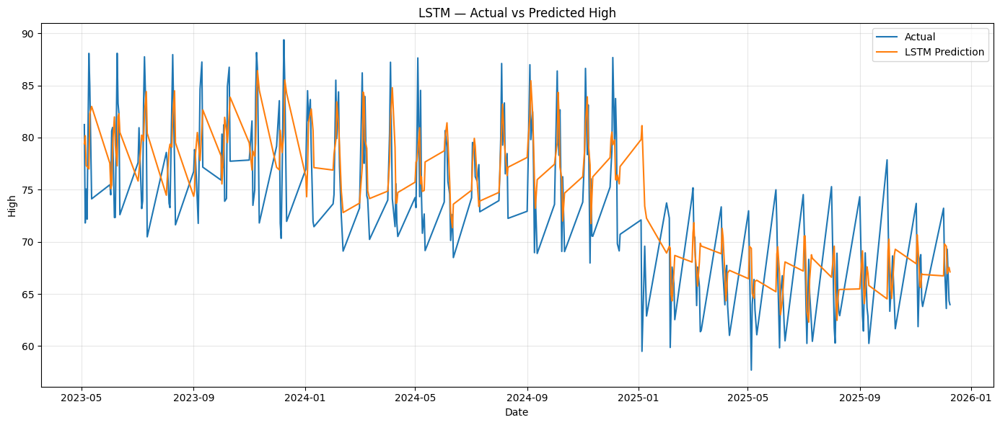

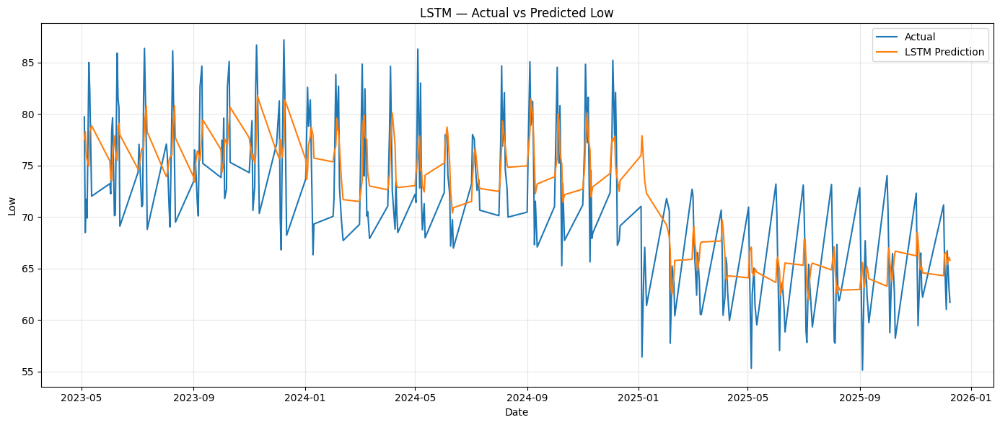

In [12]:
# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

for target in TARGETS:

    _, _, metrics, prediction_df = (
        lstm_results[target]
    )

    plt.figure(figsize=(14, 6))

    plt.plot(
        prediction_df["Date"],
        prediction_df["Actual"],
        label="Actual"
    )

    plt.plot(
        prediction_df["Date"],
        prediction_df["Predicted"],
        label="LSTM Prediction"
    )

    plt.xlabel("Date")
    plt.ylabel(target)

    plt.title(
        f"LSTM — Actual vs Predicted {target}"
    )

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Actual_vs_Predicted.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

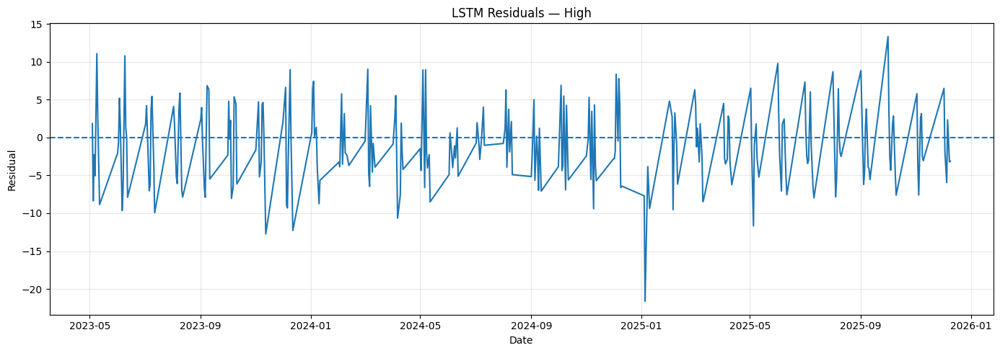

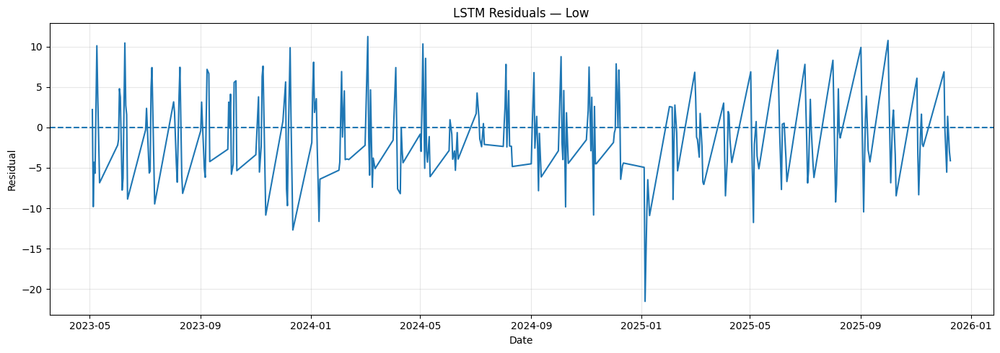

In [13]:
# ============================================================
# RESIDUAL ANALYSIS
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    prediction_df["Residual"] = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(14, 5))

    plt.plot(
        prediction_df["Date"],
        prediction_df["Residual"]
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")
    plt.ylabel("Residual")

    plt.title(
        f"LSTM Residuals — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Residuals.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

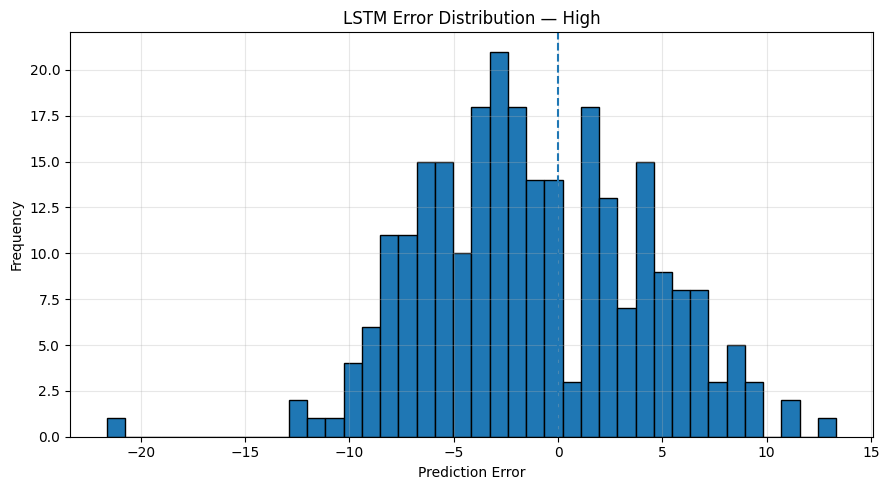

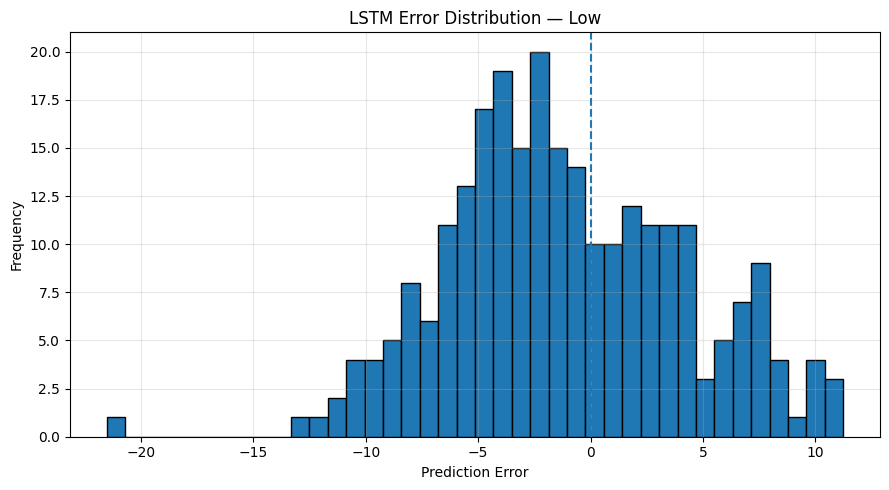

In [14]:
# ============================================================
# ERROR DISTRIBUTION
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    errors = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(9, 5))

    plt.hist(
        errors,
        bins=40,
        edgecolor="black"
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.xlabel("Prediction Error")
    plt.ylabel("Frequency")

    plt.title(
        f"LSTM Error Distribution — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Error_Distribution.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

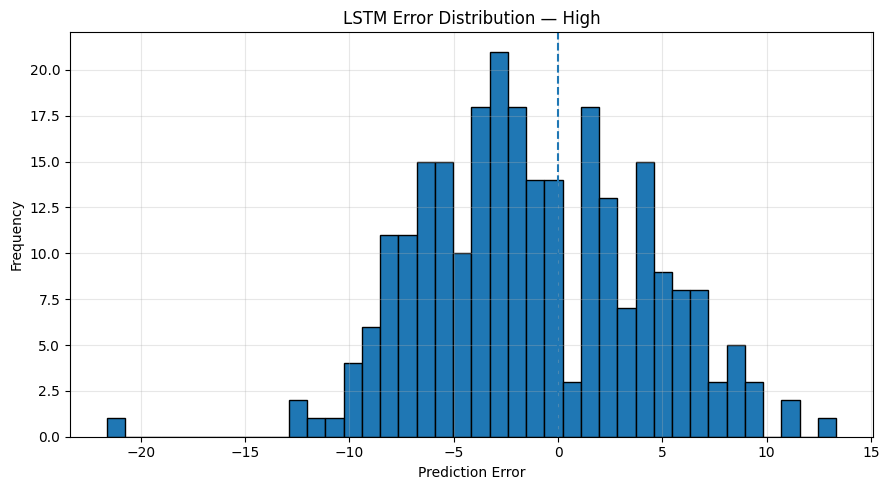

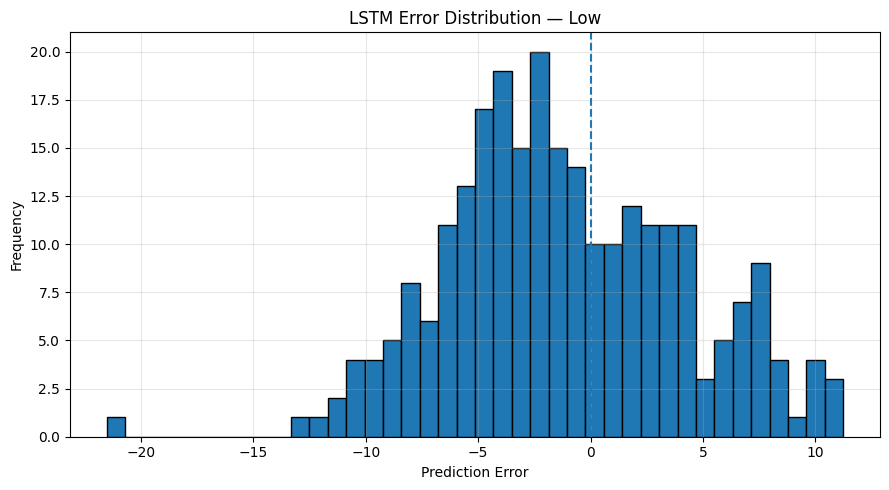

In [15]:
# ============================================================
# ERROR DISTRIBUTION
# ============================================================

for target in TARGETS:

    _, _, _, prediction_df = (
        lstm_results[target]
    )

    errors = (
        prediction_df["Actual"]
        -
        prediction_df["Predicted"]
    )

    plt.figure(figsize=(9, 5))

    plt.hist(
        errors,
        bins=40,
        edgecolor="black"
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.xlabel("Prediction Error")
    plt.ylabel("Frequency")

    plt.title(
        f"LSTM Error Distribution — {target}"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = os.path.join(
        GRAPH_DIR,
        f"LSTM_{target}_Error_Distribution.png"
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [4]:
DATA_PATH = "crude_oil_2007_to_present.csv"

df=pd.read_csv(DATA_PATH)

TensorFlow: 2.17.0
Seed: 42
Original shape: (4746, 6)


RUNNING DF1
2007 - 2011
Regime observations: 499
Train: 348
Validation: 75
Test: 75
X_train: (323, 25, 4)
X_val: (75, 25, 4)
X_test: (75, 25, 4)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 25, 128)        │        35,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 117ms/step - loss: 0.0539 - val_loss: 0.0168 - learning_rate: 0.0010
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0303 - val_loss: 0.0123 - learning_rate: 0.0010
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0294 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0249 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0255 - val_loss: 0.0026 - learning_rate: 0.0010
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0232 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0229 - val_loss: 0.0027 - learning_rate: 0.0010
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0223 - val_loss: 0.0029 - learning_rate: 0.0010
Epoch 9/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0218 - val_loss: 0.0026 - learning_rate: 0.0010
Epoch 10

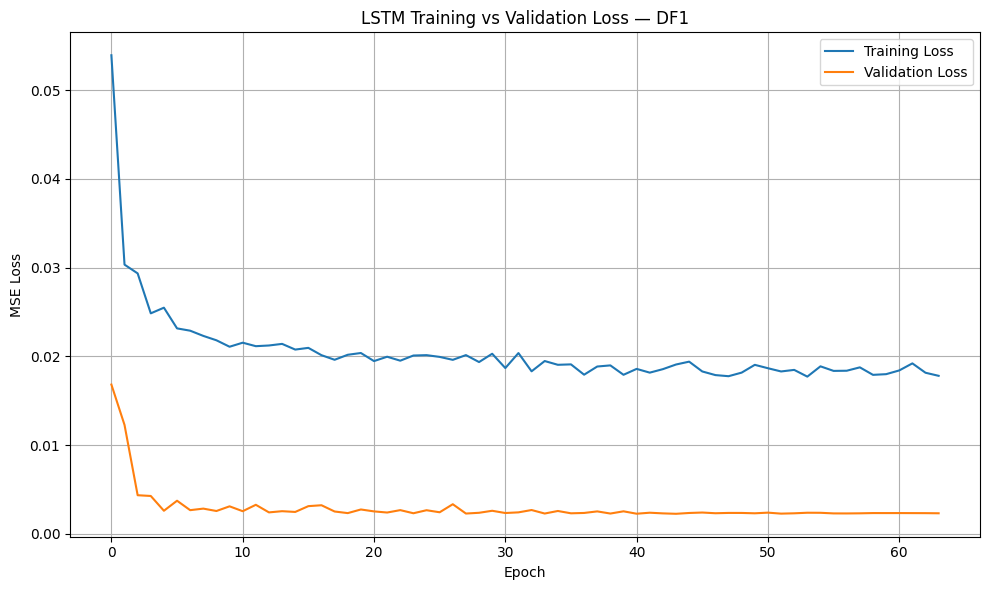

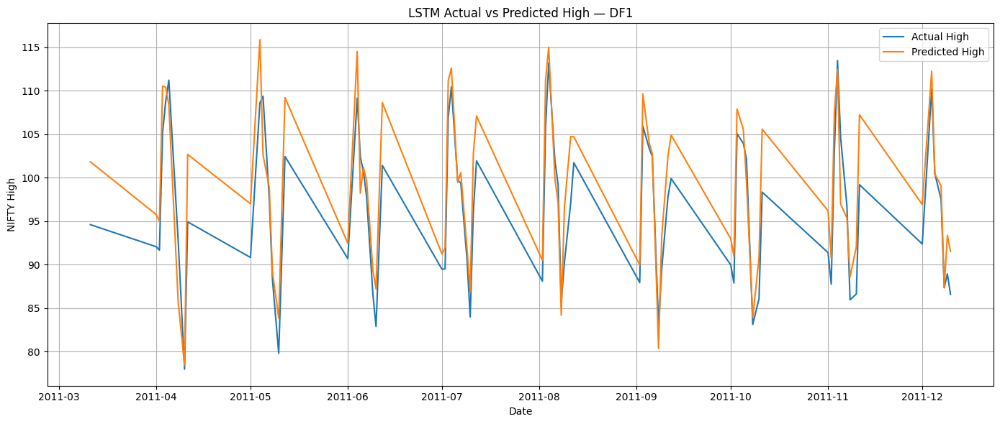

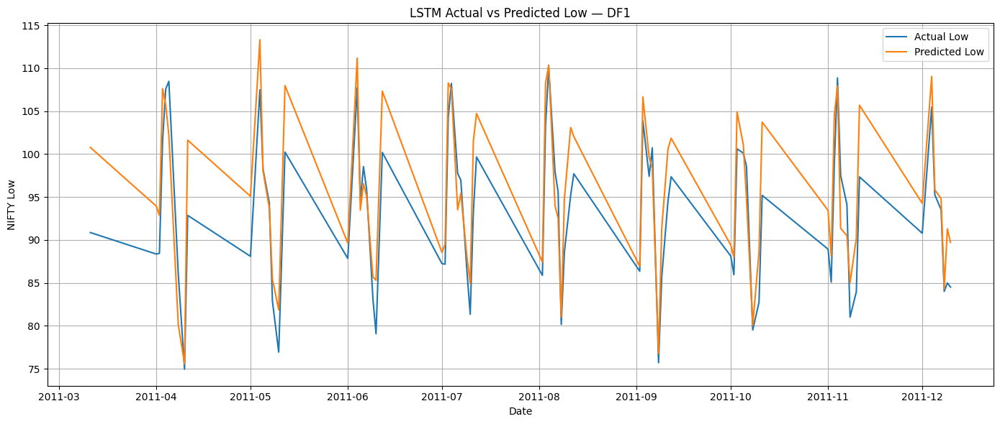

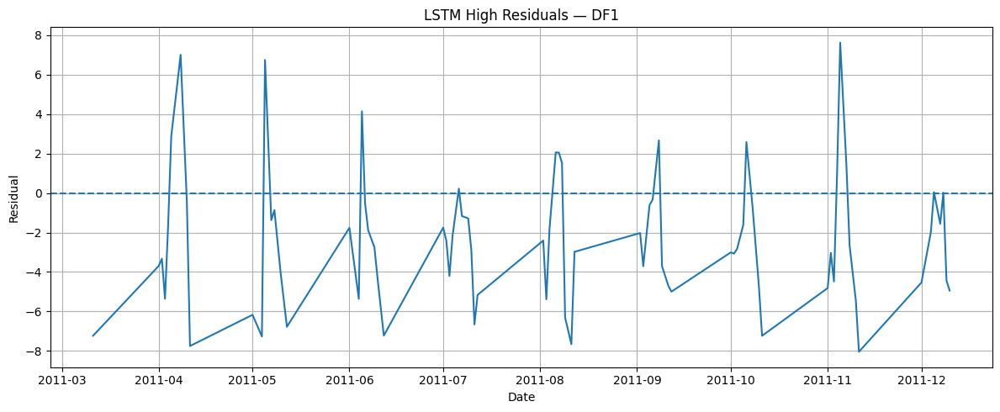

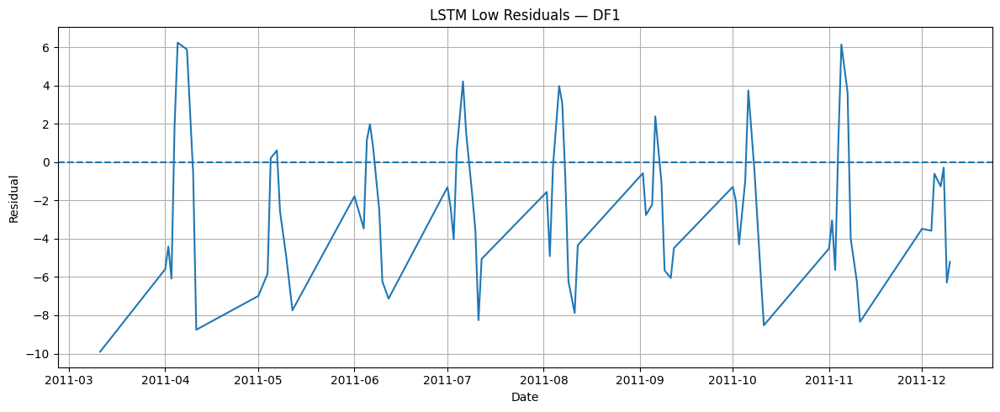

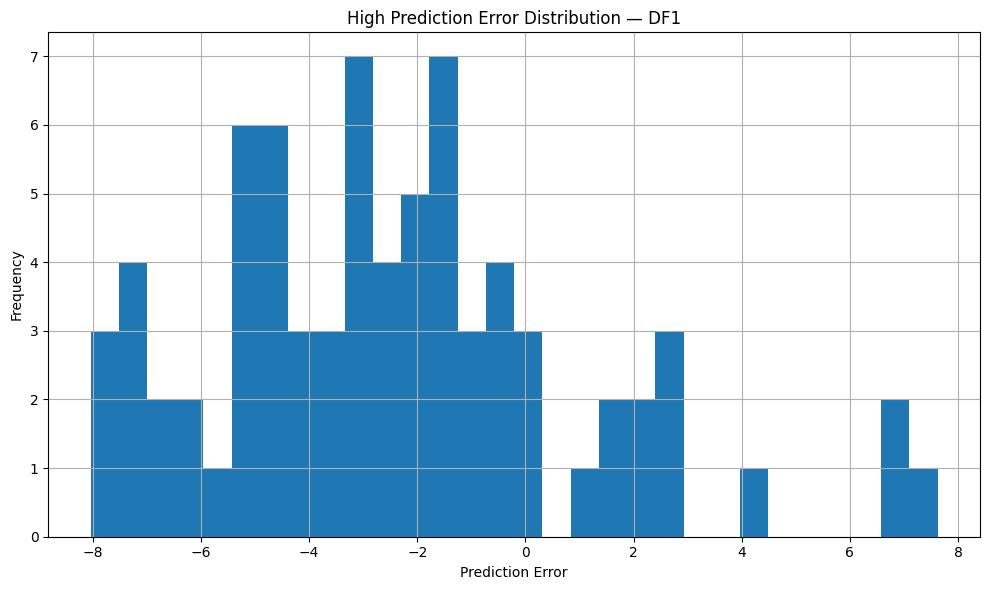

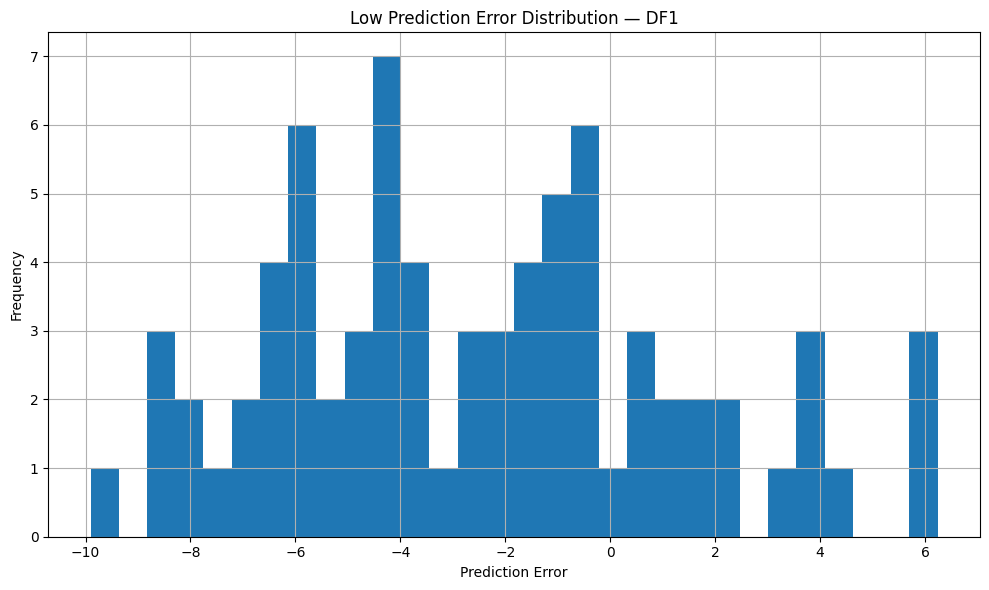


DF1 completed.


RUNNING DF2
2012 - 2019
Regime observations: 794
Train: 555
Validation: 119
Test: 119
X_train: (530, 25, 4)
X_val: (119, 25, 4)
X_test: (119, 25, 4)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_2 (Bidirectional) │ (None, 25, 128)        │        35,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 80ms/step - loss: 0.0629 - val_loss: 0.0399 - learning_rate: 0.0010
Epoch 2/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0845 - val_loss: 0.0385 - learning_rate: 0.0010
Epoch 3/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0263 - val_loss: 0.0117 - learning_rate: 0.0010
Epoch 4/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0310 - val_loss: 0.0099 - learning_rate: 0.0010
Epoch 5/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0201 - val_loss: 0.0083 - learning_rate: 0.0010
Epoch 6/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0197 - val_loss: 0.0078 - learning_rate: 0.0010
Epoch 7/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0188 - val_loss: 0.0079 - learning_rate: 0.0010
Epoch 8/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0184 - val_loss: 0.0078 - learning_rate: 0.0010
Epoch 9/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0182 - val_loss: 0.0078 - learning_rate: 0.0010
Epoch 10/2

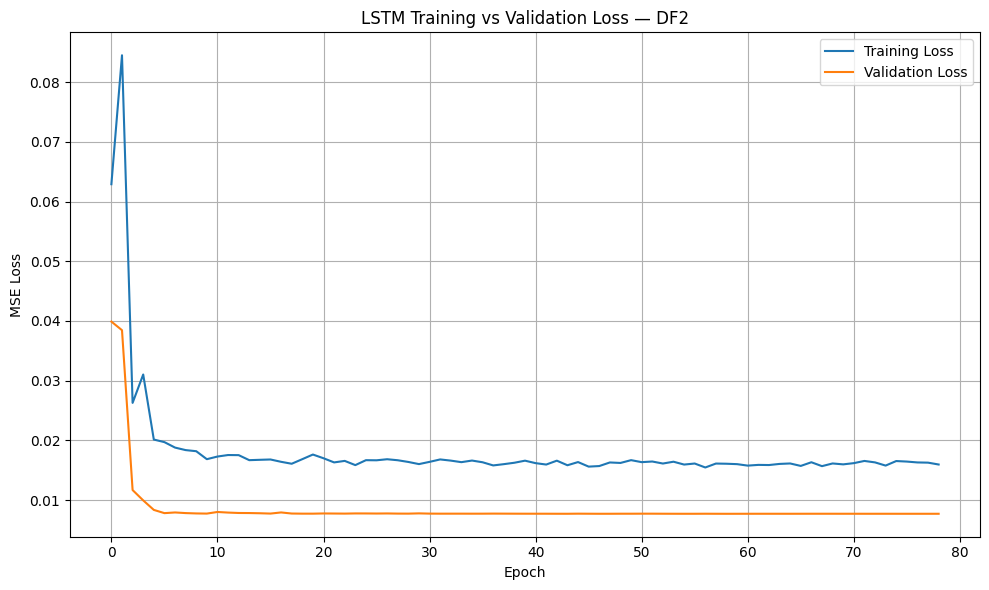

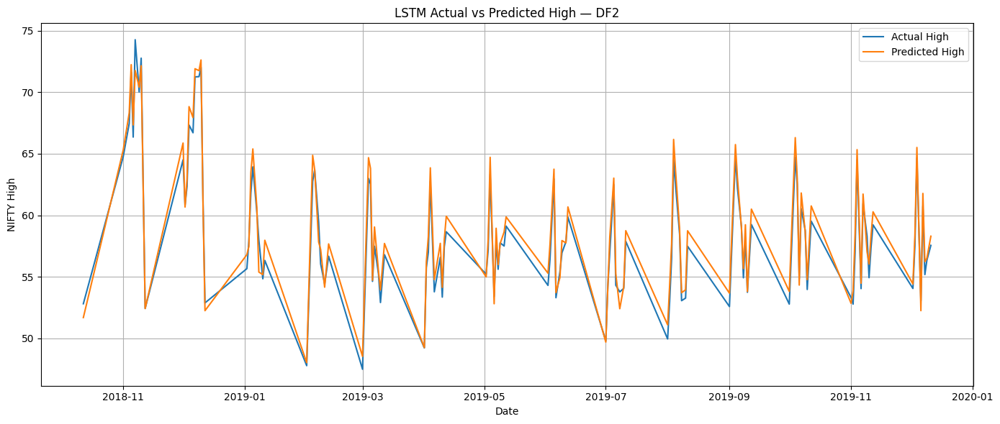

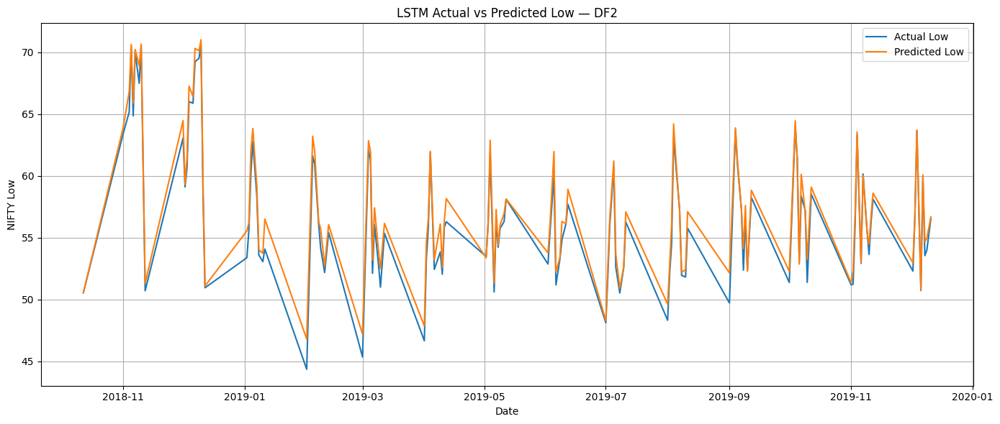

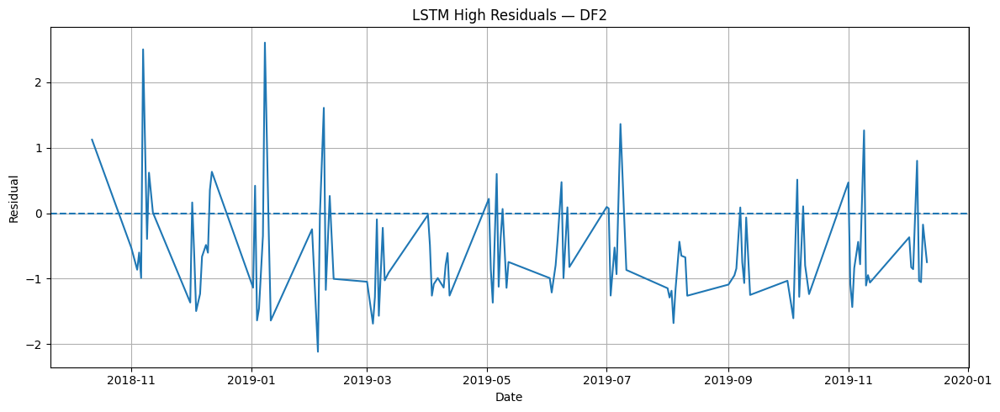

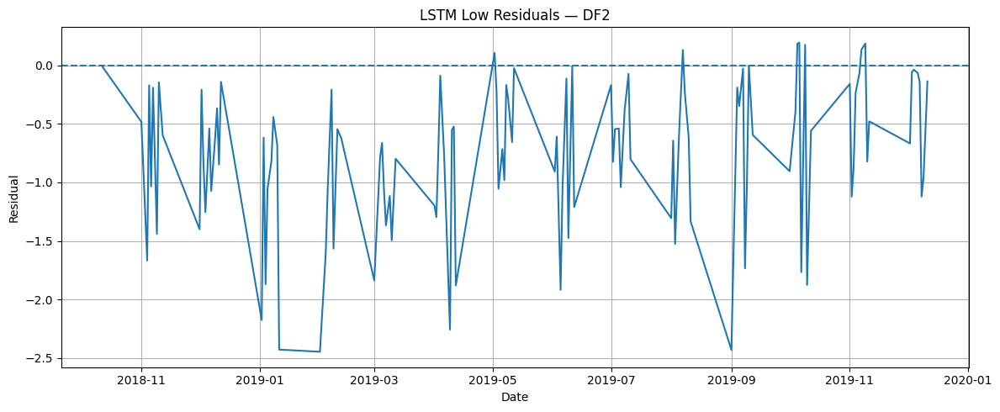

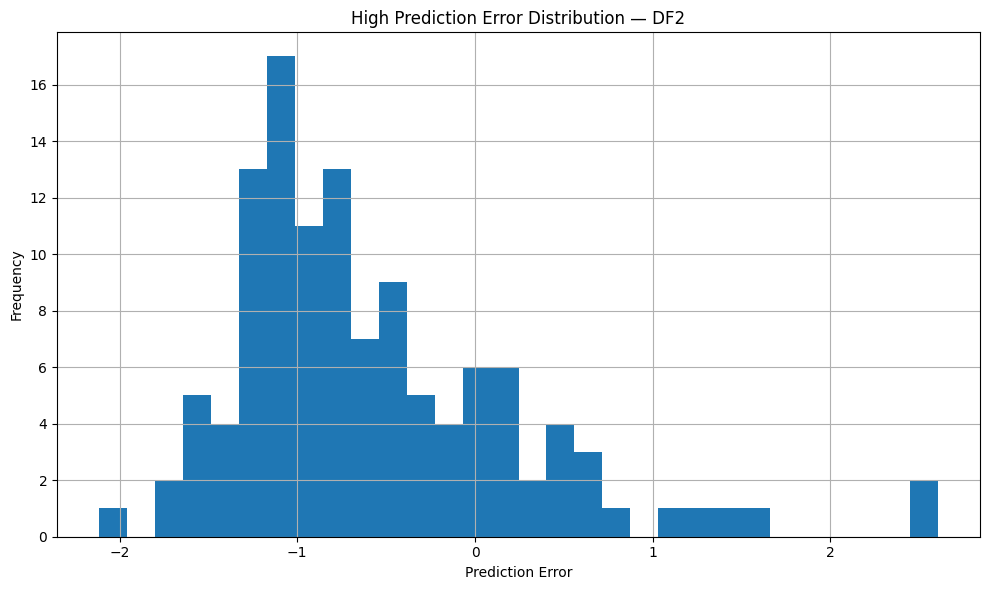

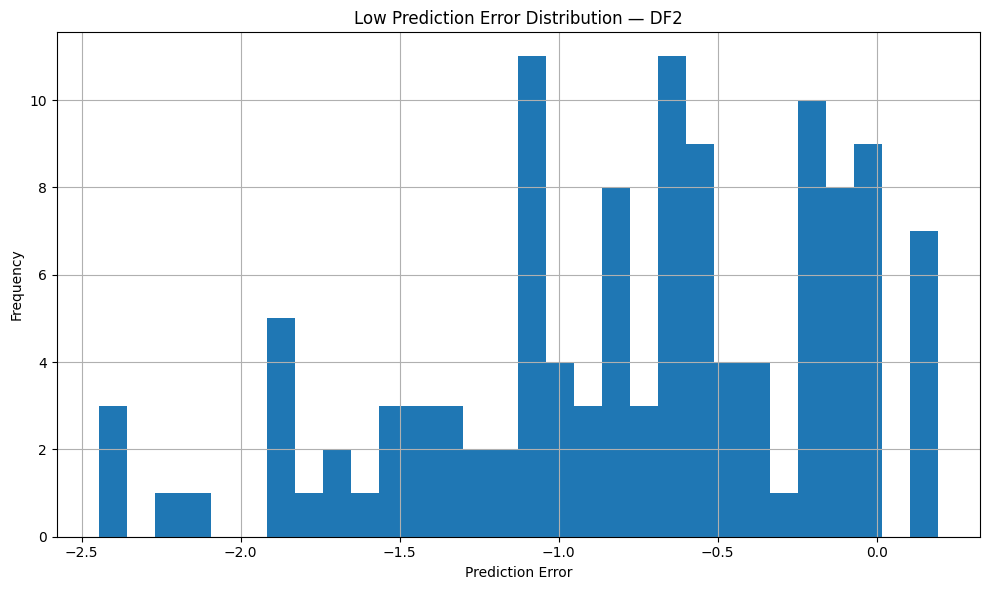


DF2 completed.


RUNNING DF3
2020 - 2022
Regime observations: 298
Train: 207
Validation: 45
Test: 45
X_train: (182, 25, 4)
X_val: (45, 25, 4)
X_test: (45, 25, 4)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_4 (Bidirectional) │ (None, 25, 128)        │        35,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 215ms/step - loss: 0.1202 - val_loss: 0.0973 - learning_rate: 0.0010
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0756 - val_loss: 0.0842 - learning_rate: 0.0010
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0393 - val_loss: 0.0221 - learning_rate: 0.0010
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0476 - val_loss: 0.0290 - learning_rate: 0.0010
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0440 - val_loss: 0.0465 - learning_rate: 0.0010
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0389 - val_loss: 0.0396 - learning_rate: 0.0010
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0343 - val_loss: 0.0238 - learning_rate: 0.0010
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0334 - val_loss: 0.0209 - learning_rate: 0.0010
Epoch 9/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0331 - val_loss: 0.0226 - learning_rate: 0.0010
Epoch 10/200
6/6 ━━━━━━━━━━

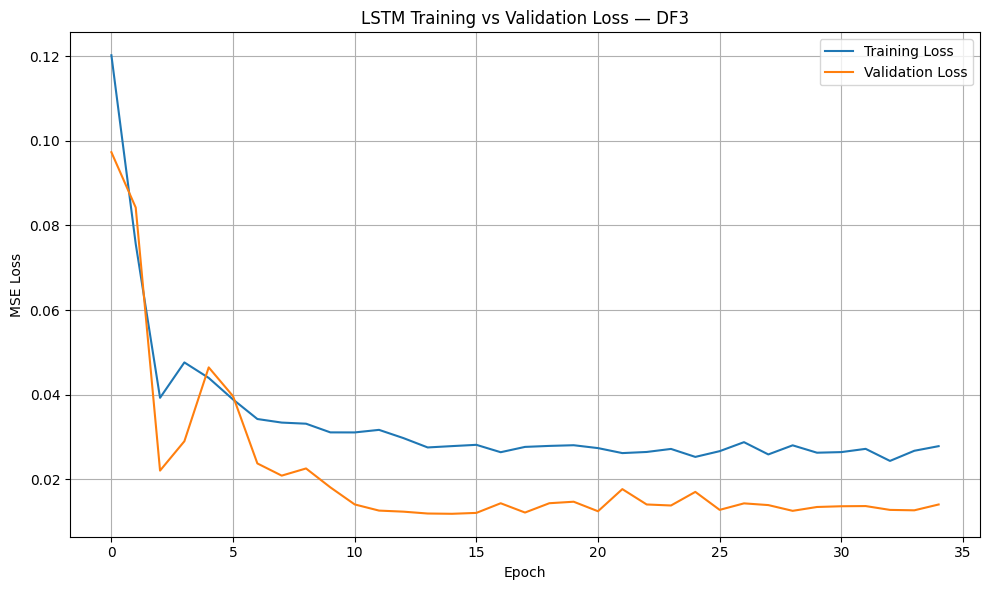

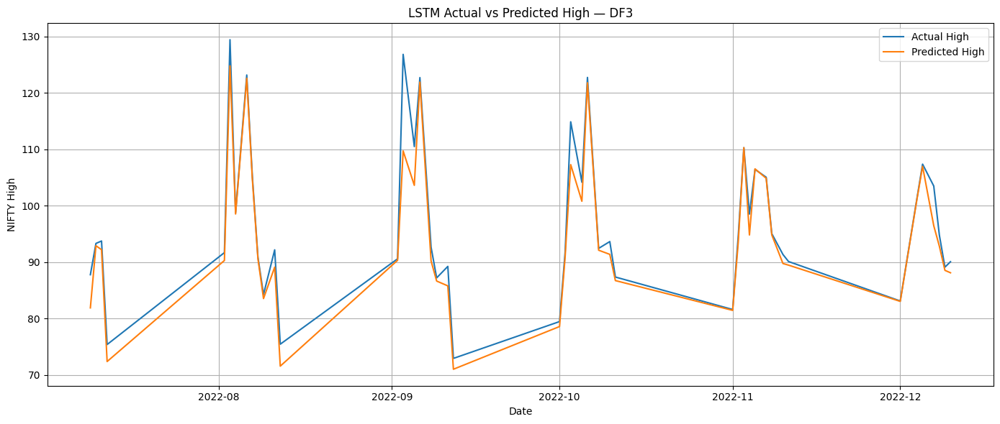

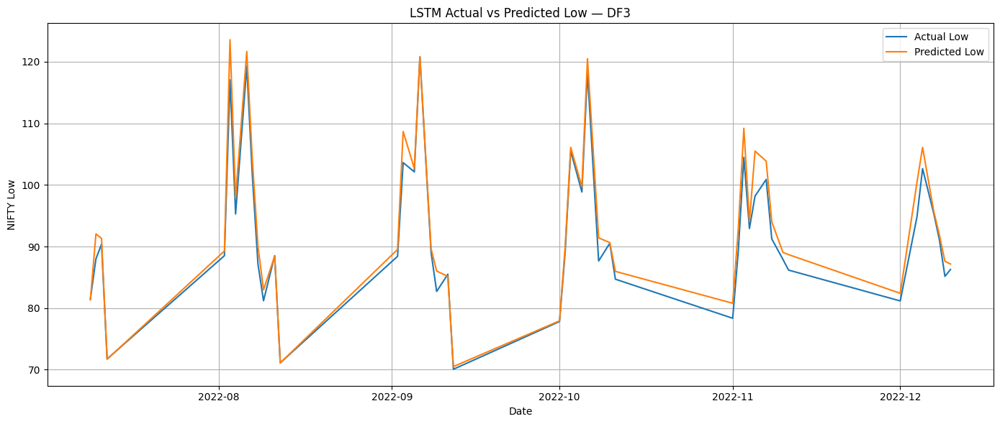

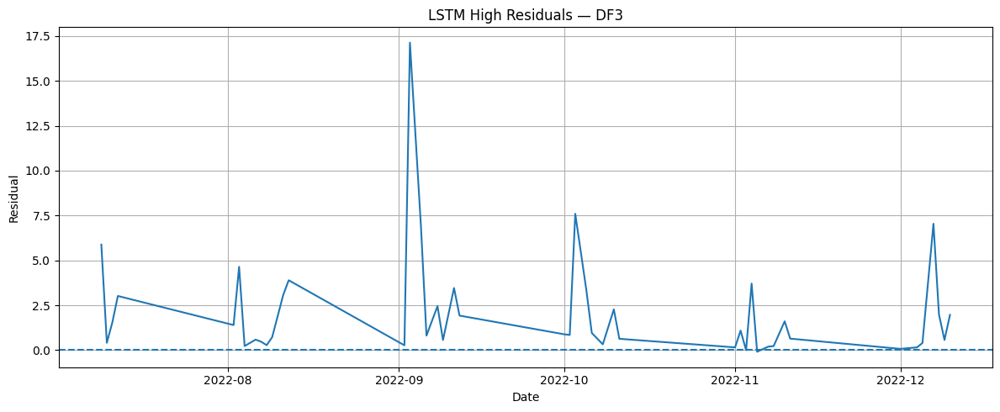

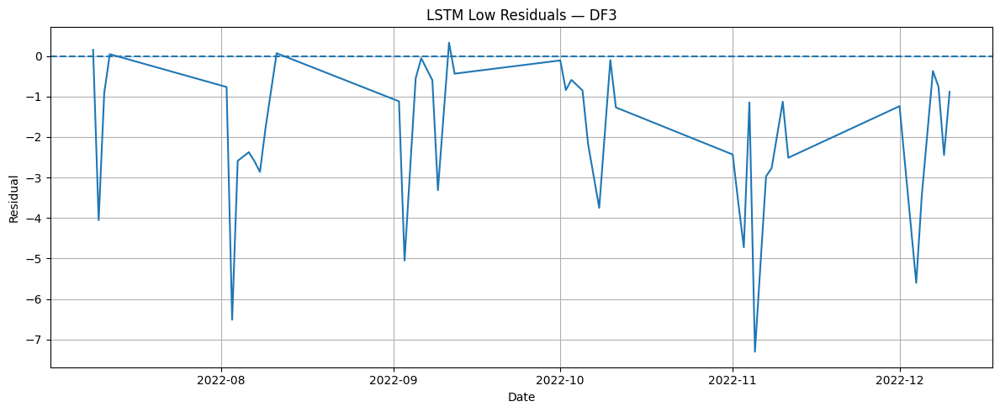

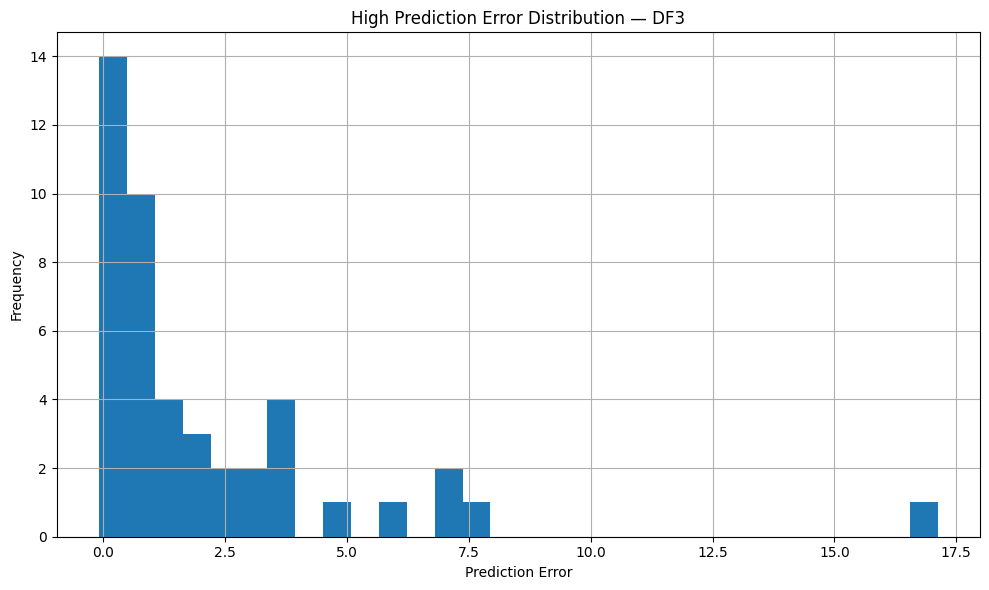

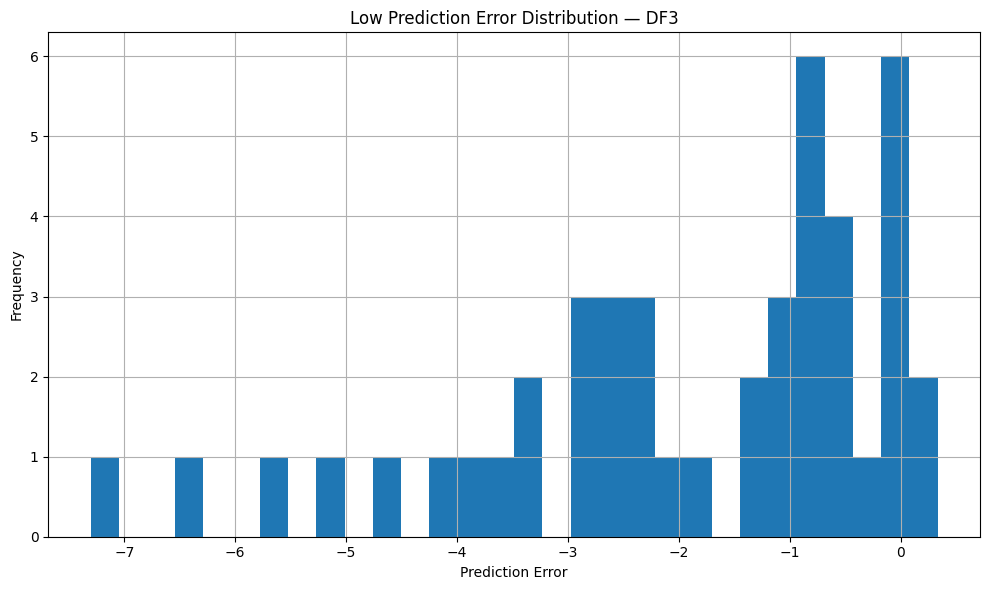


DF3 completed.


RUNNING DF4
2023 - 2025
Regime observations: 288
Train: 200
Validation: 43
Test: 44
X_train: (175, 25, 4)
X_val: (43, 25, 4)
X_test: (44, 25, 4)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_6 (Bidirectional) │ (None, 25, 128)        │        35,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_7 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 209ms/step - loss: 0.1568 - val_loss: 0.1761 - learning_rate: 0.0010
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0786 - val_loss: 0.1978 - learning_rate: 0.0010
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0560 - val_loss: 0.2105 - learning_rate: 0.0010
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0584 - val_loss: 0.1937 - learning_rate: 0.0010
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0540 - val_loss: 0.1824 - learning_rate: 0.0010
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0549 - val_loss: 0.1858 - learning_rate: 0.0010
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0526 - val_loss: 0.1813 - learning_rate: 0.0010
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0505 - val_loss: 0.1735 - learning_rate: 0.0010
Epoch 9/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.0506 - val_loss: 0.1723 - learning_rate: 0.0010
Epoch 10/200
6/6 ━━━━━━━━━━

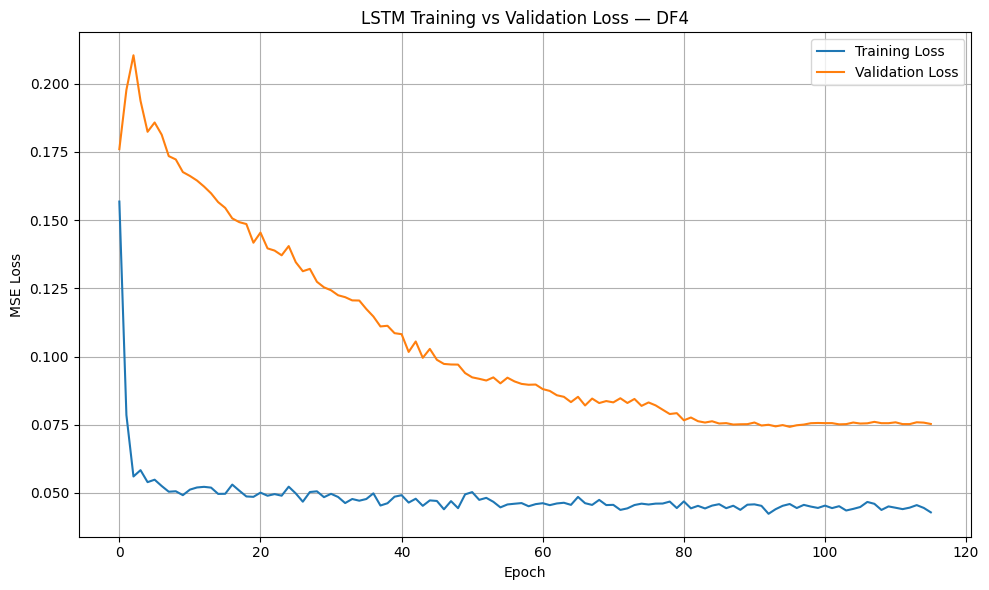

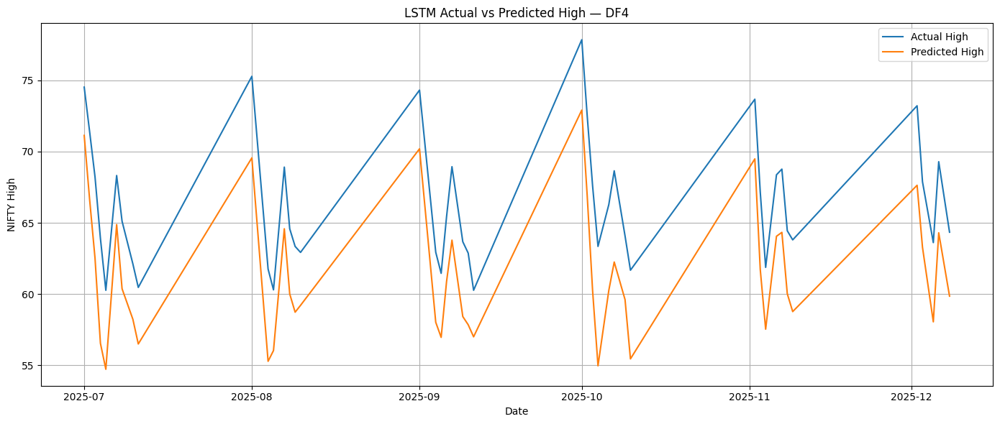

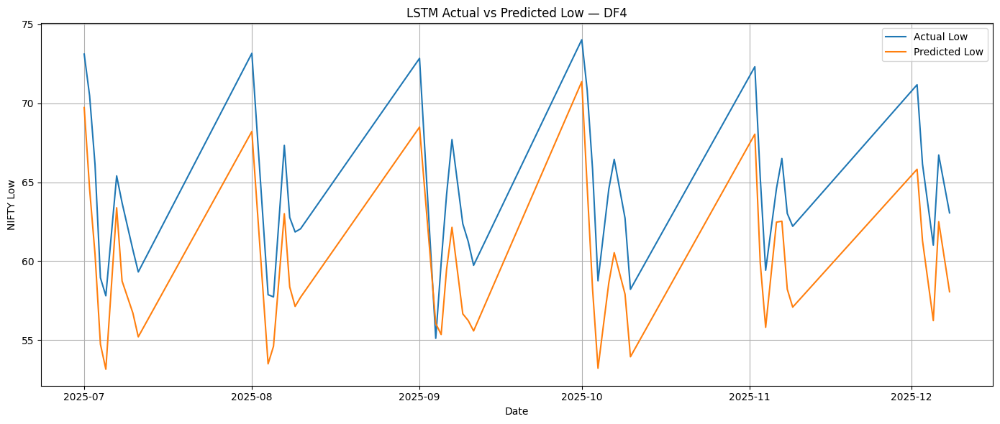

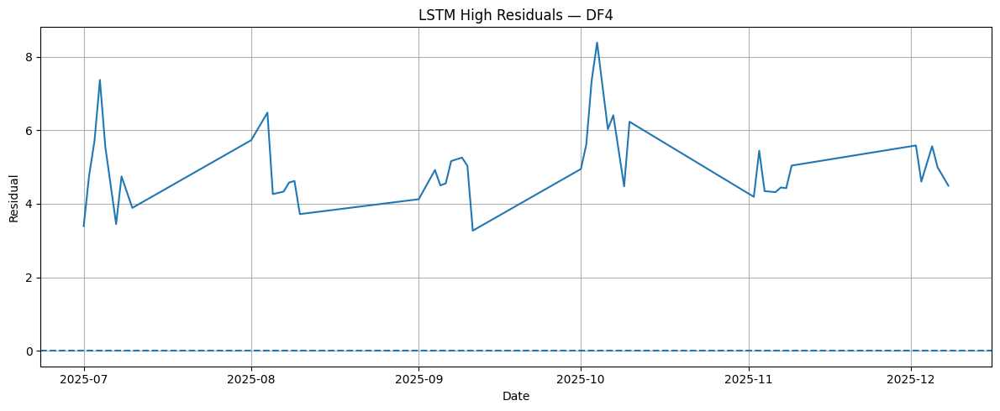

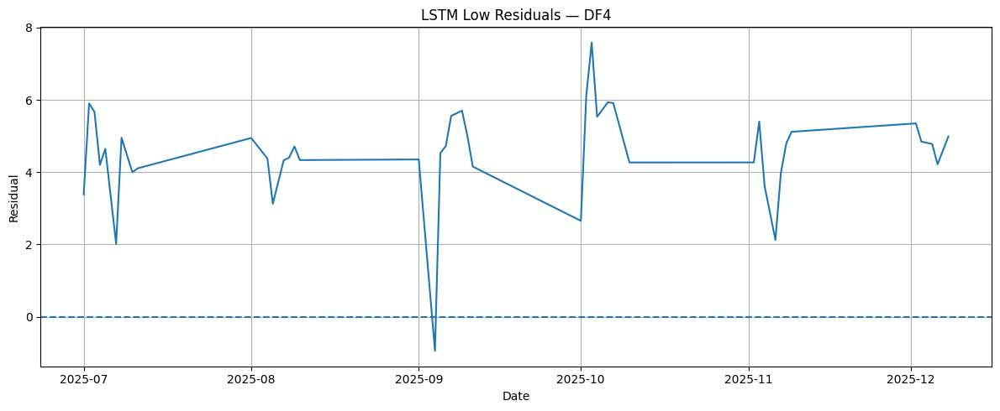

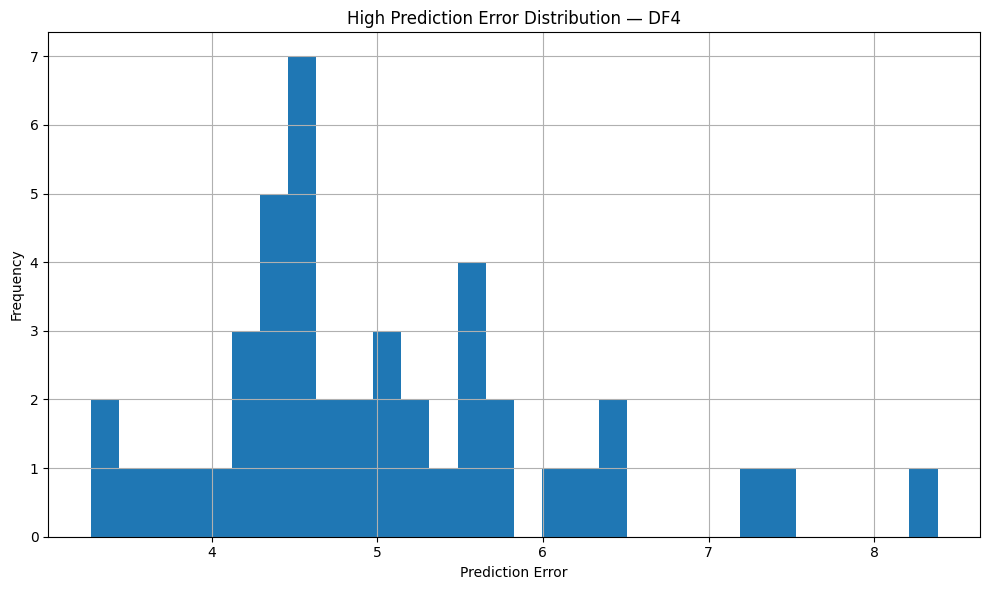

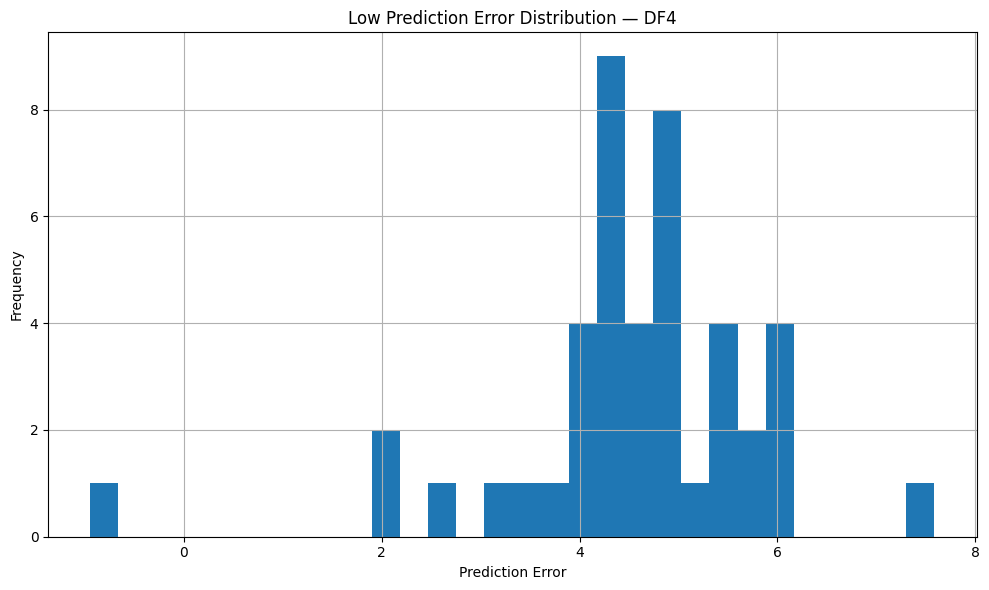


DF4 completed.


FINAL REGIME-WISE LSTM RESULTS
Regime  High_MAE  High_RMSE   High_R2  High_MAPE  Low_MAE  Low_RMSE   Low_R2  Low_MAPE  Train_Observations  Validation_Observations  Test_Observations
   DF1  3.535893   4.181438  0.768099   3.676067 3.798177  4.537913 0.732326  4.099583                 323                       75                 75
   DF2  0.858282   0.996022  0.965696   1.461081 0.782242  0.991464 0.967541  1.411290                 530                      119                119
   DF3  2.139994   3.686658  0.925984   2.125937 1.982614  2.683377 0.949116  2.093567                 182                       45                 45
   DF4  5.005091   5.116129 -0.270161   7.578329 4.553822  4.699481 0.046080  7.102317                 175                       43                 44

Results saved to:
LSTM_Regime_Results


In [5]:
# ============================================================
# CRUDE OIL — REGIME-WISE LSTM
# DF1: 2007-2010
# DF2: 2011-2019
# DF3: 2020-2021
# DF4: 2022-Latest
#
# Each regime is trained and evaluated independently.
# Target:
#   Next-Day High / Current-Day Close
#   Next-Day Low  / Current-Day Close
#
# Split:
#   70% Train
#   15% Validation
#   15% Test
#
# Lookback:
#   25 trading days
# ============================================================

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout


# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass



LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 200
BATCH_SIZE = 32

OUTPUT_DIR = "LSTM_Regime_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)


# ============================================================
# 2. LOAD DATA
# ============================================================


print("Original shape:", df.shape)

# ------------------------------------------------------------
# Find date column
# ------------------------------------------------------------

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Datetime",
    "datetime"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    raise ValueError(
        "Could not find Date column. "
        "Available columns are:\n"
        + str(df.columns.tolist())
    )

df[date_column] = pd.to_datetime(df[date_column], errors="coerce")

df = df.dropna(subset=[date_column])

df = df.sort_values(date_column).reset_index(drop=True)


# ============================================================
# 3. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Open",
    "High",
    "Low",
    "Close"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )


# ============================================================
# 4. CLEAN NUMERIC DATA
# ============================================================

for col in required_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=required_columns
).reset_index(drop=True)


# ============================================================
# 5. DEFINE REGIMES
# ============================================================

df["Year"] = df[date_column].dt.year

regimes = {

    "DF1": {
        "start": 2007,
        "end": 2011
    },

    "DF2": {
        "start": 2012,
        "end": 2019
    },

    "DF3": {
        "start": 2020,
        "end": 2022
    },

    "DF4": {
        "start": 2023,
        "end": df["Year"].max()
    }
}


# ============================================================
# 6. MODEL FUNCTION
# ============================================================

def build_lstm():

    
    model = Sequential([
    Bidirectional(
        LSTM(64, return_sequences=True),
        input_shape=(LOOKBACK, 4)
    ),
    Dropout(0.20),

    Bidirectional(
        LSTM(32)
    ),
    Dropout(0.20),

    Dense(16, activation="relu"),
    Dense(2)
])    

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model


# ============================================================
# 7. METRICS FUNCTION
# ============================================================

def calculate_metrics(
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(actual) < 1e-8,
        1e-8,
        np.abs(actual)
    )

    mape = np.mean(
        np.abs(
            (actual - predicted)
            / denominator
        )
    ) * 100

    return mae, rmse, r2, mape


# ============================================================
# 8. STORE ALL RESULTS
# ============================================================

all_results = []


# ============================================================
# 9. RUN EACH REGIME SEPARATELY
# ============================================================

for regime_name, period in regimes.items():

    print("\n")
    print("=" * 70)
    print(f"RUNNING {regime_name}")
    print(
        f"{period['start']} - {period['end']}"
    )
    print("=" * 70)


    # --------------------------------------------------------
    # Extract regime
    # --------------------------------------------------------

    regime_df = df[
        (df["Year"] >= period["start"]) &
        (df["Year"] <= period["end"])
    ].copy()

    regime_df = regime_df.reset_index(drop=True)

    print(
        "Regime observations:",
        len(regime_df)
    )


    # --------------------------------------------------------
    # Check enough data
    # --------------------------------------------------------

    if len(regime_df) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            f"insufficient observations."
        )

        continue


    # --------------------------------------------------------
    # FEATURES
    #
    # We use OHLC from the previous 25 days.
    # --------------------------------------------------------

    features = [
        "Open",
        "High",
        "Low",
        "Close"
    ]

    X_raw = regime_df[
        features
    ].values


    # --------------------------------------------------------
    # TARGET
    #
    # Next-day High / current Close
    # Next-day Low  / current Close
    #
    # y[i] corresponds to day i+1.
    # --------------------------------------------------------

    high_target = (
        regime_df["High"].shift(-1)
        / regime_df["Close"]
    )

    low_target = (
        regime_df["Low"].shift(-1)
        / regime_df["Close"]
    )

    y_raw = np.column_stack([
        high_target.values,
        low_target.values
    ])


    # --------------------------------------------------------
    # Remove final row because it has no next-day target
    # --------------------------------------------------------

    valid_mask = ~np.isnan(y_raw).any(axis=1)

    X_raw = X_raw[valid_mask]
    y_raw = y_raw[valid_mask]

    close_current = regime_df[
        "Close"
    ].values[valid_mask]

    dates = regime_df[
        date_column
    ].values[valid_mask]


    # ========================================================
    # 10. CHRONOLOGICAL SPLIT
    # ========================================================

    n = len(X_raw)

    train_end = int(
        n * TRAIN_RATIO
    )

    val_end = int(
        n * (TRAIN_RATIO + VAL_RATIO)
    )

    print(
        "Train:",
        train_end
    )

    print(
        "Validation:",
        val_end - train_end
    )

    print(
        "Test:",
        n - val_end
    )


    # ========================================================
    # 11. SCALE — TRAIN ONLY
    # ========================================================

    scaler_X = MinMaxScaler()

    scaler_y = MinMaxScaler()


    scaler_X.fit(
        X_raw[:train_end]
    )

    scaler_y.fit(
        y_raw[:train_end]
    )


    X_scaled = scaler_X.transform(
        X_raw
    )

    y_scaled = scaler_y.transform(
        y_raw
    )


    # ========================================================
    # 12. CREATE SEQUENCES
    # ========================================================

    X_sequences = []
    y_sequences = []
    sequence_indices = []

    for i in range(
        LOOKBACK,
        len(X_scaled)
    ):

        X_sequences.append(
            X_scaled[
                i - LOOKBACK:i
            ]
        )

        y_sequences.append(
            y_scaled[i]
        )

        sequence_indices.append(i)


    X_sequences = np.array(
        X_sequences
    )

    y_sequences = np.array(
        y_sequences
    )

    sequence_indices = np.array(
        sequence_indices
    )


    # ========================================================
    # 13. SPLIT SEQUENCES
    # ========================================================

    train_mask = (
        sequence_indices < train_end
    )

    val_mask = (
        (sequence_indices >= train_end) &
        (sequence_indices < val_end)
    )

    test_mask = (
        sequence_indices >= val_end
    )


    X_train = X_sequences[
        train_mask
    ]

    y_train = y_sequences[
        train_mask
    ]

    X_val = X_sequences[
        val_mask
    ]

    y_val = y_sequences[
        val_mask
    ]

    X_test = X_sequences[
        test_mask
    ]

    y_test = y_sequences[
        test_mask
    ]


    print(
        "X_train:",
        X_train.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "X_test:",
        X_test.shape
    )


    # ========================================================
    # 14. BUILD MODEL
    # ========================================================

    model = build_lstm()

    model.summary()


    # ========================================================
    # 15. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=20,

        restore_best_weights=True,

        verbose=1
    )


    reduce_lr = ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=8,

        min_lr=1e-6,

        verbose=1
    )


    # ========================================================
    # 16. TRAIN
    # ========================================================

    history = model.fit(

        X_train,

        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        shuffle=False,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        verbose=1
    )


    # ========================================================
    # 17. PREDICT TEST
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 18. INVERSE TRANSFORM
    # ========================================================

    y_pred_ratio = scaler_y.inverse_transform(
        y_pred_scaled
    )

    y_test_ratio = scaler_y.inverse_transform(
        y_test
    )


    # ========================================================
    # 19. GET TEST CLOSE VALUES
    # ========================================================

    test_indices = sequence_indices[
        test_mask
    ]

    test_close = close_current[
        test_indices
    ]

    test_dates = dates[
        test_indices
    ]


    # ========================================================
    # 20. RECONSTRUCT ABSOLUTE HIGH / LOW
    # ========================================================

    predicted_high = (
        y_pred_ratio[:, 0]
        * test_close
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * test_close
    )


    actual_high = regime_df[
        "High"
    ].values[test_indices]

    actual_low = regime_df[
        "Low"
    ].values[test_indices]


    # ========================================================
    # 21. METRICS
    # ========================================================

    high_mae, high_rmse, high_r2, high_mape = \
        calculate_metrics(
            actual_high,
            predicted_high
        )


    low_mae, low_rmse, low_r2, low_mape = \
        calculate_metrics(
            actual_low,
            predicted_low
        )


    print("\n")
    print("=" * 60)
    print(f"{regime_name} RESULTS")
    print("=" * 60)

    print("\nHIGH")
    print(
        f"MAE  : {high_mae:.4f}"
    )
    print(
        f"RMSE : {high_rmse:.4f}"
    )
    print(
        f"R²   : {high_r2:.4f}"
    )
    print(
        f"MAPE : {high_mape:.4f}%"
    )

    print("\nLOW")
    print(
        f"MAE  : {low_mae:.4f}"
    )
    print(
        f"RMSE : {low_rmse:.4f}"
    )
    print(
        f"R²   : {low_r2:.4f}"
    )
    print(
        f"MAPE : {low_mape:.4f}%"
    )


    # ========================================================
    # 22. SAVE METRICS
    # ========================================================

    all_results.append({

        "Regime": regime_name,

        "High_MAE": high_mae,
        "High_RMSE": high_rmse,
        "High_R2": high_r2,
        "High_MAPE": high_mape,

        "Low_MAE": low_mae,
        "Low_RMSE": low_rmse,
        "Low_R2": low_r2,
        "Low_MAPE": low_mape,

        "Train_Observations": len(X_train),

        "Validation_Observations": len(X_val),

        "Test_Observations": len(X_test)
    })


    # ========================================================
    # 23. SAVE PREDICTIONS
    # ========================================================

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "Actual_High_Ratio":
            y_test_ratio[:, 0],

        "Predicted_High_Ratio":
            y_pred_ratio[:, 0],

        "Actual_Low_Ratio":
            y_test_ratio[:, 1],

        "Predicted_Low_Ratio":
            y_pred_ratio[:, 1],

        "Close_t":
            test_close
    })


    prediction_path = os.path.join(
        OUTPUT_DIR,
        f"{regime_name}_Predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    # ========================================================
    # 24. TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")

    plt.title(
        f"LSTM Training vs Validation Loss — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Loss.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 25. ACTUAL VS PREDICTED — HIGH
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_high,
        label="Actual High"
    )

    plt.plot(
        test_dates,
        predicted_high,
        label="Predicted High"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY High")

    plt.title(
        f"LSTM Actual vs Predicted High — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 26. ACTUAL VS PREDICTED — LOW
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        test_dates,
        predicted_low,
        label="Predicted Low"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY Low")

    plt.title(
        f"LSTM Actual vs Predicted Low — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 27. HIGH RESIDUALS
    # ========================================================

    high_residuals = (
        actual_high -
        predicted_high
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        high_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM High Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 28. LOW RESIDUALS
    # ========================================================

    low_residuals = (
        actual_low -
        predicted_low
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        low_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM Low Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 29. ERROR DISTRIBUTIONS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        high_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"High Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        low_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"Low Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 30. SAVE MODEL
    # ========================================================

    model.save(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_LSTM.keras"
        )
    )

    print(
        f"\n{regime_name} completed."
    )


# ============================================================
# 31. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 80)
print("FINAL REGIME-WISE LSTM RESULTS")
print("=" * 80)

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# 32. SAVE FINAL RESULTS
# ============================================================

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.csv"
    ),
    index=False
)

results_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.xlsx"
    ),
    index=False
)


print("\nResults saved to:")
print(OUTPUT_DIR)

TensorFlow: 2.17.0
Seed: 42

Original dataframe shape:
(1879, 8)

Original columns:
['Date', 'Close', 'High', 'Low', 'Open', 'Volume', 'Regime', 'Year']

Invalid dates: 0

Missing OHLC values before cleaning:
Open     0
High     0
Low      0
Close    0
dtype: int64


CLEAN DATASET INFORMATION
Start date: 2007-01-02 00:00:00
End date: 2025-12-09 00:00:00
Total observations: 1879


REGIME DISTRIBUTION
Regime
DF1    399
DF2    894
DF3    198
DF4    388
Name: count, dtype: int64
DF1: 399 observations
DF2: 894 observations
DF3: 198 observations
DF4: 388 observations


REGIMES AFTER TARGET CREATION
Regime
DF1    399
DF2    894
DF3    198
DF4    387
Name: count, dtype: int64



##########################################################################################
STARTING DF1
##########################################################################################

DF1 observations: 399
Train observations: 279
Validation observations: 60
Test observations: 60

Sequence shapes:
X_train: (

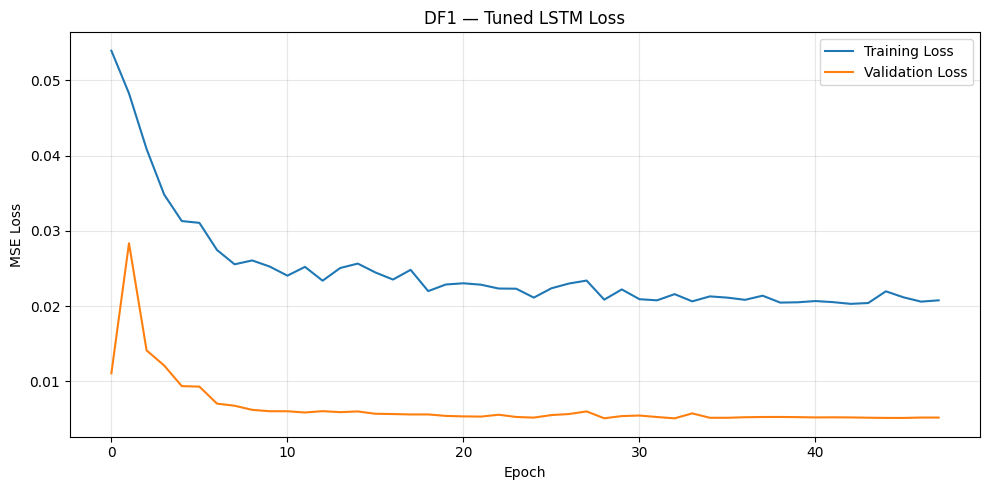



FINAL TEST RESULTS — DF1
High MAE  : 3.2619
High RMSE : 3.7894
High R²   : 0.4797
High MAPE : 4.0426%

Low MAE   : 2.1083
Low RMSE  : 2.4811
Low R²    : 0.7983
Low MAPE  : 2.7060%



##########################################################################################
STARTING DF2
##########################################################################################

DF2 observations: 894
Train observations: 625
Validation observations: 134
Test observations: 135

Sequence shapes:
X_train: (600, 25, 4)
y_train: (600, 2)
X_val: (134, 25, 4)
y_val: (134, 2)
X_test: (135, 25, 4)
y_test: (135, 2)


------------------------------------------------------------------------------------------
RUNNING 20 RANDOM SEARCH TRIALS
------------------------------------------------------------------------------------------

DF2 | Trial 1/20
Parameters: {'units_1': 32, 'units_2': 32, 'n_layers': 1, 'dropout': 0.2, 'dense_units': 16, 'learning_rate': 0.0005, 'batch_size': 16}
Validation loss: 0.

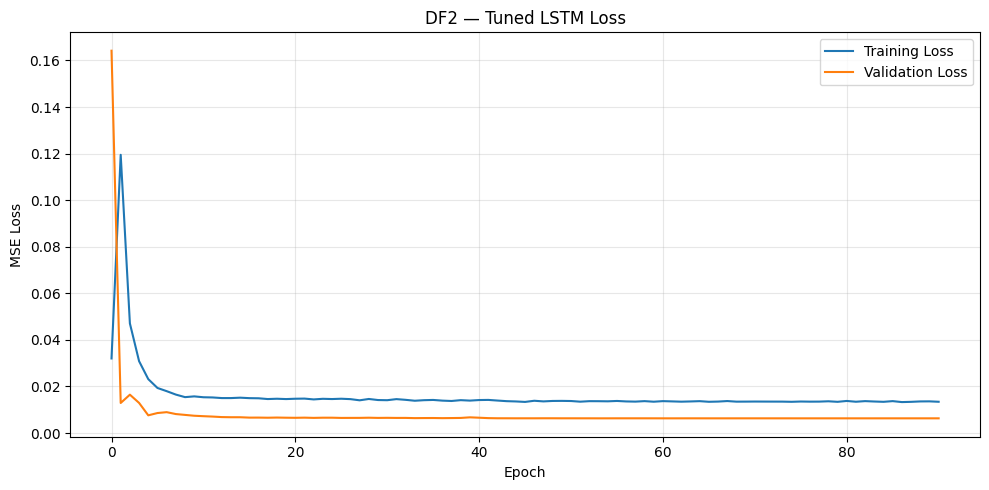



FINAL TEST RESULTS — DF2
High MAE  : 1.2830
High RMSE : 1.5585
High R²   : 0.9358
High MAPE : 2.1498%

Low MAE   : 0.9150
Low RMSE  : 1.1638
Low R²    : 0.9657
Low MAPE  : 1.5826%



##########################################################################################
STARTING DF3
##########################################################################################

DF3 observations: 198
Train observations: 138
Validation observations: 30
Test observations: 30

Sequence shapes:
X_train: (113, 25, 4)
y_train: (113, 2)
X_val: (30, 25, 4)
y_val: (30, 2)
X_test: (30, 25, 4)
y_test: (30, 2)


------------------------------------------------------------------------------------------
RUNNING 20 RANDOM SEARCH TRIALS
------------------------------------------------------------------------------------------

DF3 | Trial 1/20
Parameters: {'units_1': 64, 'units_2': 32, 'n_layers': 2, 'dropout': 0.3, 'dense_units': 8, 'learning_rate': 0.0005, 'batch_size': 32}
Validation loss: 0.0136930

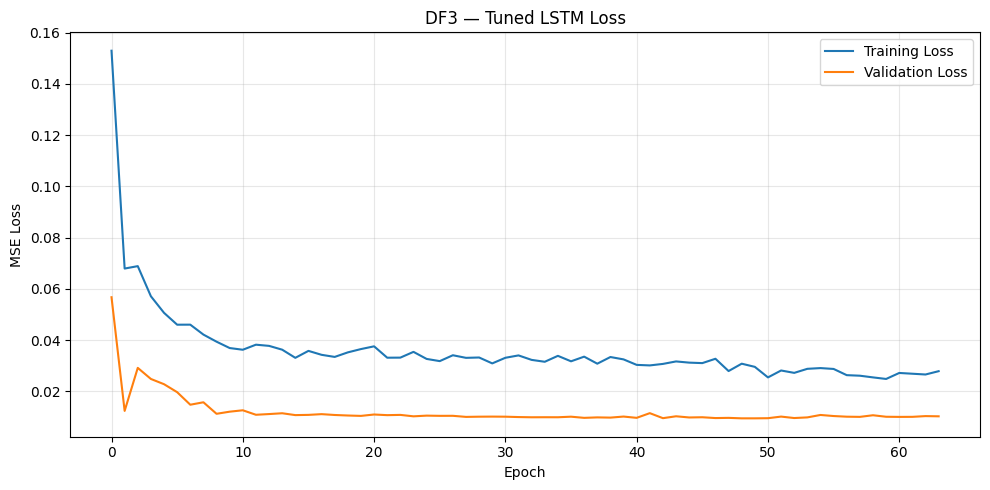



FINAL TEST RESULTS — DF3
High MAE  : 3.2869
High RMSE : 4.2167
High R²   : 0.7567
High MAPE : 4.8594%

Low MAE   : 3.6560
Low RMSE  : 5.0363
Low R²    : 0.6179
Low MAPE  : 5.5132%



##########################################################################################
STARTING DF4
##########################################################################################

DF4 observations: 387
Train observations: 270
Validation observations: 58
Test observations: 59

Sequence shapes:
X_train: (245, 25, 4)
y_train: (245, 2)
X_val: (58, 25, 4)
y_val: (58, 2)
X_test: (59, 25, 4)
y_test: (59, 2)


------------------------------------------------------------------------------------------
RUNNING 20 RANDOM SEARCH TRIALS
------------------------------------------------------------------------------------------

DF4 | Trial 1/20
Parameters: {'units_1': 64, 'units_2': 32, 'n_layers': 2, 'dropout': 0.3, 'dense_units': 32, 'learning_rate': 0.001, 'batch_size': 32}
Validation loss: 0.0236807

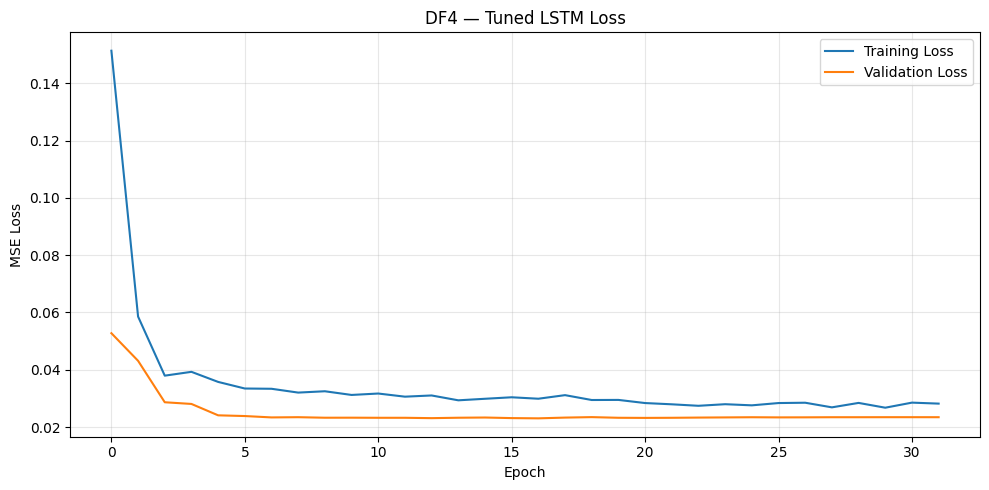



FINAL TEST RESULTS — DF4
High MAE  : 0.9306
High RMSE : 1.2033
High R²   : 0.9327
High MAPE : 1.4152%

Low MAE   : 0.7545
Low RMSE  : 1.1862
Low R²    : 0.9403
Low MAPE  : 1.1890%



####################################################################################################
FINAL TUNED LSTM RESULTS
####################################################################################################


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Validation_Loss,...,Validation_Observations,Test_Observations,Lookback,Units_1,Units_2,N_Layers,Dropout,Dense_Units,Learning_Rate,Batch_Size
0,DF1,3.261888,3.789355,0.479685,4.042647,2.108349,2.481111,0.798276,2.706005,0.005102,...,60,60,25,128,16,1,0.3,16,0.0005,16
1,DF2,1.283046,1.558546,0.935753,2.149844,0.914976,1.163817,0.965702,1.582558,0.006314,...,134,135,25,128,16,1,0.1,32,0.0005,16
2,DF3,3.286857,4.216719,0.756744,4.859392,3.656005,5.036337,0.617868,5.513249,0.009513,...,30,30,25,64,64,1,0.2,8,0.0020,16
3,DF4,0.930607,1.203332,0.932694,1.415186,0.754513,1.186157,0.940274,1.188979,0.023053,...,58,59,25,32,16,1,0.3,16,0.0020,16





####################################################################################################
SELECTED HYPERPARAMETERS
####################################################################################################


,Regime,Best_Validation_Loss,Units_1,Units_2,N_Layers,Dropout,Dense_Units,Learning_Rate,Batch_Size
0,DF1,0.005102,128,16,1,0.3,16,0.0005,16
1,DF2,0.006314,128,16,1,0.1,32,0.0005,16
2,DF3,0.009513,64,64,1,0.2,8,0.0020,16
3,DF4,0.023053,32,16,1,0.3,16,0.0020,16




####################################################################################################
HYPERPARAMETER TUNING COMPLETED
####################################################################################################

Report:
LSTM_Hyperparameter_Tuning/LSTM_Hyperparameter_Tuning_Report.xlsx

Models:
LSTM_Hyperparameter_Tuning/models/

Predictions:
LSTM_Hyperparameter_Tuning/predictions/

Plots:
LSTM_Hyperparameter_Tuning/plots/

Final test performance:


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE
0,DF1,3.261888,3.789355,0.479685,4.042647,2.108349,2.481111,0.798276,2.706005
1,DF2,1.283046,1.558546,0.935753,2.149844,0.914976,1.163817,0.965702,1.582558
2,DF3,3.286857,4.216719,0.756744,4.859392,3.656005,5.036337,0.617868,5.513249
3,DF4,0.930607,1.203332,0.932694,1.415186,0.754513,1.186157,0.940274,1.188979


In [ ]:
# ============================================================
# NIFTY 50 — REGIME-WISE LSTM HYPERPARAMETER TUNING
# ============================================================
#
# DF1 = 2007-2010
# DF2 = 2011-2019
# DF3 = 2020-2021
# DF4 = 2022-latest
#
# Input:
#   Open, High, Low, Close
#
# Target:
#   Next-Day High / Current-Day Close
#   Next-Day Low  / Current-Day Close
#
# Split:
#   70% Train
#   15% Validation
#   15% Test
#
# Hyperparameter selection:
#   Validation set ONLY
#
# Final evaluation:
#   Test set ONLY
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore")


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)


# ============================================================
# 3. SETTINGS
# ============================================================

LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

N_TRIALS = 20

MAX_EPOCHS = 150

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]

TARGETS = [
    "Target_High",
    "Target_Low"
]


# ============================================================
# 4. IMPORTANT:
#    CHECK THAT df EXISTS
# ============================================================

if "df" not in globals():

    raise NameError(
        """
        DataFrame 'df' was not found.

        Load your NIFTY 50 dataset into a dataframe called 'df'
        before running this code.
        """
    )


# ============================================================
# 5. START WITH A CLEAN COPY
# ============================================================

data = df.copy()

print("\nOriginal dataframe shape:")
print(data.shape)

print("\nOriginal columns:")
print(data.columns.tolist())


# ============================================================
# 6. FIND DATE COLUMN
# ============================================================

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Datetime",
    "datetime"
]

date_column = None

for col in possible_date_columns:

    if col in data.columns:

        date_column = col
        break


if date_column is None:

    raise ValueError(
        """
        No Date column was found.

        Expected one of:
        Date
        date
        DATE
        Datetime
        datetime
        """
    )


# Rename to Date
if date_column != "Date":

    data = data.rename(
        columns={
            date_column: "Date"
        }
    )


# ============================================================
# 7. CHECK OHLC COLUMNS
# ============================================================

required_columns = [
    "Date",
    "Open",
    "High",
    "Low",
    "Close"
]

missing_columns = [
    col
    for col in required_columns
    if col not in data.columns
]

if missing_columns:

    raise ValueError(
        f"Missing columns: {missing_columns}"
    )


# ============================================================
# 8. DATE CONVERSION
# ============================================================

data["Date"] = pd.to_datetime(
    data["Date"],
    errors="coerce"
)

print(
    "\nInvalid dates:",
    data["Date"].isna().sum()
)


# Remove invalid dates
data = data.dropna(
    subset=["Date"]
).copy()


# ============================================================
# 9. SORT CHRONOLOGICALLY
# ============================================================

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)


# ============================================================
# 10. NUMERIC OHLC CONVERSION
# ============================================================

for col in [
    "Open",
    "High",
    "Low",
    "Close"
]:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )


# ============================================================
# 11. REMOVE INVALID OHLC ROWS
# ============================================================

print(
    "\nMissing OHLC values before cleaning:"
)

print(
    data[
        [
            "Open",
            "High",
            "Low",
            "Close"
        ]
    ].isna().sum()
)


data = data.dropna(
    subset=[
        "Open",
        "High",
        "Low",
        "Close"
    ]
).reset_index(
    drop=True
)


# ============================================================
# 12. SHOW ACTUAL DATE RANGE
# ============================================================

print("\n")
print("=" * 70)
print("CLEAN DATASET INFORMATION")
print("=" * 70)

print(
    "Start date:",
    data["Date"].min()
)

print(
    "End date:",
    data["Date"].max()
)

print(
    "Total observations:",
    len(data)
)


# ============================================================
# 13. CREATE REGIMES
# ============================================================

def assign_regime(date):

    year = date.year

    if 2007 <= year <= 2011:

        return "DF1"

    elif 2012 <= year <= 2019:

        return "DF2"

    elif 2020 <= year <= 2022:

        return "DF3"

    elif year >= 2023:

        return "DF4"

    else:

        return np.nan


data["Regime"] = (
    data["Date"]
    .apply(assign_regime)
)


# ============================================================
# 14. CRITICAL REGIME CHECK
# ============================================================

print("\n")
print("=" * 70)
print("REGIME DISTRIBUTION")
print("=" * 70)

regime_counts = (
    data["Regime"]
    .value_counts()
    .sort_index()
)

print(
    regime_counts
)


# Explicitly check each regime
for regime in [
    "DF1",
    "DF2",
    "DF3",
    "DF4"
]:

    count = (
        data["Regime"]
        .eq(regime)
        .sum()
    )

    print(
        f"{regime}: {count} observations"
    )


# ============================================================
# 15. STOP IF A REGIME IS EMPTY
# ============================================================

required_regimes = [
    "DF1",
    "DF2",
    "DF3",
    "DF4"
]

empty_regimes = []

for regime in required_regimes:

    if (
        data["Regime"]
        .eq(regime)
        .sum()
        == 0
    ):

        empty_regimes.append(
            regime
        )


if empty_regimes:

    raise ValueError(
        f"""
        EMPTY REGIME DETECTED: {empty_regimes}

        Your current dataframe does not contain observations
        for these regimes.

        Check the date range printed above.

        Expected:
        DF1 = 2007-2010
        DF2 = 2011-2019
        DF3 = 2020-2021
        DF4 = 2022-latest
        """
    )


# ============================================================
# 16. CREATE NORMALIZED TARGETS
# ============================================================

data["Target_High"] = (
    data["High"].shift(-1)
    /
    data["Close"]
)

data["Target_Low"] = (
    data["Low"].shift(-1)
    /
    data["Close"]
)


# ============================================================
# 17. IMPORTANT:
#    REMOVE ONLY ROWS WITH MISSING TARGET
# ============================================================

data = data.dropna(
    subset=[
        "Target_High",
        "Target_Low"
    ]
).reset_index(
    drop=True
)


# ============================================================
# 18. CHECK REGIMES AGAIN
# ============================================================

print("\n")
print("=" * 70)
print("REGIMES AFTER TARGET CREATION")
print("=" * 70)

print(
    data["Regime"]
    .value_counts()
    .sort_index()
)


# ============================================================
# 19. HYPERPARAMETER SEARCH SPACE
# ============================================================

SEARCH_SPACE = {

    "units_1": [
        32,
        64,
        128
    ],

    "units_2": [
        16,
        32,
        64
    ],

    "n_layers": [
        1,
        2
    ],

    "dropout": [
        0.10,
        0.20,
        0.30
    ],

    "dense_units": [
        8,
        16,
        32
    ],

    "learning_rate": [
        0.0005,
        0.001,
        0.002
    ],

    "batch_size": [
        16,
        32
    ]
}


# ============================================================
# 20. RANDOM PARAMETER GENERATOR
# ============================================================

def sample_hyperparameters():

    return {

        "units_1":
            random.choice(
                SEARCH_SPACE[
                    "units_1"
                ]
            ),

        "units_2":
            random.choice(
                SEARCH_SPACE[
                    "units_2"
                ]
            ),

        "n_layers":
            random.choice(
                SEARCH_SPACE[
                    "n_layers"
                ]
            ),

        "dropout":
            random.choice(
                SEARCH_SPACE[
                    "dropout"
                ]
            ),

        "dense_units":
            random.choice(
                SEARCH_SPACE[
                    "dense_units"
                ]
            ),

        "learning_rate":
            random.choice(
                SEARCH_SPACE[
                    "learning_rate"
                ]
            ),

        "batch_size":
            random.choice(
                SEARCH_SPACE[
                    "batch_size"
                ]
            )
    }


# ============================================================
# 21. MODEL BUILDER
# ============================================================

def build_lstm_model(
    input_shape,
    params
):

    model = Sequential()


    # --------------------------------------------------------
    # ONE LSTM LAYER
    # --------------------------------------------------------

    if params["n_layers"] == 1:

        model.add(
            LSTM(
                params["units_1"],
                input_shape=input_shape
            )
        )

        model.add(
            Dropout(
                params["dropout"]
            )
        )


    # --------------------------------------------------------
    # TWO LSTM LAYERS
    # --------------------------------------------------------

    else:

        model.add(
            LSTM(
                params["units_1"],
                return_sequences=True,
                input_shape=input_shape
            )
        )

        model.add(
            Dropout(
                params["dropout"]
            )
        )

        model.add(
            LSTM(
                params["units_2"]
            )
        )

        model.add(
            Dropout(
                params["dropout"]
            )
        )


    # --------------------------------------------------------
    # DENSE
    # --------------------------------------------------------

    model.add(
        Dense(
            params["dense_units"],
            activation="relu"
        )
    )


    # --------------------------------------------------------
    # TWO OUTPUTS
    # --------------------------------------------------------

    model.add(
        Dense(2)
    )


    # --------------------------------------------------------
    # OPTIMIZER
    # --------------------------------------------------------

    optimizer = Adam(
        learning_rate=
            params["learning_rate"]
    )


    model.compile(
        optimizer=optimizer,
        loss="mse"
    )


    return model


# ============================================================
# 22. TRAINING SEQUENCE FUNCTION
# ============================================================

def create_training_sequences(
    X,
    y,
    lookback
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[
                i - lookback:i
            ]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 23. VALIDATION / TEST SEQUENCE FUNCTION
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):

    # history_X contains only previous observations
    # from the preceding partition.

    combined_X = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )


    X_seq = []
    y_seq = []


    for i in range(
        len(partition_y)
    ):

        start = i

        end = (
            i + lookback
        )

        X_seq.append(
            combined_X[
                start:end
            ]
        )

        y_seq.append(
            partition_y[i]
        )


    return (
        np.asarray(X_seq),
        np.asarray(y_seq)
    )


# ============================================================
# 24. METRICS
# ============================================================

def calculate_metrics(
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    denominator = np.where(
        np.abs(actual) < 1e-8,
        1e-8,
        np.abs(actual)
    )

    mape = (
        np.mean(
            np.abs(
                (
                    actual
                    -
                    predicted
                )
                /
                denominator
            )
        )
        * 100
    )

    return (
        mae,
        rmse,
        r2,
        mape
    )


# ============================================================
# 25. OUTPUT DIRECTORIES
# ============================================================

BASE_DIR = (
    "LSTM_Hyperparameter_Tuning"
)

os.makedirs(
    BASE_DIR,
    exist_ok=True
)

os.makedirs(
    f"{BASE_DIR}/models",
    exist_ok=True
)

os.makedirs(
    f"{BASE_DIR}/predictions",
    exist_ok=True
)

os.makedirs(
    f"{BASE_DIR}/plots",
    exist_ok=True
)


# ============================================================
# 26. STORAGE
# ============================================================

all_trials = []

all_final_results = []

all_selected_params = []


# ============================================================
# 27. MAIN LOOP
# ============================================================

for regime in required_regimes:

    print("\n\n")
    print("#" * 90)
    print(
        f"STARTING {regime}"
    )
    print("#" * 90)


    # ========================================================
    # FILTER REGIME
    # ========================================================

    regime_data = (
        data[
            data["Regime"] == regime
        ]
        .copy()
        .sort_values("Date")
        .reset_index(drop=True)
    )


    n_obs = len(
        regime_data
    )


    print(
        f"\n{regime} observations:",
        n_obs
    )


    # ========================================================
    # SAFETY CHECK
    # ========================================================

    minimum_required = (
        LOOKBACK + 20
    )

    if n_obs < minimum_required:

        print(
            f"\nWARNING: {regime} has only "
            f"{n_obs} observations."
        )

        print(
            "Skipping this regime."
        )

        continue


    # ========================================================
    # RAW X
    # ========================================================

    X_raw = (
        regime_data[
            FEATURES
        ]
        .values
        .astype(np.float32)
    )


    # ========================================================
    # RAW Y
    # ========================================================

    y_raw = (
        regime_data[
            TARGETS
        ]
        .values
        .astype(np.float32)
    )


    # ========================================================
    # CHRONOLOGICAL SPLIT
    # ========================================================

    train_end = int(
        n_obs * TRAIN_RATIO
    )

    val_end = int(
        n_obs
        *
        (
            TRAIN_RATIO
            +
            VAL_RATIO
        )
    )


    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]


    y_train_raw = y_raw[
        :train_end
    ]

    y_val_raw = y_raw[
        train_end:val_end
    ]

    y_test_raw = y_raw[
        val_end:
    ]


    print(
        f"Train observations: "
        f"{len(X_train_raw)}"
    )

    print(
        f"Validation observations: "
        f"{len(X_val_raw)}"
    )

    print(
        f"Test observations: "
        f"{len(X_test_raw)}"
    )


    # ========================================================
    # EXTRA SAFETY CHECK
    # ========================================================

    if (
        len(X_train_raw) == 0
        or
        len(X_val_raw) == 0
        or
        len(X_test_raw) == 0
    ):

        raise ValueError(
            f"""
            Empty partition detected in {regime}.

            Train = {len(X_train_raw)}
            Validation = {len(X_val_raw)}
            Test = {len(X_test_raw)}

            This indicates insufficient data in this regime.
            """
        )


    # ========================================================
    # SCALE X
    # ========================================================
    #
    # FIT ONLY ON TRAIN
    # ========================================================

    x_scaler = MinMaxScaler()

    X_train_scaled = (
        x_scaler.fit_transform(
            X_train_raw
        )
    )

    X_val_scaled = (
        x_scaler.transform(
            X_val_raw
        )
    )

    X_test_scaled = (
        x_scaler.transform(
            X_test_raw
        )
    )


    # ========================================================
    # SCALE TARGET
    # ========================================================
    #
    # FIT ONLY ON TRAIN
    # ========================================================

    y_scaler = MinMaxScaler()

    y_train_scaled = (
        y_scaler.fit_transform(
            y_train_raw
        )
    )

    y_val_scaled = (
        y_scaler.transform(
            y_val_raw
        )
    )

    y_test_scaled = (
        y_scaler.transform(
            y_test_raw
        )
    )


    # ========================================================
    # TRAIN SEQUENCES
    # ========================================================

    X_train_seq, y_train_seq = (
        create_training_sequences(
            X_train_scaled,
            y_train_scaled,
            LOOKBACK
        )
    )


    # ========================================================
    # VALIDATION SEQUENCES
    # ========================================================

    X_val_seq, y_val_seq = (
        create_partition_sequences(
            history_X=
                X_train_scaled[
                    -LOOKBACK:
                ],

            partition_X=
                X_val_scaled,

            partition_y=
                y_val_scaled,

            lookback=LOOKBACK
        )
    )


    # ========================================================
    # TEST SEQUENCES
    # ========================================================

    X_test_seq, y_test_seq = (
        create_partition_sequences(
            history_X=
                X_val_scaled[
                    -LOOKBACK:
                ],

            partition_X=
                X_test_scaled,

            partition_y=
                y_test_scaled,

            lookback=LOOKBACK
        )
    )


    # ========================================================
    # SHAPE CHECK
    # ========================================================

    print("\nSequence shapes:")

    print(
        "X_train:",
        X_train_seq.shape
    )

    print(
        "y_train:",
        y_train_seq.shape
    )

    print(
        "X_val:",
        X_val_seq.shape
    )

    print(
        "y_val:",
        y_val_seq.shape
    )

    print(
        "X_test:",
        X_test_seq.shape
    )

    print(
        "y_test:",
        y_test_seq.shape
    )


    # ========================================================
    # ASSERTIONS
    # ========================================================

    assert (
        len(X_train_seq)
        ==
        len(y_train_seq)
    )

    assert (
        len(X_val_seq)
        ==
        len(y_val_seq)
    )

    assert (
        len(X_test_seq)
        ==
        len(y_test_seq)
    )


    # ========================================================
    # HYPERPARAMETER SEARCH
    # ========================================================

    best_val_loss = np.inf

    best_params = None

    best_weights = None

    best_history = None

    regime_trials = []


    print("\n")
    print("-" * 90)

    print(
        f"RUNNING {N_TRIALS} RANDOM SEARCH TRIALS"
    )

    print("-" * 90)


    for trial in range(
        1,
        N_TRIALS + 1
    ):


        print(
            f"\n{regime} | "
            f"Trial {trial}/{N_TRIALS}"
        )


        # ====================================================
        # SAMPLE PARAMETERS
        # ====================================================

        params = (
            sample_hyperparameters()
        )


        print(
            "Parameters:",
            params
        )


        # ====================================================
        # CLEAR MODEL
        # ====================================================

        tf.keras.backend.clear_session()

        tf.random.set_seed(
            SEED + trial
        )


        # ====================================================
        # BUILD MODEL
        # ====================================================

        model = build_lstm_model(
            input_shape=(
                X_train_seq.shape[1],
                X_train_seq.shape[2]
            ),
            params=params
        )


        # ====================================================
        # CALLBACKS
        # ====================================================

        early_stopping = EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True,
            verbose=0
        )


        reduce_lr = ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=7,
            min_lr=1e-6,
            verbose=0
        )


        # ====================================================
        # TRAIN
        # ====================================================

        history = model.fit(

            X_train_seq,

            y_train_seq,

            validation_data=(
                X_val_seq,
                y_val_seq
            ),

            epochs=MAX_EPOCHS,

            batch_size=
                params["batch_size"],

            callbacks=[
                early_stopping,
                reduce_lr
            ],

            shuffle=False,

            verbose=0
        )


        # ====================================================
        # BEST VALIDATION LOSS
        # ====================================================

        trial_val_loss = min(
            history.history[
                "val_loss"
            ]
        )


        best_epoch = (
            np.argmin(
                history.history[
                    "val_loss"
                ]
            )
            + 1
        )


        # ====================================================
        # SAVE TRIAL
        # ====================================================

        trial_record = {

            "Regime":
                regime,

            "Trial":
                trial,

            "Validation_Loss":
                trial_val_loss,

            "Best_Epoch":
                best_epoch,

            "Units_1":
                params["units_1"],

            "Units_2":
                params["units_2"],

            "N_Layers":
                params["n_layers"],

            "Dropout":
                params["dropout"],

            "Dense_Units":
                params["dense_units"],

            "Learning_Rate":
                params["learning_rate"],

            "Batch_Size":
                params["batch_size"]
        }


        regime_trials.append(
            trial_record
        )

        all_trials.append(
            trial_record
        )


        print(
            f"Validation loss: "
            f"{trial_val_loss:.8f}"
        )


        print(
            f"Best epoch: "
            f"{best_epoch}"
        )


        # ====================================================
        # CHECK BEST MODEL
        # ====================================================

        if (
            trial_val_loss
            <
            best_val_loss
        ):

            best_val_loss = (
                trial_val_loss
            )

            best_params = (
                params.copy()
            )

            best_weights = [
                weight.copy()
                for weight
                in model.get_weights()
            ]

            best_history = (
                history.history.copy()
            )


            print(
                "*** NEW BEST MODEL ***"
            )


    # ========================================================
    # SAVE REGIME TRIALS
    # ========================================================

    regime_trials_df = (
        pd.DataFrame(
            regime_trials
        )
        .sort_values(
            "Validation_Loss"
        )
        .reset_index(
            drop=True
        )
    )


    regime_trials_df.to_csv(

        f"{BASE_DIR}/"
        f"{regime}_all_trials.csv",

        index=False
    )


    # ========================================================
    # BEST PARAMETERS
    # ========================================================

    print("\n")
    print("=" * 90)

    print(
        f"BEST PARAMETERS — {regime}"
    )

    print("=" * 90)

    print(
        best_params
    )

    print(
        f"\nBest validation loss:"
        f" {best_val_loss:.8f}"
    )


    # ========================================================
    # SAVE PARAMETERS
    # ========================================================

    selected_record = {

        "Regime":
            regime,

        "Best_Validation_Loss":
            best_val_loss,

        "Units_1":
            best_params["units_1"],

        "Units_2":
            best_params["units_2"],

        "N_Layers":
            best_params["n_layers"],

        "Dropout":
            best_params["dropout"],

        "Dense_Units":
            best_params["dense_units"],

        "Learning_Rate":
            best_params["learning_rate"],

        "Batch_Size":
            best_params["batch_size"]
    }


    all_selected_params.append(
        selected_record
    )


    # ========================================================
    # BUILD SELECTED FINAL MODEL
    # ========================================================

    tf.keras.backend.clear_session()


    final_model = build_lstm_model(

        input_shape=(
            X_train_seq.shape[1],
            X_train_seq.shape[2]
        ),

        params=best_params
    )


    # Restore weights from best validation trial
    final_model.set_weights(
        best_weights
    )


    # ========================================================
    # SAVE MODEL
    # ========================================================

    final_model.save(

        f"{BASE_DIR}/models/"
        f"{regime}_Best_LSTM.keras"
    )


    # ========================================================
    # TEST PREDICTION
    # ========================================================

    y_pred_scaled = (
        final_model.predict(
            X_test_seq,
            verbose=0
        )
    )


    # ========================================================
    # INVERSE TARGET SCALING
    # ========================================================

    y_pred_ratio = (
        y_scaler.inverse_transform(
            y_pred_scaled
        )
    )

    y_true_ratio = (
        y_scaler.inverse_transform(
            y_test_seq
        )
    )


    # ========================================================
    # CURRENT CLOSE
    # ========================================================

    current_close = (
        X_test_raw[:, 3]
    )


    # ========================================================
    # RECONSTRUCT ABSOLUTE PRICE
    # ========================================================

    predicted_high = (
        y_pred_ratio[:, 0]
        *
        current_close
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        *
        current_close
    )


    # Actual next-day High/Low
    actual_high = (
        regime_data[
            "High"
        ]
        .iloc[
            val_end:
        ]
        .values
    )

    actual_low = (
        regime_data[
            "Low"
        ]
        .iloc[
            val_end:
        ]
        .values
    )


    # ========================================================
    # METRICS
    # ========================================================

    (
        high_mae,
        high_rmse,
        high_r2,
        high_mape
    ) = calculate_metrics(

        actual_high,

        predicted_high
    )


    (
        low_mae,
        low_rmse,
        low_r2,
        low_mape
    ) = calculate_metrics(

        actual_low,

        predicted_low
    )


    # ========================================================
    # FINAL RESULT
    # ========================================================

    final_record = {

        "Regime":
            regime,

        "High_MAE":
            high_mae,

        "High_RMSE":
            high_rmse,

        "High_R2":
            high_r2,

        "High_MAPE":
            high_mape,

        "Low_MAE":
            low_mae,

        "Low_RMSE":
            low_rmse,

        "Low_R2":
            low_r2,

        "Low_MAPE":
            low_mape,

        "Best_Validation_Loss":
            best_val_loss,

        "Train_Observations":
            len(X_train_raw),

        "Validation_Observations":
            len(X_val_raw),

        "Test_Observations":
            len(X_test_raw),

        "Lookback":
            LOOKBACK,

        "Units_1":
            best_params["units_1"],

        "Units_2":
            best_params["units_2"],

        "N_Layers":
            best_params["n_layers"],

        "Dropout":
            best_params["dropout"],

        "Dense_Units":
            best_params["dense_units"],

        "Learning_Rate":
            best_params["learning_rate"],

        "Batch_Size":
            best_params["batch_size"]
    }


    all_final_results.append(
        final_record
    )


    # ========================================================
    # PREDICTION DATAFRAME
    # ========================================================

    test_dates = (
        regime_data[
            "Date"
        ]
        .iloc[
            val_end:
        ]
        .values
    )


    predictions_df = pd.DataFrame({

        "Date":
            test_dates,

        "Current_Close":
            current_close,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "High_Error":
            actual_high
            -
            predicted_high,

        "Low_Error":
            actual_low
            -
            predicted_low
    })


    predictions_df.to_csv(

        f"{BASE_DIR}/predictions/"
        f"{regime}_predictions.csv",

        index=False
    )


    # ========================================================
    # LOSS CURVE
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        best_history["loss"],
        label="Training Loss"
    )

    plt.plot(
        best_history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"{regime} — Tuned LSTM Loss"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(

        f"{BASE_DIR}/plots/"
        f"{regime}_loss_curve.png",

        dpi=300
    )

    plt.show()


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print("\n")
    print("=" * 90)

    print(
        f"FINAL TEST RESULTS — {regime}"
    )

    print("=" * 90)

    print(
        f"High MAE  : {high_mae:.4f}"
    )

    print(
        f"High RMSE : {high_rmse:.4f}"
    )

    print(
        f"High R²   : {high_r2:.4f}"
    )

    print(
        f"High MAPE : {high_mape:.4f}%"
    )

    print()

    print(
        f"Low MAE   : {low_mae:.4f}"
    )

    print(
        f"Low RMSE  : {low_rmse:.4f}"
    )

    print(
        f"Low R²    : {low_r2:.4f}"
    )

    print(
        f"Low MAPE  : {low_mape:.4f}%"
    )


# ============================================================
# 28. FINAL TABLES
# ============================================================

final_results_df = pd.DataFrame(
    all_final_results
)

selected_params_df = pd.DataFrame(
    all_selected_params
)

all_trials_df = (
    pd.DataFrame(
        all_trials
    )
    .sort_values(
        [
            "Regime",
            "Validation_Loss"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 29. DISPLAY FINAL RESULTS
# ============================================================

print("\n\n")
print("#" * 100)
print("FINAL TUNED LSTM RESULTS")
print("#" * 100)

display(
    final_results_df
)


print("\n\n")
print("#" * 100)
print("SELECTED HYPERPARAMETERS")
print("#" * 100)

display(
    selected_params_df
)


# ============================================================
# 30. SAVE EXCEL
# ============================================================

excel_path = (
    f"{BASE_DIR}/"
    "LSTM_Hyperparameter_Tuning_Report.xlsx"
)


with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    final_results_df.to_excel(
        writer,
        sheet_name="Final Results",
        index=False
    )

    selected_params_df.to_excel(
        writer,
        sheet_name="Selected Parameters",
        index=False
    )

    all_trials_df.to_excel(
        writer,
        sheet_name="All Trials",
        index=False
    )


# ============================================================
# 31. SAVE CSV
# ============================================================

final_results_df.to_csv(

    f"{BASE_DIR}/"
    "Final_LSTM_Results.csv",

    index=False
)


selected_params_df.to_csv(

    f"{BASE_DIR}/"
    "Selected_LSTM_Parameters.csv",

    index=False
)


all_trials_df.to_csv(

    f"{BASE_DIR}/"
    "All_LSTM_Trials.csv",

    index=False
)


# ============================================================
# 32. FINAL SUMMARY
# ============================================================

print("\n")
print("#" * 100)
print("HYPERPARAMETER TUNING COMPLETED")
print("#" * 100)

print(
    "\nReport:"
)

print(
    excel_path
)

print(
    "\nModels:"
)

print(
    f"{BASE_DIR}/models/"
)

print(
    "\nPredictions:"
)

print(
    f"{BASE_DIR}/predictions/"
)

print(
    "\nPlots:"
)

print(
    f"{BASE_DIR}/plots/"
)


print("\nFinal test performance:")

display(
    final_results_df[
        [
            "Regime",
            "High_MAE",
            "High_RMSE",
            "High_R2",
            "High_MAPE",
            "Low_MAE",
            "Low_RMSE",
            "Low_R2",
            "Low_MAPE"
        ]
    ]
)



TRAINING TCN — DF1
Total observations: 499
Train observations: 349
Validation observations: 75
Test observations: 75

Sequence shapes:
X_train: (324, 25, 4)
y_train: (324, 2)
X_val: (75, 25, 4)
y_val: (75, 2)
X_test: (75, 25, 4)
y_test: (75, 2)

Model architecture:


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 25, 64)    │        832 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 25, 64)    │          0 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 25, 64)    │          0 │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 25, 64)    │        320 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 25, 64)    │          0 │ dropout_9[0][0],  │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 25, 64)    │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 25, 64)    │     12,352 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 25, 64)    │          0 │ conv1d_3[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 25, 64)    │          0 │ conv1d_4[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 25, 64)    │          0 │ dropout_11[0][0], │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 25, 64)    │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 25, 64)    │     12,352 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 25, 64)    │          0 │ conv1d_5[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 25, 64)    │     12,352 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 25, 64)    │          0 │ conv1d_6[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 25, 64)    │          0 │ dropout_13[0][0], │
│                     │                   │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 25, 64)    │          0 │ add_2[0][0]     

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 87ms/step - loss: 0.0478 - mae: 0.1715 - val_loss: 0.0044 - val_mae: 0.0507 - learning_rate: 0.0010
Epoch 2/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0332 - mae: 0.1441 - val_loss: 0.0134 - val_mae: 0.1043 - learning_rate: 0.0010
Epoch 3/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0280 - mae: 0.1260 - val_loss: 0.0036 - val_mae: 0.0463 - learning_rate: 0.0010
Epoch 4/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0294 - mae: 0.1277 - val_loss: 0.0070 - val_mae: 0.0709 - learning_rate: 0.0010
Epoch 5/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0256 - mae: 0.1176 - val_loss: 0.0028 - val_mae: 0.0456 - learning_rate: 0.0010
Epoch 6/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0248 - mae: 0.1124 - val_loss: 0.0032 - val_mae: 0.0488 - learning_rate: 0.0010
Epoch 7/150
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0229 - mae: 0.1049 - val_loss: 0.0027 - val_mae: 0.0456 - learning_rate: 0.0010
Epoch 

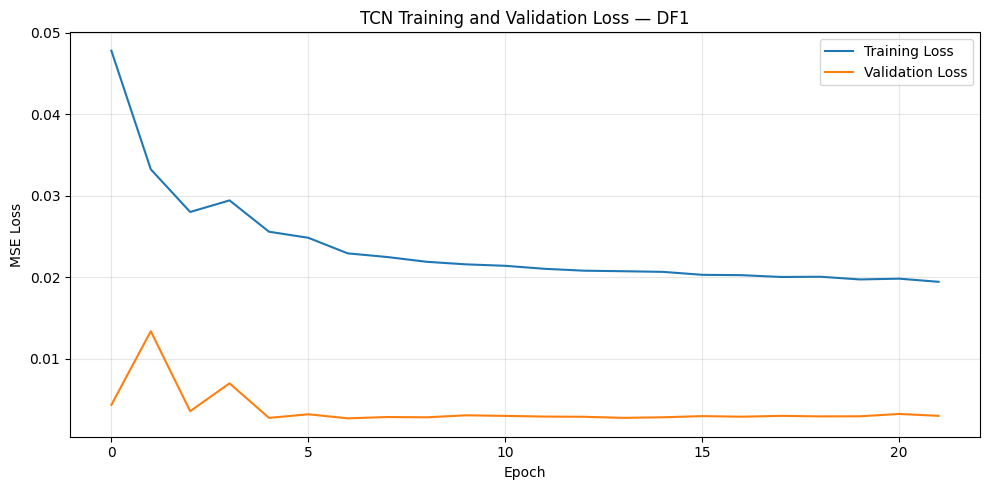

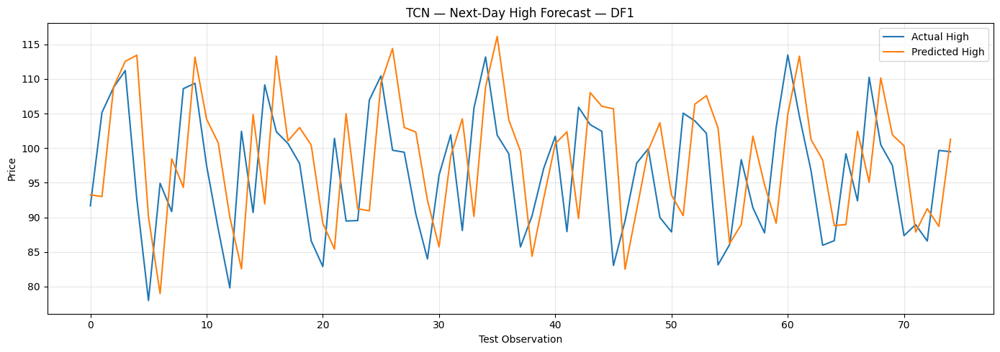

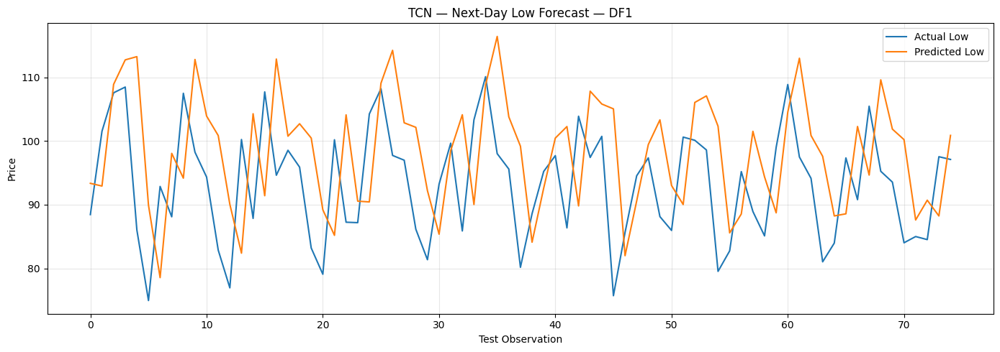



TRAINING TCN — DF2
Total observations: 794
Train observations: 555
Validation observations: 119
Test observations: 120

Sequence shapes:
X_train: (530, 25, 4)
y_train: (530, 2)
X_val: (119, 25, 4)
y_val: (119, 2)
X_test: (120, 25, 4)
y_test: (120, 2)

Model architecture:


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 25, 64)    │        832 │ input_layer_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_16          │ (None, 25, 64)    │          0 │ conv1d_9[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_16[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_17          │ (None, 25, 64)    │          0 │ conv1d_10[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 25, 64)    │          0 │ dropout_17[0][0], │
│                     │                   │            │ conv1d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 25, 64)    │          0 │ add_4[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_18          │ (None, 25, 64)    │          0 │ conv1d_12[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_18[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_19          │ (None, 25, 64)    │          0 │ conv1d_13[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 25, 64)    │          0 │ dropout_19[0][0], │
│                     │                   │            │ activation_4[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 25, 64)    │          0 │ add_5[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_14 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_20          │ (None, 25, 64)    │          0 │ conv1d_14[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_15 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_20[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_21          │ (None, 25, 64)    │          0 │ conv1d_15[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 25, 64)    │          0 │ dropout_21[0][0], │
│                     │                   │            │ activation_5[0][

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - loss: 0.0926 - mae: 0.2404 - val_loss: 0.0177 - val_mae: 0.1088 - learning_rate: 0.0010
Epoch 2/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0926 - mae: 0.2609 - val_loss: 0.0863 - val_mae: 0.2794 - learning_rate: 0.0010
Epoch 3/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0358 - mae: 0.1484 - val_loss: 0.0136 - val_mae: 0.0898 - learning_rate: 0.0010
Epoch 4/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0776 - mae: 0.2392 - val_loss: 0.0593 - val_mae: 0.2283 - learning_rate: 0.0010
Epoch 5/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0328 - mae: 0.1407 - val_loss: 0.0102 - val_mae: 0.0794 - learning_rate: 0.0010
Epoch 6/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0399 - mae: 0.1714 - val_loss: 0.0276 - val_mae: 0.1490 - learning_rate: 0.0010
Epoch 7/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0221 - mae: 0.1066 - val_loss: 0.0111 - val_mae: 0.0855 - learning_rate: 0.0010
Epoch 

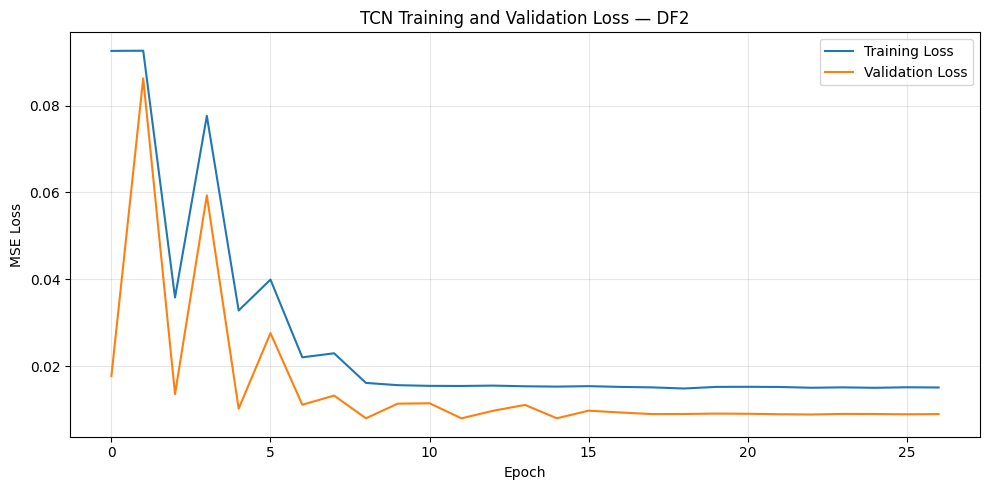

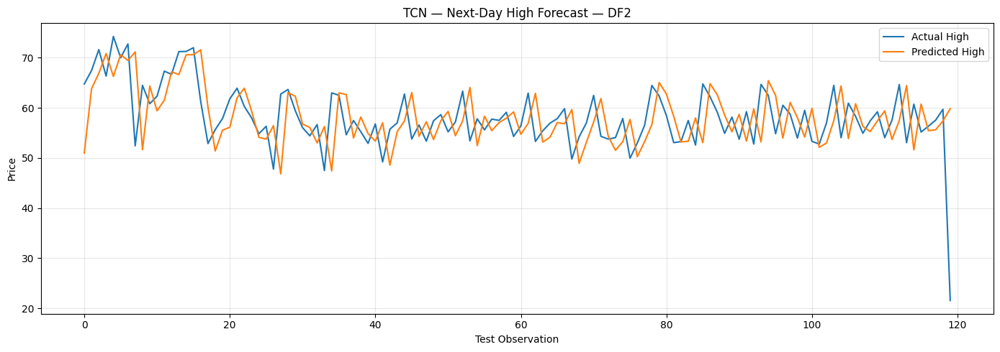

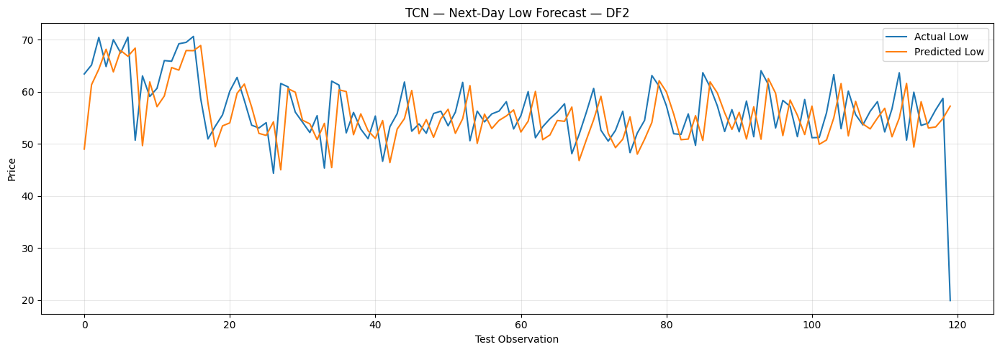



TRAINING TCN — DF3
Total observations: 298
Train observations: 208
Validation observations: 45
Test observations: 45

Sequence shapes:
X_train: (183, 25, 4)
y_train: (183, 2)
X_val: (45, 25, 4)
y_val: (45, 2)
X_test: (45, 25, 4)
y_test: (45, 2)

Model architecture:


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_18 (Conv1D)  │ (None, 25, 64)    │        832 │ input_layer_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_24          │ (None, 25, 64)    │          0 │ conv1d_18[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_19 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_24[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_25          │ (None, 25, 64)    │          0 │ conv1d_19[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_6[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 25, 64)    │          0 │ dropout_25[0][0], │
│                     │                   │            │ conv1d_20[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 25, 64)    │          0 │ add_8[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_21 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_26          │ (None, 25, 64)    │          0 │ conv1d_21[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_22 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_26[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_27          │ (None, 25, 64)    │          0 │ conv1d_22[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 25, 64)    │          0 │ dropout_27[0][0], │
│                     │                   │            │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 25, 64)    │          0 │ add_9[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_23 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_9[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_28          │ (None, 25, 64)    │          0 │ conv1d_23[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_24 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_28[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_29          │ (None, 25, 64)    │          0 │ conv1d_24[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 25, 64)    │          0 │ dropout_29[0][0], │
│                     │                   │            │ activation_9[0][

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 111ms/step - loss: 0.2806 - mae: 0.4884 - val_loss: 0.2004 - val_mae: 0.4004 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.2093 - mae: 0.4220 - val_loss: 0.1799 - val_mae: 0.3993 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.2029 - mae: 0.4204 - val_loss: 0.1730 - val_mae: 0.3979 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.1887 - mae: 0.4035 - val_loss: 0.1160 - val_mae: 0.3186 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.1405 - mae: 0.3309 - val_loss: 0.0353 - val_mae: 0.1547 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0745 - mae: 0.2105 - val_loss: 0.1055 - val_mae: 0.3000 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0924 - mae: 0.2510 - val_loss: 0.1460 - val_mae: 0.3332 - learning_rate: 0.0010
Epoch 8/150
6/6 ━━━

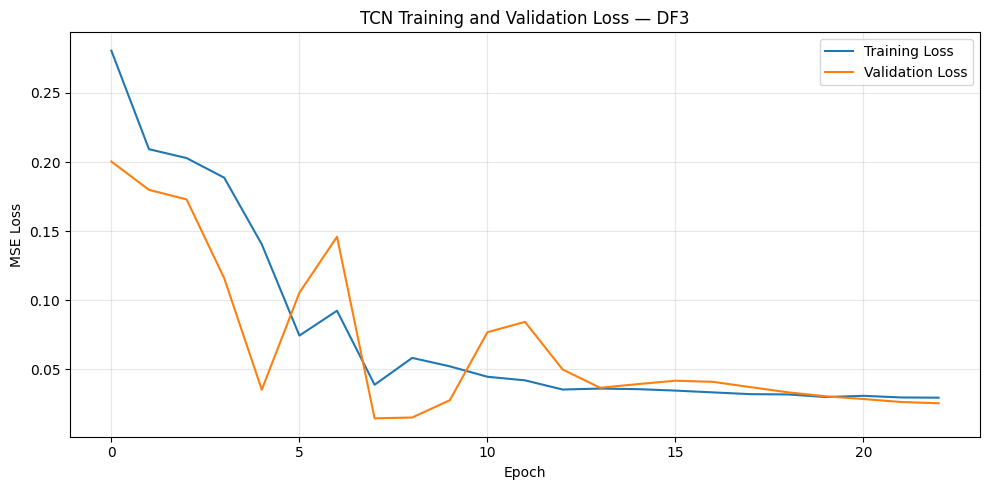

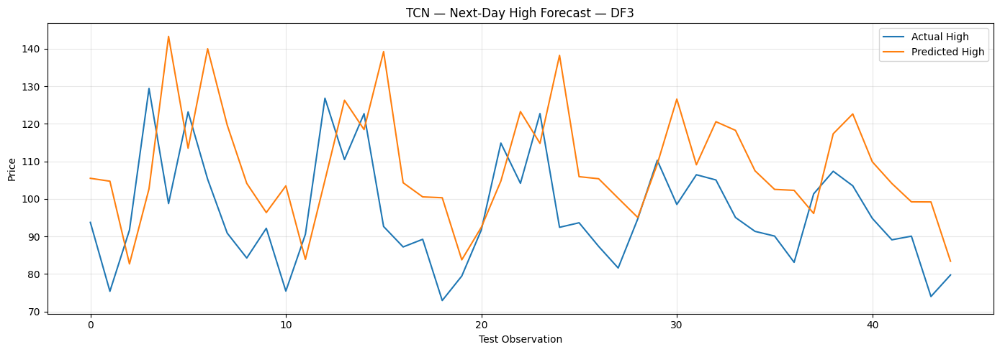

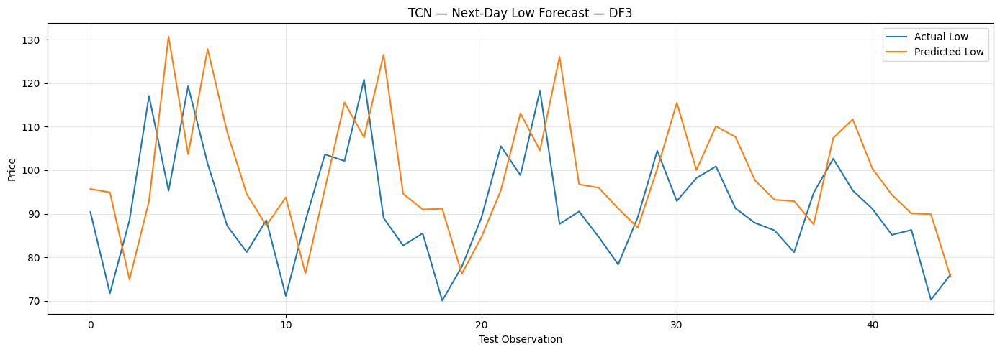



TRAINING TCN — DF4
Total observations: 287
Train observations: 200
Validation observations: 43
Test observations: 44

Sequence shapes:
X_train: (175, 25, 4)
y_train: (175, 2)
X_val: (43, 25, 4)
y_val: (43, 2)
X_test: (44, 25, 4)
y_test: (44, 2)

Model architecture:


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 25, 4)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_27 (Conv1D)  │ (None, 25, 64)    │        832 │ input_layer_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_32          │ (None, 25, 64)    │          0 │ conv1d_27[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_28 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_32[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_33          │ (None, 25, 64)    │          0 │ conv1d_28[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_29 (Conv1D)  │ (None, 25, 64)    │        320 │ input_layer_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 25, 64)    │          0 │ dropout_33[0][0], │
│                     │                   │            │ conv1d_29[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 25, 64)    │          0 │ add_12[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_30 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_12[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_34          │ (None, 25, 64)    │          0 │ conv1d_30[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_31 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_34[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_35          │ (None, 25, 64)    │          0 │ conv1d_31[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 25, 64)    │          0 │ dropout_35[0][0], │
│                     │                   │            │ activation_12[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_13       │ (None, 25, 64)    │          0 │ add_13[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 25, 64)    │     12,352 │ activation_13[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_36          │ (None, 25, 64)    │          0 │ conv1d_32[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_33 (Conv1D)  │ (None, 25, 64)    │     12,352 │ dropout_36[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_37          │ (None, 25, 64)    │          0 │ conv1d_33[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 25, 64)    │          0 │ dropout_37[0][0], │
│                     │                   │            │ activation_13[0]

 Total params: 88,690 (346.45 KB)

 Trainable params: 88,690 (346.45 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 119ms/step - loss: 0.0836 - mae: 0.2268 - val_loss: 0.1490 - val_mae: 0.3041 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0539 - mae: 0.1897 - val_loss: 0.1309 - val_mae: 0.2755 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0508 - mae: 0.1836 - val_loss: 0.1280 - val_mae: 0.2710 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0511 - mae: 0.1874 - val_loss: 0.1385 - val_mae: 0.2882 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0489 - mae: 0.1802 - val_loss: 0.1244 - val_mae: 0.2657 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0510 - mae: 0.1868 - val_loss: 0.1337 - val_mae: 0.2809 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0490 - mae: 0.1808 - val_loss: 0.1258 - val_mae: 0.2679 - learning_rate: 0.0010
Epoch 8/150
6/6 ━━━

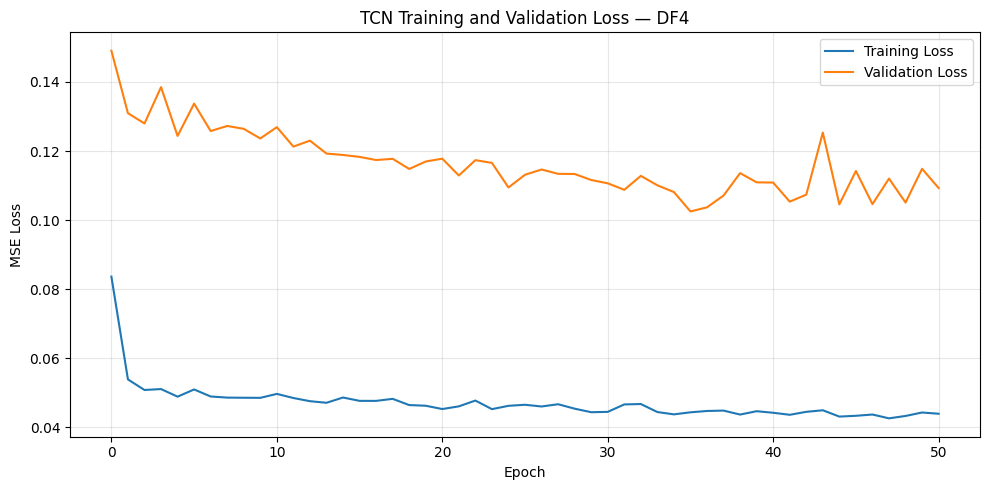

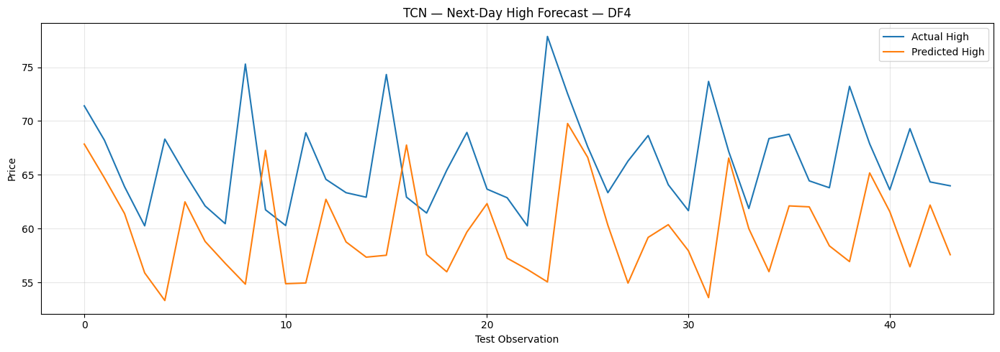

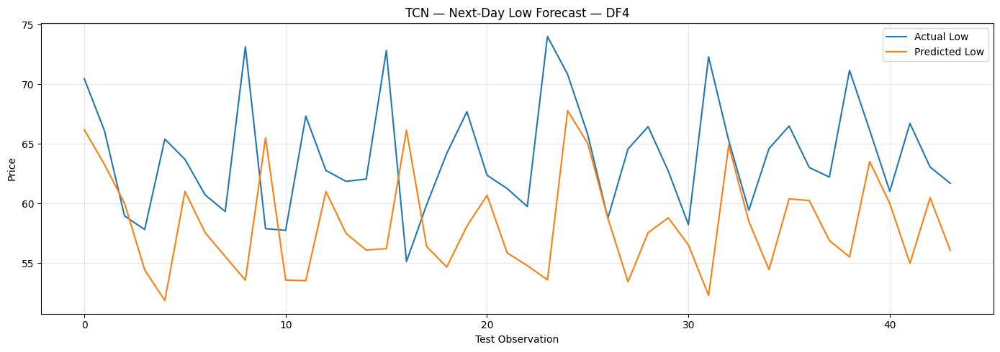



FINAL TCN RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Epoch
0,DF1,9.123365,10.795829,-0.546623,9.608756,10.553121,12.267786,-0.953919,11.665896,22
1,DF2,5.106271,6.930821,-0.209484,9.767138,5.313625,7.042976,-0.210473,10.451378,27
2,DF3,16.796137,20.414755,-1.090191,18.090910,13.194210,16.108525,-0.677863,14.738288,23
3,DF4,6.834262,8.906371,-3.139951,9.992175,6.578615,8.623173,-2.471771,9.969184,51



Results saved as: TCN_baseline_results.csv
Predictions saved as: TCN_baseline_predictions.xlsx


In [6]:
# ============================================================
# TCN BASELINE — NIFTY 50 REGIME-WISE FORECASTING
# Target: Next-Day High and Low
# Protocol: 70% Train / 15% Validation / 15% Test
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    Dropout,
    Dense,
    Add,
    Activation,
    GlobalAveragePooling1D
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 2. FIXED TCN HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

TCN_FILTERS = 64
KERNEL_SIZE = 3
DILATIONS = [1, 2, 4, 8]

DROPOUT = 0.20
DENSE_UNITS = 16

LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 150

EARLY_STOPPING_PATIENCE = 15
LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 3. FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 4. CHECK DATA
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ============================================================
# 5. DATA PREPARATION
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(data["Date"])

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

# Ensure numeric OHLC
for col in FEATURES:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 6. DEFINE MARKET REGIMES
# ============================================================

REGIMES = {
    "DF1": ("2007-01-01", "2011-12-31"),
    "DF2": ("2012-01-01", "2019-12-31"),
    "DF3": ("2020-01-01", "2022-12-31"),
    "DF4": ("2023-01-01", None)
}


# ============================================================
# 7. TARGET CREATION
# ============================================================
#
# Predict:
#
#   Next-Day High / Current Close
#   Next-Day Low  / Current Close
#
# Absolute prediction is reconstructed later:
#
#   Predicted High = Predicted Ratio × Current Close
#   Predicted Low  = Predicted Ratio × Current Close
#
# ============================================================

data["Target_High_Ratio"] = (
    data["High"].shift(-1) /
    data["Close"]
)

data["Target_Low_Ratio"] = (
    data["Low"].shift(-1) /
    data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 8. SEQUENCE CREATION FUNCTION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):
    """
    Creates sequences for the training partition.

    X[i-lookback:i] -> y[i]
    """

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 9. VALIDATION / TEST SEQUENCE FUNCTION
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):
    """
    Creates validation/test sequences while allowing
    the first observations to use historical information.

    This avoids losing the first LOOKBACK observations
    of validation/test.
    """

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[i:i + lookback]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. TCN RESIDUAL BLOCK
# ============================================================

def tcn_residual_block(
    x,
    filters,
    kernel_size,
    dilation_rate,
    dropout_rate
):

    residual = x

    # First causal dilated convolution
    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate,
        activation="relu"
    )(x)

    x = Dropout(
        dropout_rate
    )(x)

    # Second causal dilated convolution
    x = Conv1D(
        filters=filters,
        kernel_size=kernel_size,
        padding="causal",
        dilation_rate=dilation_rate,
        activation=None
    )(x)

    x = Dropout(
        dropout_rate
    )(x)

    # Match residual dimensions if necessary
    if residual.shape[-1] != filters:

        residual = Conv1D(
            filters=filters,
            kernel_size=1,
            padding="same"
        )(residual)

    # Residual connection
    x = Add()(
        [
            x,
            residual
        ]
    )

    x = Activation(
        "relu"
    )(x)

    return x


# ============================================================
# 11. BUILD TCN MODEL
# ============================================================

def build_tcn_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )

    x = inputs

    # --------------------------------------------
    # Dilated TCN blocks
    # --------------------------------------------

    for dilation in DILATIONS:

        x = tcn_residual_block(
            x=x,
            filters=TCN_FILTERS,
            kernel_size=KERNEL_SIZE,
            dilation_rate=dilation,
            dropout_rate=DROPOUT
        )

    # --------------------------------------------
    # Sequence → fixed representation
    # --------------------------------------------

    x = GlobalAveragePooling1D()(x)

    # --------------------------------------------
    # Dense forecasting head
    # --------------------------------------------

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs
    )

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 12. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred) /
            denominator
        )
    ) * 100

    return mae, rmse, r2, mape


# ============================================================
# 13. STORAGE
# ============================================================

all_results = []
all_predictions = {}
all_histories = {}
all_models = {}


# ============================================================
# 14. REGIME-WISE TRAINING
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 70)
    print(f"TRAINING TCN — {regime_name}")
    print("=" * 70)

    # --------------------------------------------------------
    # Filter regime
    # --------------------------------------------------------

    regime_data = data[
        data["Date"] >= pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )

    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )

    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            f"insufficient observations."
        )

        continue


    # --------------------------------------------------------
    # Extract features and targets
    # --------------------------------------------------------

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # --------------------------------------------------------
    # 70 / 15 / 15 chronological split
    # --------------------------------------------------------

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )

    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]

    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]

    print(
        f"Train observations: "
        f"{len(X_train_raw)}"
    )

    print(
        f"Validation observations: "
        f"{len(X_val_raw)}"
    )

    print(
        f"Test observations: "
        f"{len(X_test_raw)}"
    )


    # ========================================================
    # 15. TRAIN-ONLY SCALING
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 16. SCALE TARGETS USING TRAIN ONLY
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 17. CREATE TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = create_train_sequences(
        X_train_scaled,
        y_train_scaled,
        LOOKBACK
    )


    # ========================================================
    # 18. CREATE VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = create_partition_sequences(
        history_X=X_train_scaled[-LOOKBACK:],
        partition_X=X_val_scaled,
        partition_y=y_val_scaled,
        lookback=LOOKBACK
    )


    # ========================================================
    # 19. CREATE TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = create_partition_sequences(
        history_X=X_val_scaled[-LOOKBACK:],
        partition_X=X_test_scaled,
        partition_y=y_test_scaled,
        lookback=LOOKBACK
    )


    print(
        "\nSequence shapes:"
    )

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "y_train:",
        y_train_seq.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "y_val:",
        y_val_seq.shape
    )

    print(
        "X_test:",
        X_test.shape
    )

    print(
        "y_test:",
        y_test_seq.shape
    )


    # ========================================================
    # 20. BUILD MODEL
    # ========================================================

    model = build_tcn_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )

    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 21. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 22. TRAIN
    # ========================================================

    history = model.fit(
        X_train,
        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,
        verbose=1
    )


    # ========================================================
    # 23. PREDICT TEST SET
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 24. INVERSE TRANSFORM TARGET RATIOS
    # ========================================================

    y_pred_ratio = y_scaler.inverse_transform(
        y_pred_scaled
    )

    y_test_ratio = y_scaler.inverse_transform(
        y_test_seq
    )


    # ========================================================
    # 25. CURRENT CLOSE FOR EACH TEST TARGET
    # ========================================================
    #
    # Since validation/test sequences preserve the
    # partition ordering, the target-day current close
    # corresponds to X_test_raw / X_val_raw etc.
    #
    # Target is:
    #
    # High(t+1) / Close(t)
    #
    # Therefore use Close(t) to reconstruct.
    # ========================================================

    current_close_test = X_test_raw[
        :, FEATURES.index("Close")
    ]


    # ========================================================
    # 26. RECONSTRUCT ABSOLUTE PRICES
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0] *
        current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1] *
        current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0] *
        current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1] *
        current_close_test
    )


    # ========================================================
    # 27. CALCULATE METRICS — HIGH
    # ========================================================

    high_mae, high_rmse, high_r2, high_mape = (
        calculate_metrics(
            actual_high,
            predicted_high
        )
    )


    # ========================================================
    # 28. CALCULATE METRICS — LOW
    # ========================================================

    low_mae, low_rmse, low_r2, low_mape = (
        calculate_metrics(
            actual_low,
            predicted_low
        )
    )


    # ========================================================
    # 29. PRINT RESULTS
    # ========================================================

    print("\n")
    print("=" * 70)
    print(f"TCN RESULTS — {regime_name}")
    print("=" * 70)

    print("\nNEXT-DAY HIGH")
    print(
        f"MAE  : {high_mae:.6f}"
    )
    print(
        f"RMSE : {high_rmse:.6f}"
    )
    print(
        f"R²   : {high_r2:.6f}"
    )
    print(
        f"MAPE : {high_mape:.6f}%"
    )

    print("\nNEXT-DAY LOW")
    print(
        f"MAE  : {low_mae:.6f}"
    )
    print(
        f"RMSE : {low_rmse:.6f}"
    )
    print(
        f"R²   : {low_r2:.6f}"
    )
    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 30. SAVE RESULTS
    # ========================================================

    all_results.append({

        "Regime": regime_name,

        "High_MAE": high_mae,
        "High_RMSE": high_rmse,
        "High_R2": high_r2,
        "High_MAPE": high_mape,

        "Low_MAE": low_mae,
        "Low_RMSE": low_rmse,
        "Low_R2": low_r2,
        "Low_MAPE": low_mape,

        "Best_Epoch":
            len(history.history["loss"])

    })


    # ========================================================
    # 31. SAVE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "Current_Close":
            current_close_test

    })

    all_predictions[
        regime_name
    ] = prediction_df

    all_histories[
        regime_name
    ] = history.history

    all_models[
        regime_name
    ] = model


    # ========================================================
    # 32. PLOT TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"TCN Training and Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. PLOT HIGH PREDICTIONS
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"TCN — Next-Day High Forecast — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 34. PLOT LOW PREDICTIONS
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"TCN — Next-Day Low Forecast — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 35. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 90)
print("FINAL TCN RESULTS")
print("=" * 90)

display(
    results_df.round(6)
)


# ============================================================
# 36. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "TCN_baseline_results.csv",
    index=False
)

print(
    "\nResults saved as:"
    " TCN_baseline_results.csv"
)


# ============================================================
# 37. SAVE ALL PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "TCN_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in all_predictions.items():

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )

print(
    "Predictions saved as:"
    " TCN_baseline_predictions.xlsx"
)



Conv1D-LSTM TRAINING — DF1
Total observations: 399
Train: 279
Validation: 60
Test: 60

Sequence shapes:
X_train: (254, 25, 4)
y_train: (254, 2)
X_val: (60, 25, 4)
y_val: (60, 2)
X_test: (60, 25, 4)
y_test: (60, 2)

Model architecture:


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_36 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_33 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_37 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 132ms/step - loss: 0.0464 - mae: 0.1613 - val_loss: 0.0705 - val_mae: 0.2531 - learning_rate: 0.0010
Epoch 2/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0316 - mae: 0.1255 - val_loss: 0.0638 - val_mae: 0.2402 - learning_rate: 0.0010
Epoch 3/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0274 - mae: 0.1182 - val_loss: 0.0567 - val_mae: 0.2264 - learning_rate: 0.0010
Epoch 4/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0262 - mae: 0.1117 - val_loss: 0.0496 - val_mae: 0.2113 - learning_rate: 0.0010
Epoch 5/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0271 - mae: 0.1120 - val_loss: 0.0388 - val_mae: 0.1854 - learning_rate: 0.0010
Epoch 6/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0246 - mae: 0.1079 - val_loss: 0.0287 - val_mae: 0.1568 - learning_rate: 0.0010
Epoch 7/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0236 - mae: 0.1103 - val_loss: 0.0247 - val_mae: 0.1437 - learning_rate: 0.0010
Epoch 8/150
8/8 ━━━

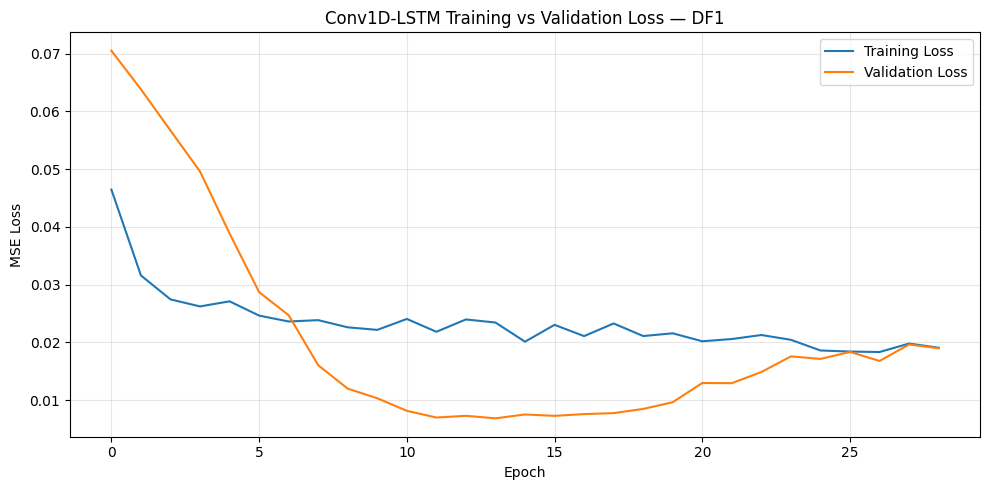

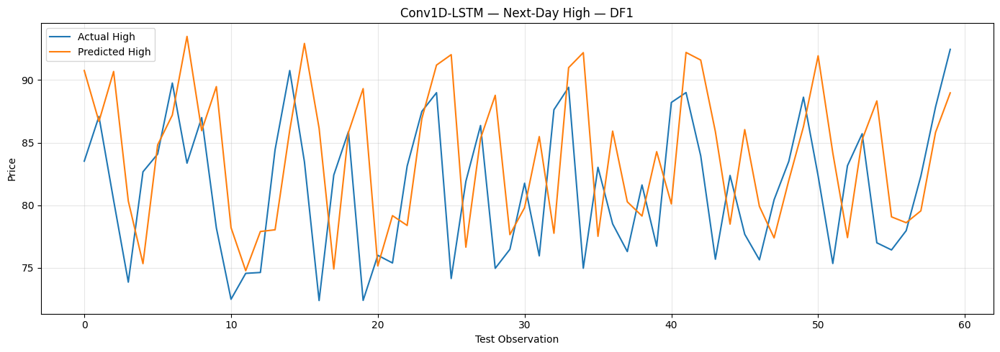

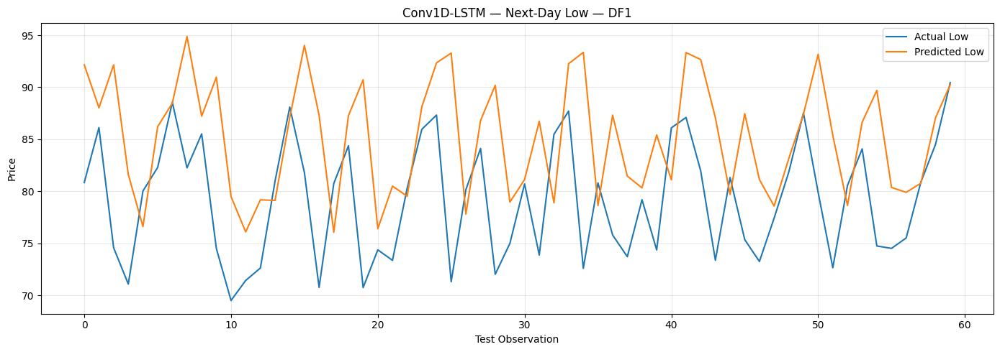



Conv1D-LSTM TRAINING — DF2
Total observations: 894
Train: 625
Validation: 134
Test: 135

Sequence shapes:
X_train: (600, 25, 4)
y_train: (600, 2)
X_val: (134, 25, 4)
y_val: (134, 2)
X_test: (135, 25, 4)
y_test: (135, 2)

Model architecture:


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_38 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_39 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_38 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - loss: 0.0446 - mae: 0.1635 - val_loss: 0.1154 - val_mae: 0.3296 - learning_rate: 0.0010
Epoch 2/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0224 - mae: 0.1167 - val_loss: 0.0942 - val_mae: 0.2957 - learning_rate: 0.0010
Epoch 3/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0199 - mae: 0.1073 - val_loss: 0.0689 - val_mae: 0.2500 - learning_rate: 0.0010
Epoch 4/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0189 - mae: 0.1048 - val_loss: 0.0498 - val_mae: 0.2091 - learning_rate: 0.0010
Epoch 5/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0178 - mae: 0.1010 - val_loss: 0.0457 - val_mae: 0.1995 - learning_rate: 0.0010
Epoch 6/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0167 - mae: 0.0973 - val_loss: 0.0389 - val_mae: 0.1818 - learning_rate: 0.0010
Epoch 7/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0164 - mae: 0.0952 - val_loss: 0.0300 - val_mae: 0.1568 - learning_rate: 0.0010
Epoch 

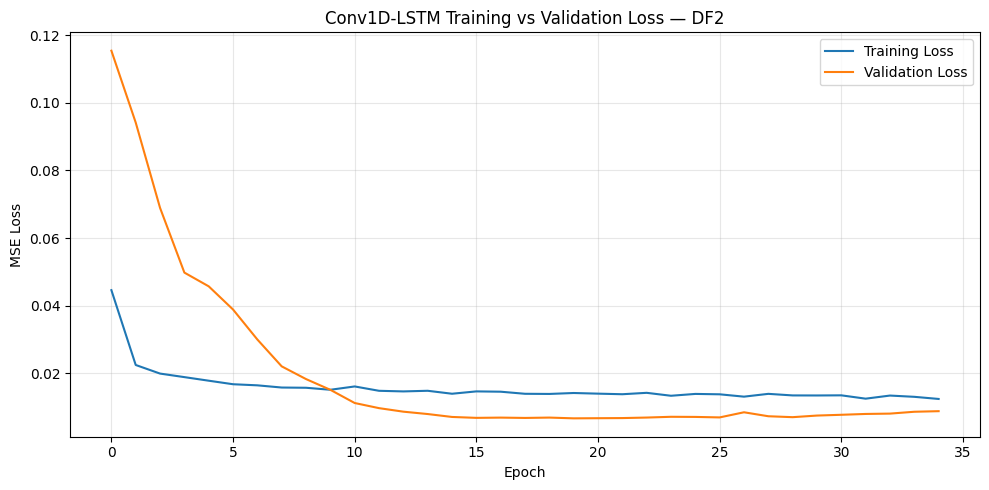

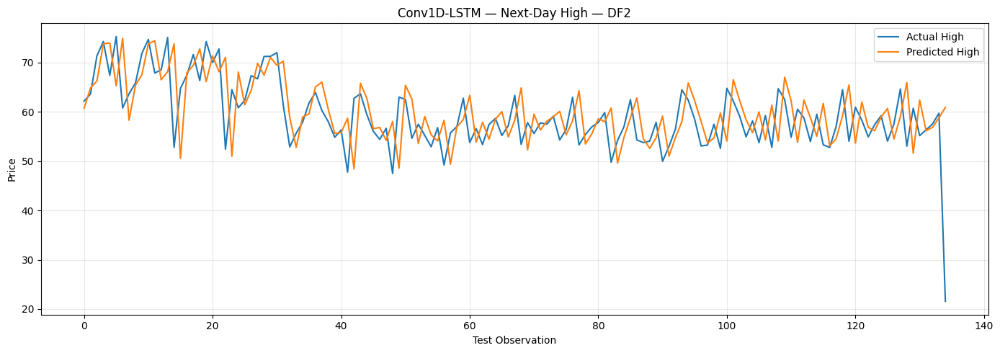

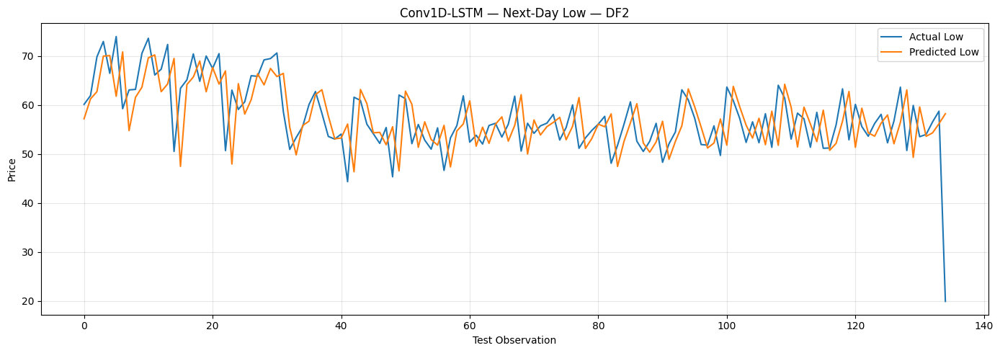



Conv1D-LSTM TRAINING — DF3
Total observations: 198
Train: 138
Validation: 30
Test: 30

Sequence shapes:
X_train: (113, 25, 4)
y_train: (113, 2)
X_val: (30, 25, 4)
y_val: (30, 2)
X_test: (30, 25, 4)
y_test: (30, 2)

Model architecture:


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_40 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_20 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_41 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_21 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_44 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 252ms/step - loss: 0.1088 - mae: 0.2524 - val_loss: 0.0530 - val_mae: 0.2064 - learning_rate: 0.0010
Epoch 2/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 0.0576 - mae: 0.1851 - val_loss: 0.0554 - val_mae: 0.2122 - learning_rate: 0.0010
Epoch 3/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 0.0408 - mae: 0.1599 - val_loss: 0.0683 - val_mae: 0.2409 - learning_rate: 0.0010
Epoch 4/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0445 - mae: 0.1595 - val_loss: 0.0640 - val_mae: 0.2328 - learning_rate: 0.0010
Epoch 5/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.0389 - mae: 0.1457 - val_loss: 0.0605 - val_mae: 0.2255 - learning_rate: 0.0010
Epoch 6/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0376 - mae: 0.1456 - val_loss: 0.0588 - val_mae: 0.2219 - learning_rate: 0.0010
Epoch 7/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.0361 - mae: 0.1385 - val_loss: 0.0594 - val_mae: 0.2230 - learning_rate: 0.0010
Epoch 8/150
4/4 ━━━

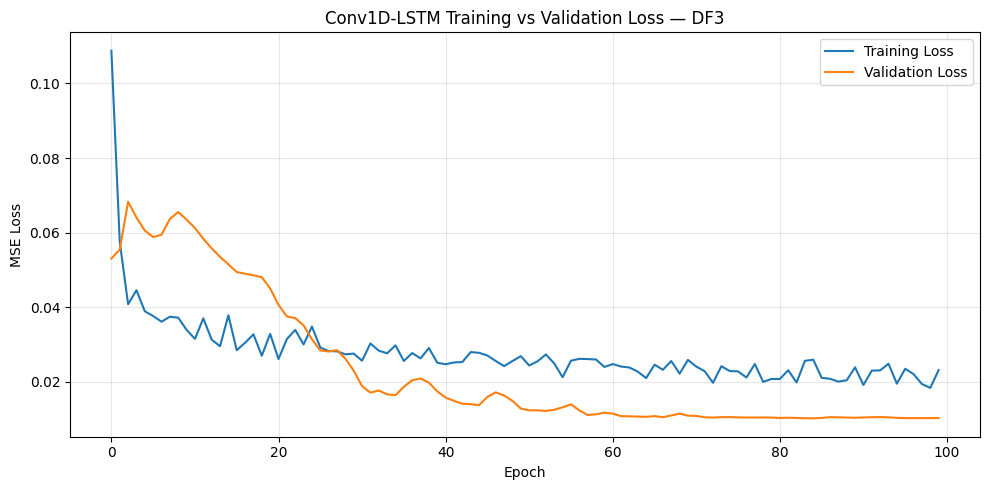

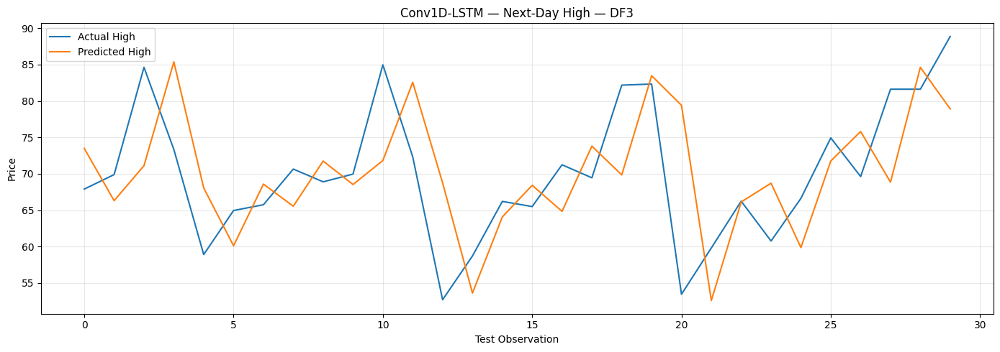

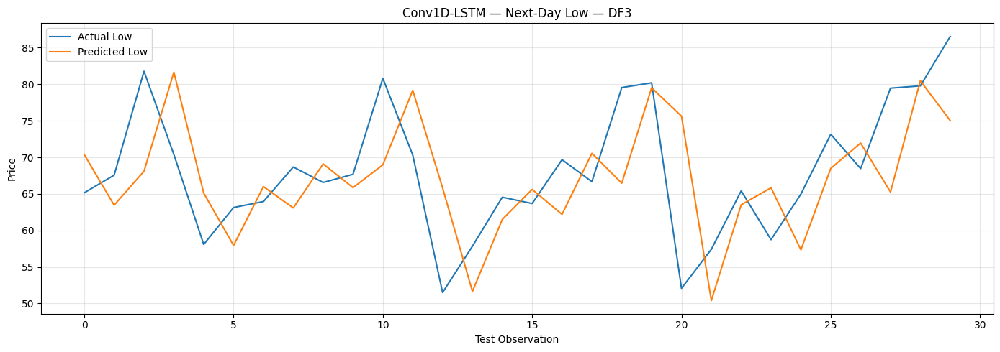



Conv1D-LSTM TRAINING — DF4
Total observations: 387
Train: 270
Validation: 58
Test: 59

Sequence shapes:
X_train: (245, 25, 4)
y_train: (245, 2)
X_val: (58, 25, 4)
y_val: (58, 2)
X_test: (59, 25, 4)
y_test: (59, 2)

Model architecture:


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_42 (Conv1D)              │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_22 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_45 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_43 (Conv1D)              │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_23 (Activation)      │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_46 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_47 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_8 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_48 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 143ms/step - loss: 0.1261 - mae: 0.2749 - val_loss: 0.1249 - val_mae: 0.3161 - learning_rate: 0.0010
Epoch 2/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0468 - mae: 0.1728 - val_loss: 0.1249 - val_mae: 0.3177 - learning_rate: 0.0010
Epoch 3/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0395 - mae: 0.1544 - val_loss: 0.1080 - val_mae: 0.2916 - learning_rate: 0.0010
Epoch 4/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0358 - mae: 0.1497 - val_loss: 0.0877 - val_mae: 0.2587 - learning_rate: 0.0010
Epoch 5/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0384 - mae: 0.1557 - val_loss: 0.0842 - val_mae: 0.2523 - learning_rate: 0.0010
Epoch 6/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0352 - mae: 0.1469 - val_loss: 0.0738 - val_mae: 0.2335 - learning_rate: 0.0010
Epoch 7/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0347 - mae: 0.1458 - val_loss: 0.0644 - val_mae: 0.2156 - learning_rate: 0.0010
Epoch 8/150
8/8 ━━━

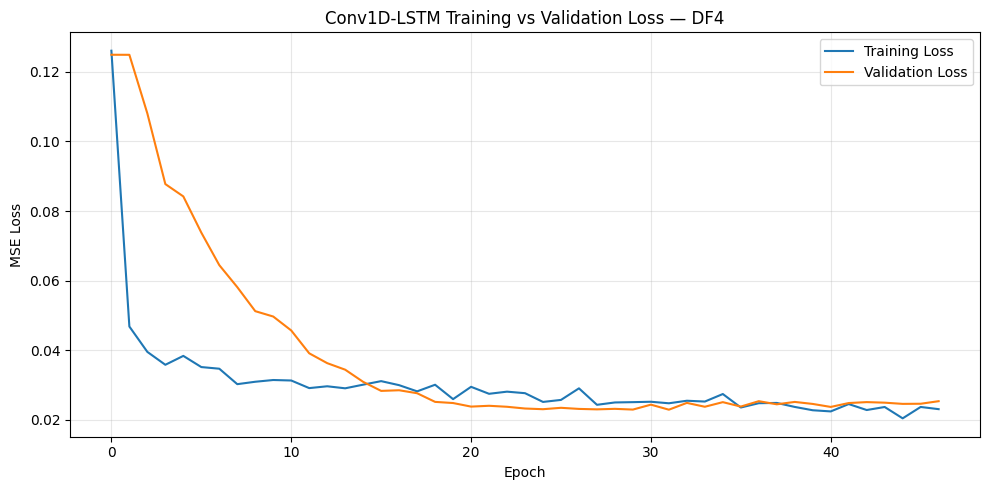

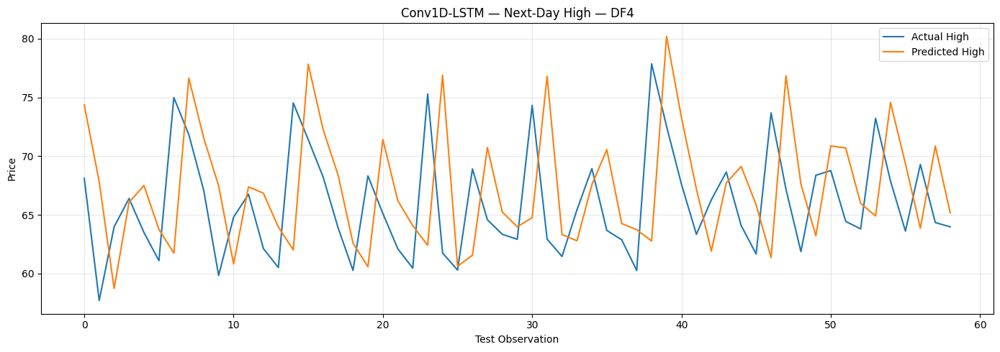

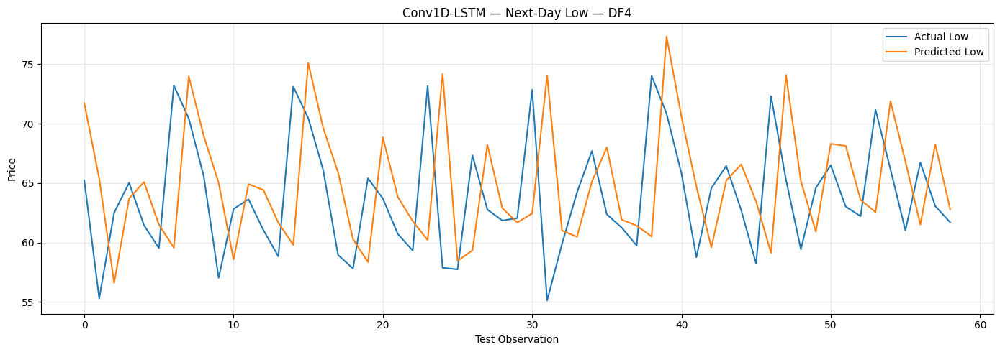



FINAL Conv1D-LSTM BASELINE RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Epoch
0,DF1,5.733519,7.280188,-0.824812,7.250849,7.054749,9.265406,-1.693251,9.312413,29
1,DF2,5.099972,7.143400,-0.054049,9.622597,5.313017,7.165039,-0.025516,10.262047,35
2,DF3,7.261471,9.065580,0.025116,10.741077,7.054902,8.725859,0.013738,10.672825,100
3,DF4,5.646211,6.775620,-1.209861,8.432139,5.514310,6.886385,-1.079320,8.574978,47



Results saved as: Conv1D_LSTM_baseline_results.csv
Predictions saved as: Conv1D_LSTM_baseline_predictions.xlsx


In [ ]:
# ============================================================
# Conv1D-LSTM BASELINE — NIFTY 50 REGIME-WISE FORECASTING
# Target: Next-Day High and Low
# Protocol: 70% Train / 15% Validation / 15% Test
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    Activation,
    Dropout,
    LSTM,
    Dense
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 2. FIXED BASELINE HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

# CNN
CONV_FILTERS = 64
KERNEL_SIZE = 3

# Regularization
DROPOUT = 0.20

# LSTM
LSTM_UNITS_1 = 64
LSTM_UNITS_2 = 32

# Dense
DENSE_UNITS = 16

# Training
LEARNING_RATE = 0.001
BATCH_SIZE = 32
EPOCHS = 150

# Callbacks
EARLY_STOPPING_PATIENCE = 15

LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 3. INPUT FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 4. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# ============================================================
# 5. PREPARE DATA
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(
    data["Date"]
)

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

# Ensure OHLC are numeric
for col in FEATURES:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 6. DEFINE MARKET REGIMES
# ============================================================

REGIMES = {

    "DF1": (
        "2007-01-01",
        "2011-12-31"
    ),

    "DF2": (
        "2012-01-01",
        "2019-12-31"
    ),

    "DF3": (
        "2020-01-01",
        "2022-12-31"
    ),

    "DF4": (
        "2023-01-01",
        None
    )
}


# ============================================================
# 7. CREATE NORMALIZED TARGETS
# ============================================================
#
# Predict:
#
#     High(t+1) / Close(t)
#     Low(t+1)  / Close(t)
#
# Then reconstruct:
#
#     Predicted High =
#         Predicted Ratio × Close(t)
#
#     Predicted Low =
#         Predicted Ratio × Close(t)
#
# ============================================================

data["Target_High_Ratio"] = (
    data["High"].shift(-1)
    / data["Close"]
)

data["Target_Low_Ratio"] = (
    data["Low"].shift(-1)
    / data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 8. TRAIN SEQUENCE CREATION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[i-lookback:i]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 9. VALIDATION / TEST SEQUENCE CREATION
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[
                i:i + lookback
            ]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. BUILD IMPROVED Conv1D-LSTM MODEL
# ============================================================

def build_conv1d_lstm_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )

    # ========================================================
    # CNN FEATURE EXTRACTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same"
    )(inputs)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND CNN LAYER
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same"
    )(x)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # LSTM TEMPORAL MODELING
    # ========================================================

    x = LSTM(
        LSTM_UNITS_1,
        return_sequences=True
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND LSTM
    # ========================================================

    x = LSTM(
        LSTM_UNITS_2,
        return_sequences=False
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # DENSE FORECASTING HEAD
    # ========================================================

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)


    # ========================================================
    # CREATE MODEL
    # ========================================================

    model = Model(
        inputs=inputs,
        outputs=outputs
    )


    # ========================================================
    # COMPILE
    # ========================================================

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 11. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return (
        mae,
        rmse,
        r2,
        mape
    )


# ============================================================
# 12. STORAGE
# ============================================================

all_results = []

all_predictions = {}

all_histories = {}

all_models = {}


# ============================================================
# 13. TRAIN EACH MARKET REGIME
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 75)
    print(
        f"Conv1D-LSTM TRAINING — {regime_name}"
    )
    print("=" * 75)


    # ========================================================
    # FILTER REGIME
    # ========================================================

    regime_data = data[
        data["Date"] >=
        pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )


    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )


    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            "insufficient observations."
        )

        continue


    # ========================================================
    # FEATURES / TARGETS
    # ========================================================

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # ========================================================
    # CHRONOLOGICAL 70 / 15 / 15 SPLIT
    # ========================================================

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )


    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]


    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]


    print(
        f"Train: "
        f"{len(X_train_raw)}"
    )

    print(
        f"Validation: "
        f"{len(X_val_raw)}"
    )

    print(
        f"Test: "
        f"{len(X_test_raw)}"
    )


    # ========================================================
    # 14. SCALE INPUTS — TRAIN ONLY
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 15. SCALE TARGETS — TRAIN ONLY
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 16. TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = (
        create_train_sequences(
            X_train_scaled,
            y_train_scaled,
            LOOKBACK
        )
    )


    # ========================================================
    # 17. VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = (
        create_partition_sequences(
            history_X=
                X_train_scaled[-LOOKBACK:],

            partition_X=
                X_val_scaled,

            partition_y=
                y_val_scaled,

            lookback=
                LOOKBACK
        )
    )


    # ========================================================
    # 18. TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = (
        create_partition_sequences(
            history_X=
                X_val_scaled[-LOOKBACK:],

            partition_X=
                X_test_scaled,

            partition_y=
                y_test_scaled,

            lookback=
                LOOKBACK
        )
    )


    print("\nSequence shapes:")

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "y_train:",
        y_train_seq.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "y_val:",
        y_val_seq.shape
    )

    print(
        "X_test:",
        X_test.shape
    )

    print(
        "y_test:",
        y_test_seq.shape
    )


    # ========================================================
    # 19. BUILD MODEL
    # ========================================================

    model = build_conv1d_lstm_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )

    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 20. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 21. TRAIN
    # ========================================================

    history = model.fit(

        X_train,
        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )


    # ========================================================
    # 22. PREDICT TEST SET
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 23. INVERSE TARGET SCALING
    # ========================================================

    y_pred_ratio = (
        y_scaler.inverse_transform(
            y_pred_scaled
        )
    )

    y_test_ratio = (
        y_scaler.inverse_transform(
            y_test_seq
        )
    )


    # ========================================================
    # 24. CURRENT CLOSE
    # ========================================================

    close_index = FEATURES.index(
        "Close"
    )

    current_close_test = X_test_raw[
        :,
        close_index
    ]


    # ========================================================
    # 25. RECONSTRUCT ABSOLUTE PRICES
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0]
        * current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0]
        * current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1]
        * current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * current_close_test
    )


    # ========================================================
    # 26. HIGH METRICS
    # ========================================================

    (
        high_mae,
        high_rmse,
        high_r2,
        high_mape
    ) = calculate_metrics(
        actual_high,
        predicted_high
    )


    # ========================================================
    # 27. LOW METRICS
    # ========================================================

    (
        low_mae,
        low_rmse,
        low_r2,
        low_mape
    ) = calculate_metrics(
        actual_low,
        predicted_low
    )


    # ========================================================
    # 28. PRINT RESULTS
    # ========================================================

    print("\n")
    print("=" * 75)
    print(
        f"Conv1D-LSTM RESULTS — {regime_name}"
    )
    print("=" * 75)


    print("\nNEXT-DAY HIGH")

    print(
        f"MAE  : {high_mae:.6f}"
    )

    print(
        f"RMSE : {high_rmse:.6f}"
    )

    print(
        f"R²   : {high_r2:.6f}"
    )

    print(
        f"MAPE : {high_mape:.6f}%"
    )


    print("\nNEXT-DAY LOW")

    print(
        f"MAE  : {low_mae:.6f}"
    )

    print(
        f"RMSE : {low_rmse:.6f}"
    )

    print(
        f"R²   : {low_r2:.6f}"
    )

    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 29. STORE RESULTS
    # ========================================================

    all_results.append({

        "Regime":
            regime_name,

        "High_MAE":
            high_mae,

        "High_RMSE":
            high_rmse,

        "High_R2":
            high_r2,

        "High_MAPE":
            high_mape,

        "Low_MAE":
            low_mae,

        "Low_RMSE":
            low_rmse,

        "Low_R2":
            low_r2,

        "Low_MAPE":
            low_mape,

        "Best_Epoch":
            len(
                history.history["loss"]
            )
    })


    # ========================================================
    # 30. STORE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values


    prediction_df = pd.DataFrame({

        "Date":
            test_dates,

        "Current_Close":
            current_close_test,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low

    })


    all_predictions[
        regime_name
    ] = prediction_df


    all_histories[
        regime_name
    ] = history.history


    all_models[
        regime_name
    ] = model


    # ========================================================
    # 31. TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"Conv1D-LSTM Training vs Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 32. HIGH PREDICTION PLOT
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"Conv1D-LSTM — Next-Day High — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. LOW PREDICTION PLOT
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"Conv1D-LSTM — Next-Day Low — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 34. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 95)
print("FINAL Conv1D-LSTM BASELINE RESULTS")
print("=" * 95)

display(
    results_df.round(6)
)


# ============================================================
# 35. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "Conv1D_LSTM_baseline_results.csv",
    index=False
)

print(
    "\nResults saved as:"
    " Conv1D_LSTM_baseline_results.csv"
)


# ============================================================
# 36. SAVE PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "Conv1D_LSTM_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in (
        all_predictions.items()
    ):

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )


print(
    "Predictions saved as:"
    " Conv1D_LSTM_baseline_predictions.xlsx"
)

In [2]:
df=pd.read_csv("crude_oil_2007_to_present.csv")



ConvLSTM-STYLE TRAINING — DF1
Total observations: 399
Train: 279
Validation: 60
Test: 60

Sequence shapes:
X_train: (254, 25, 4)
X_val: (60, 25, 4)
X_test: (60, 25, 4)

Model architecture:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 117ms/step - loss: 0.0459 - mae: 0.1658 - val_loss: 0.0696 - val_mae: 0.2516 - learning_rate: 0.0010
Epoch 2/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0295 - mae: 0.1232 - val_loss: 0.0590 - val_mae: 0.2315 - learning_rate: 0.0010
Epoch 3/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0278 - mae: 0.1169 - val_loss: 0.0500 - val_mae: 0.2122 - learning_rate: 0.0010
Epoch 4/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0265 - mae: 0.1108 - val_loss: 0.0398 - val_mae: 0.1873 - learning_rate: 0.0010
Epoch 5/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0245 - mae: 0.1060 - val_loss: 0.0316 - val_mae: 0.1645 - learning_rate: 0.0010
Epoch 6/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0254 - mae: 0.1086 - val_loss: 0.0261 - val_mae: 0.1471 - learning_rate: 0.0010
Epoch 7/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0241 - mae: 0.1109 - val_loss: 0.0200 - val_mae: 0.1230 - learning_rate: 0.0010
Epoch 8/150
8/8 ━━━

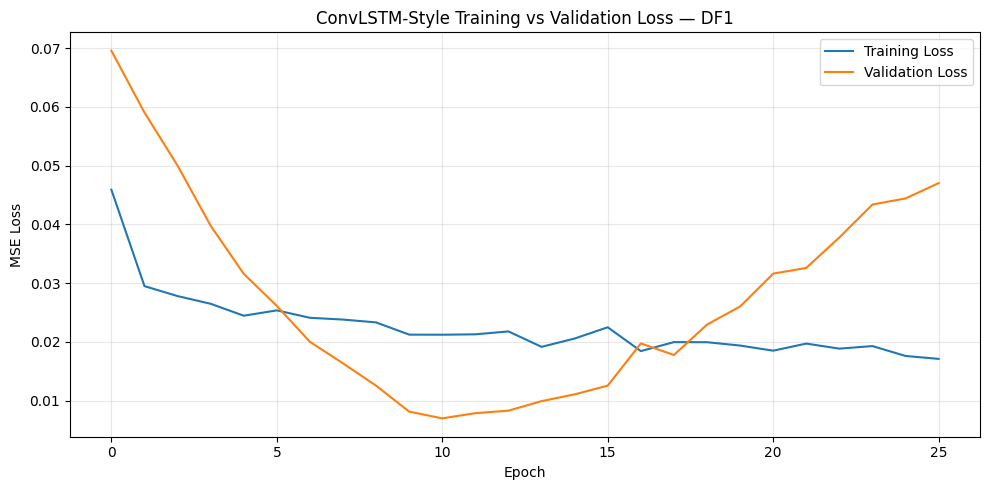

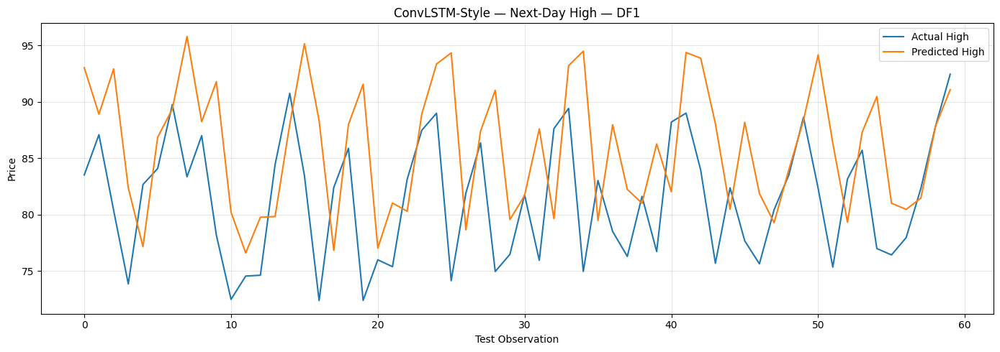

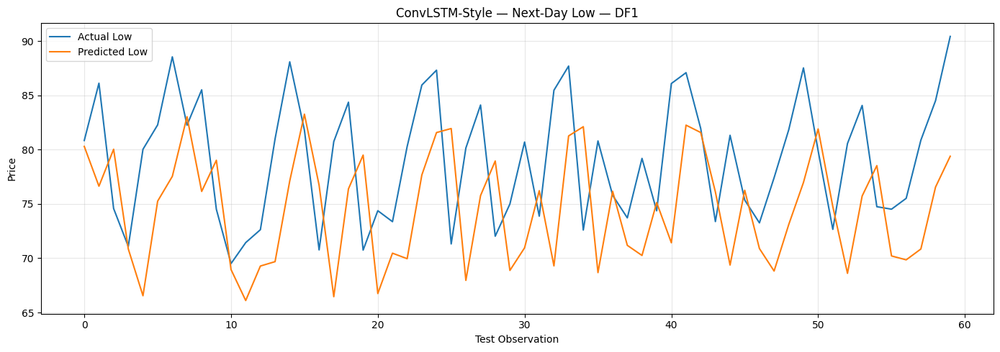



ConvLSTM-STYLE TRAINING — DF2
Total observations: 894
Train: 625
Validation: 134
Test: 135

Sequence shapes:
X_train: (600, 25, 4)
X_val: (134, 25, 4)
X_test: (135, 25, 4)

Model architecture:


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - loss: 0.0395 - mae: 0.1519 - val_loss: 0.0907 - val_mae: 0.2893 - learning_rate: 0.0010
Epoch 2/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0218 - mae: 0.1160 - val_loss: 0.0803 - val_mae: 0.2709 - learning_rate: 0.0010
Epoch 3/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0189 - mae: 0.1049 - val_loss: 0.0757 - val_mae: 0.2629 - learning_rate: 0.0010
Epoch 4/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0177 - mae: 0.0994 - val_loss: 0.0553 - val_mae: 0.2219 - learning_rate: 0.0010
Epoch 5/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0157 - mae: 0.0932 - val_loss: 0.0434 - val_mae: 0.1940 - learning_rate: 0.0010
Epoch 6/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0164 - mae: 0.0960 - val_loss: 0.0461 - val_mae: 0.2005 - learning_rate: 0.0010
Epoch 7/150
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0162 - mae: 0.0943 - val_loss: 0.0259 - val_mae: 0.1442 - learning_rate: 0.0010
Epoch 

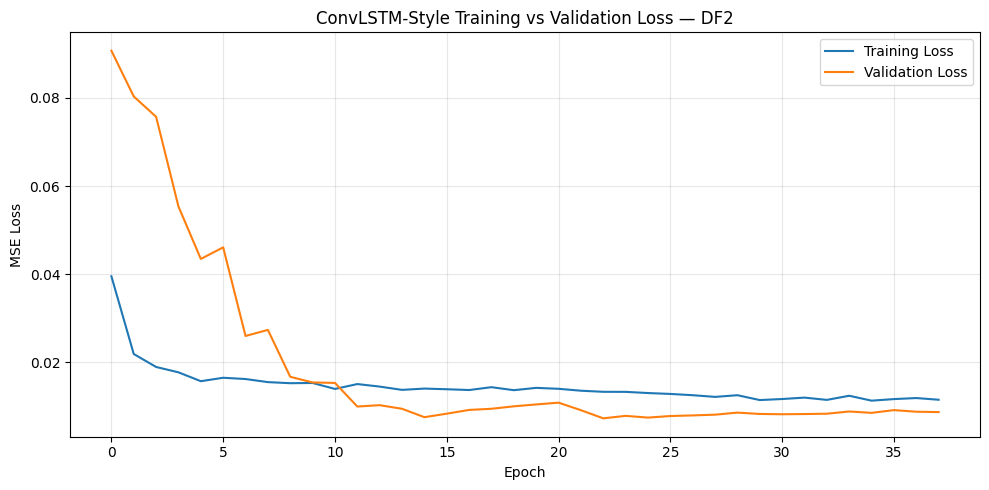

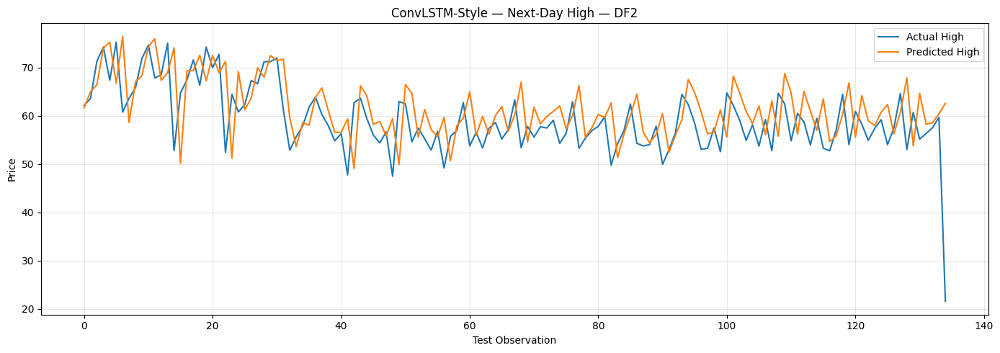

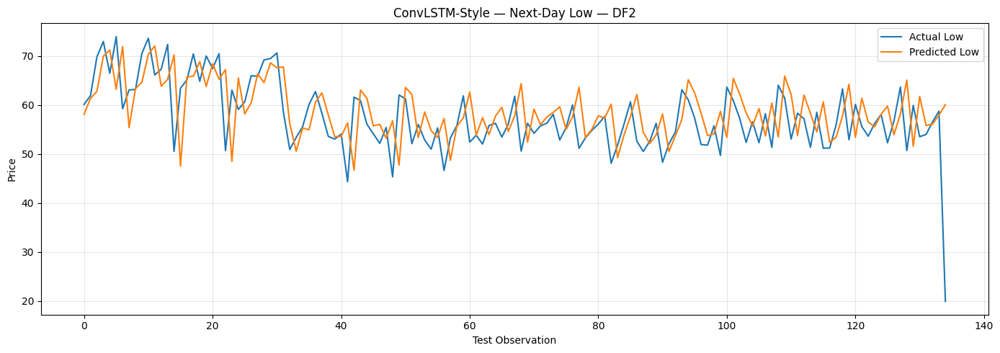



ConvLSTM-STYLE TRAINING — DF3
Total observations: 198
Train: 138
Validation: 30
Test: 30

Sequence shapes:
X_train: (113, 25, 4)
X_val: (30, 25, 4)
X_test: (30, 25, 4)

Model architecture:


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 211ms/step - loss: 0.1363 - mae: 0.2966 - val_loss: 0.1130 - val_mae: 0.3171 - learning_rate: 0.0010
Epoch 2/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.0636 - mae: 0.1930 - val_loss: 0.1127 - val_mae: 0.3177 - learning_rate: 0.0010
Epoch 3/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.0405 - mae: 0.1557 - val_loss: 0.0940 - val_mae: 0.2869 - learning_rate: 0.0010
Epoch 4/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0443 - mae: 0.1608 - val_loss: 0.0953 - val_mae: 0.2894 - learning_rate: 0.0010
Epoch 5/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.0413 - mae: 0.1483 - val_loss: 0.0956 - val_mae: 0.2901 - learning_rate: 0.0010
Epoch 6/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.0440 - mae: 0.1488 - val_loss: 0.0863 - val_mae: 0.2742 - learning_rate: 0.0010
Epoch 7/150
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.0418 - mae: 0.1514 - val_loss: 0.0929 - val_mae: 0.2857 - learning_rate: 0.0010
Epoch 8/150
4/4 ━━━

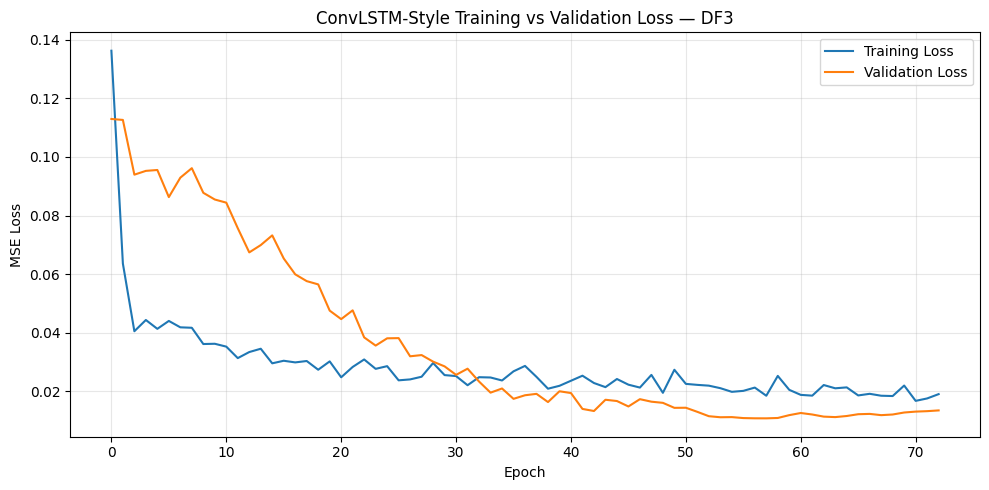

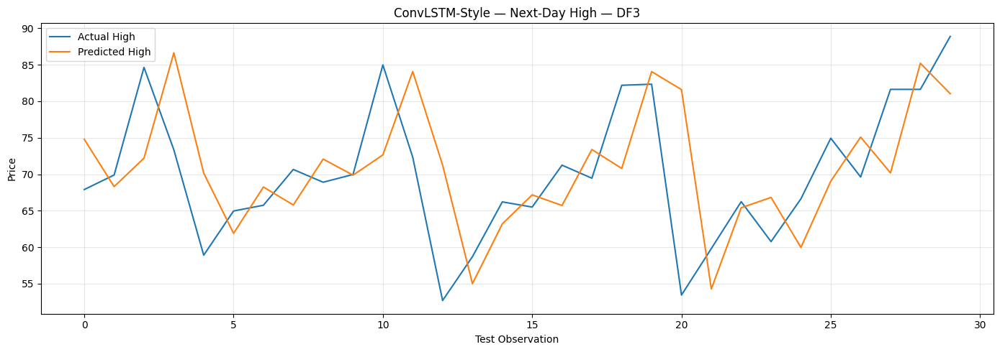

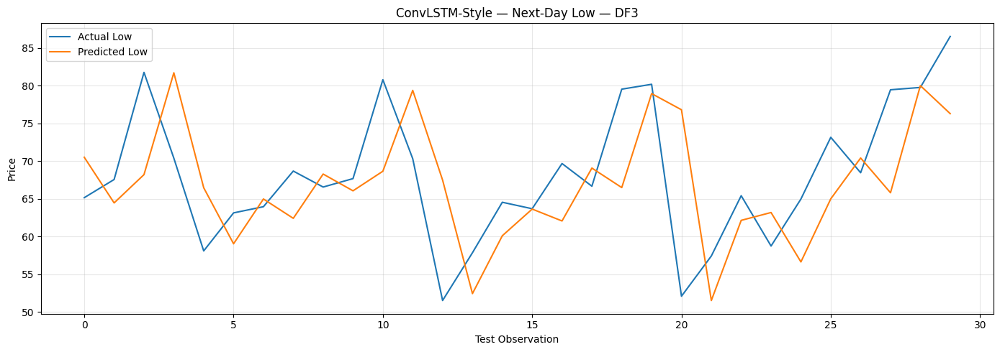



ConvLSTM-STYLE TRAINING — DF4
Total observations: 387
Train: 270
Validation: 58
Test: 59

Sequence shapes:
X_train: (245, 25, 4)
X_val: (58, 25, 4)
X_test: (59, 25, 4)

Model architecture:


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 25, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 25, 64)         │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 25, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 25, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,698 (233.20 KB)

 Trainable params: 59,442 (232.20 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - loss: 0.0934 - mae: 0.2325 - val_loss: 0.1448 - val_mae: 0.3476 - learning_rate: 0.0010
Epoch 2/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0463 - mae: 0.1680 - val_loss: 0.1413 - val_mae: 0.3416 - learning_rate: 0.0010
Epoch 3/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0373 - mae: 0.1466 - val_loss: 0.1232 - val_mae: 0.3148 - learning_rate: 0.0010
Epoch 4/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0384 - mae: 0.1528 - val_loss: 0.1179 - val_mae: 0.3062 - learning_rate: 0.0010
Epoch 5/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0352 - mae: 0.1477 - val_loss: 0.1094 - val_mae: 0.2929 - learning_rate: 0.0010
Epoch 6/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0353 - mae: 0.1484 - val_loss: 0.0995 - val_mae: 0.2780 - learning_rate: 0.0010
Epoch 7/150
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0328 - mae: 0.1420 - val_loss: 0.0928 - val_mae: 0.2666 - learning_rate: 0.0010
Epoch 8/150
8/8 ━━━

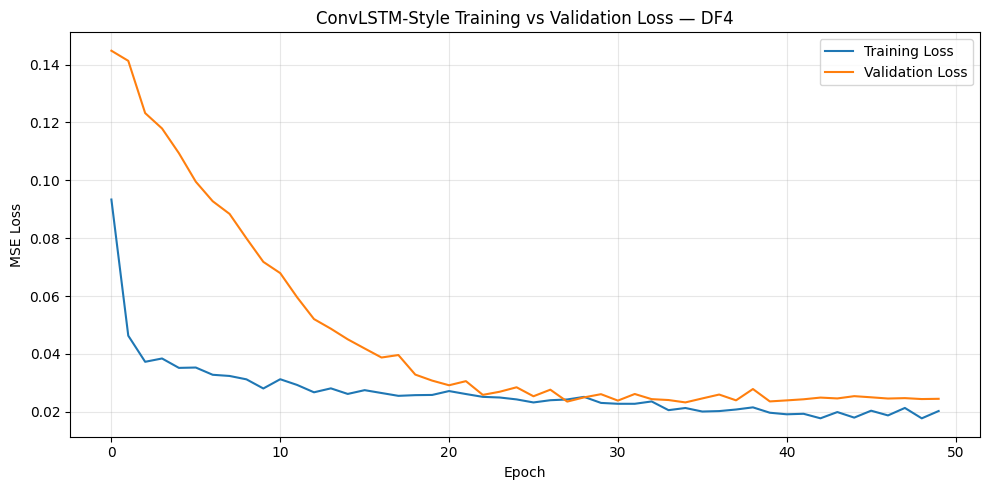

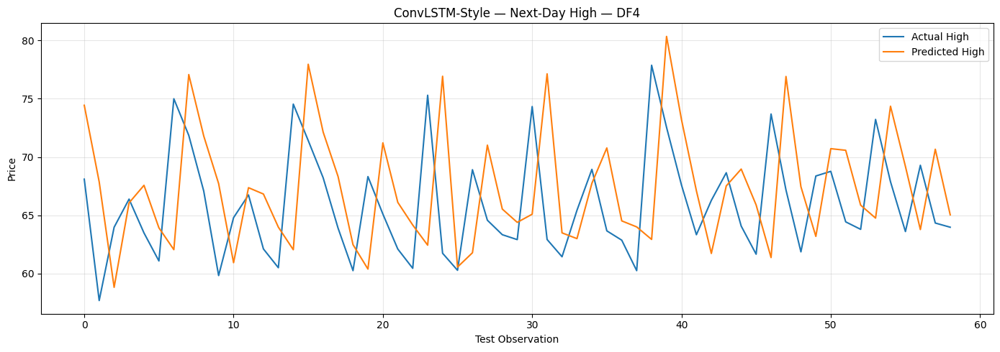

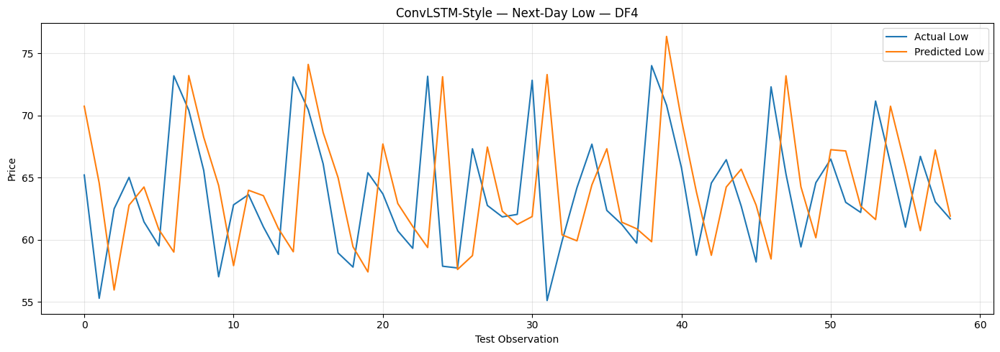



FINAL ConvLSTM-STYLE BASELINE RESULTS


,Regime,High_MAE,High_RMSE,High_R2,High_MAPE,Low_MAE,Low_RMSE,Low_R2,Low_MAPE,Best_Epoch
0,DF1,6.358567,8.316181,-1.381117,8.102973,6.883111,8.065725,-1.040961,8.559181,26
1,DF2,5.377537,7.596217,-0.191916,10.223666,5.367690,7.432102,-0.103389,10.511779,38
2,DF3,7.137588,9.254011,-0.015831,10.639828,6.965621,8.878954,-0.021174,10.554201,73
3,DF4,5.659384,6.775575,-1.209831,8.456159,5.180087,6.756309,-1.001510,8.005346,50



Results saved: ConvLSTM_style_baseline_results.csv
Predictions saved: ConvLSTM_style_baseline_predictions.xlsx


In [8]:
# ============================================================
# ConvLSTM-STYLE 1D BASELINE
# NIFTY 50 REGIME-WISE FORECASTING
#
# Target:
#   Next-Day High
#   Next-Day Low
#
# Protocol:
#   70% Train
#   15% Validation
#   15% Test
#
# Input:
#   Previous 25 trading days
#   Open, High, Low, Close
#
# IMPORTANT:
#   Baseline experiment only.
#   NO hyperparameter tuning yet.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    LSTM,
    Dropout,
    Dense,
    BatchNormalization,
    Activation,
    LayerNormalization
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass


# ============================================================
# 3. BASELINE HYPERPARAMETERS
# ============================================================

LOOKBACK = 25

# Convolution
CONV_FILTERS = 64
KERNEL_SIZE = 3

# Recurrent layers
LSTM_UNITS_1 = 64
LSTM_UNITS_2 = 32

# Regularization
DROPOUT = 0.20

# Dense
DENSE_UNITS = 16

# Optimizer
LEARNING_RATE = 0.001

# Training
BATCH_SIZE = 32
EPOCHS = 150

# Callbacks
EARLY_STOPPING_PATIENCE = 15

LR_PATIENCE = 7
LR_FACTOR = 0.5


# ============================================================
# 4. FEATURES
# ============================================================

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close"
]


# ============================================================
# 5. VERIFY DATA
# ============================================================

required_columns = FEATURES + ["Date"]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:

    raise ValueError(
        f"Missing columns: {missing_columns}"
    )


# ============================================================
# 6. PREPARE DATA
# ============================================================

data = df.copy()

data["Date"] = pd.to_datetime(
    data["Date"]
)

data = (
    data
    .sort_values("Date")
    .reset_index(drop=True)
)

for col in FEATURES:

    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

data = data.dropna(
    subset=FEATURES
).reset_index(drop=True)


# ============================================================
# 7. MARKET REGIMES
# ============================================================

REGIMES = {

    "DF1": (
        "2007-01-01",
        "2010-12-31"
    ),

    "DF2": (
        "2011-01-01",
        "2019-12-31"
    ),

    "DF3": (
        "2020-01-01",
        "2021-12-31"
    ),

    "DF4": (
        "2022-01-01",
        None
    )
}


# ============================================================
# 8. NORMALIZED NEXT-DAY TARGETS
# ============================================================

# High(t+1) / Close(t)
data["Target_High_Ratio"] = (
    data["High"].shift(-1)
    / data["Close"]
)

# Low(t+1) / Close(t)
data["Target_Low_Ratio"] = (
    data["Low"].shift(-1)
    / data["Close"]
)

data = data.dropna(
    subset=[
        "Target_High_Ratio",
        "Target_Low_Ratio"
    ]
).reset_index(drop=True)


# ============================================================
# 9. TRAIN SEQUENCE CREATION
# ============================================================

def create_train_sequences(
    X,
    y,
    lookback
):

    X_seq = []
    y_seq = []

    for i in range(
        lookback,
        len(X)
    ):

        X_seq.append(
            X[
                i - lookback:i
            ]
        )

        y_seq.append(
            y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 10. VALIDATION / TEST SEQUENCES
# ============================================================

def create_partition_sequences(
    history_X,
    partition_X,
    partition_y,
    lookback
):

    X_combined = np.concatenate(
        [
            history_X,
            partition_X
        ],
        axis=0
    )

    X_seq = []
    y_seq = []

    for i in range(
        len(partition_y)
    ):

        X_seq.append(
            X_combined[
                i:i + lookback
            ]
        )

        y_seq.append(
            partition_y[i]
        )

    return (
        np.array(X_seq),
        np.array(y_seq)
    )


# ============================================================
# 11. CUSTOM CONVOLUTION-RECURRENT BLOCK
# ============================================================
#
# The idea is:
#
#   Convolution
#       ↓
#   Short-term feature extraction
#       ↓
#   LSTM
#       ↓
#   Temporal memory
#
# This gives the model convolutional processing before
# recurrent temporal modeling.
#
# ============================================================

def build_convlstm_style_model(
    input_shape
):

    inputs = Input(
        shape=input_shape
    )


    # ========================================================
    # LOCAL TEMPORAL FEATURE EXTRACTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same",
        activation=None
    )(inputs)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND CONVOLUTION
    # ========================================================

    x = Conv1D(
        filters=CONV_FILTERS,
        kernel_size=KERNEL_SIZE,
        padding="same",
        activation=None
    )(x)

    x = BatchNormalization()(x)

    x = Activation(
        "relu"
    )(x)


    # ========================================================
    # TEMPORAL RECURRENT MEMORY
    # ========================================================

    x = LSTM(
        LSTM_UNITS_1,
        return_sequences=True
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # SECOND RECURRENT LAYER
    # ========================================================

    x = LSTM(
        LSTM_UNITS_2,
        return_sequences=False
    )(x)

    x = Dropout(
        DROPOUT
    )(x)


    # ========================================================
    # FORECASTING HEAD
    # ========================================================

    x = Dense(
        DENSE_UNITS,
        activation="relu"
    )(x)

    outputs = Dense(
        2,
        activation="linear"
    )(x)


    # ========================================================
    # MODEL
    # ========================================================

    model = Model(
        inputs=inputs,
        outputs=outputs
    )


    # ========================================================
    # COMPILE
    # ========================================================

    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 12. METRICS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    denominator = np.where(
        np.abs(y_true) < 1e-8,
        1e-8,
        np.abs(y_true)
    )

    mape = np.mean(
        np.abs(
            (y_true - y_pred)
            / denominator
        )
    ) * 100

    return (
        mae,
        rmse,
        r2,
        mape
    )


# ============================================================
# 13. STORAGE
# ============================================================

all_results = []

all_predictions = {}

all_histories = {}

all_models = {}


# ============================================================
# 14. REGIME LOOP
# ============================================================

for regime_name, (
    start_date,
    end_date
) in REGIMES.items():

    print("\n")
    print("=" * 80)
    print(
        f"ConvLSTM-STYLE TRAINING — {regime_name}"
    )
    print("=" * 80)


    # ========================================================
    # FILTER REGIME
    # ========================================================

    regime_data = data[
        data["Date"] >=
        pd.Timestamp(start_date)
    ].copy()

    if end_date is not None:

        regime_data = regime_data[
            regime_data["Date"] <=
            pd.Timestamp(end_date)
        ]

    regime_data = (
        regime_data
        .sort_values("Date")
        .reset_index(drop=True)
    )


    print(
        f"Total observations: "
        f"{len(regime_data)}"
    )


    if len(regime_data) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            "insufficient observations."
        )

        continue


    # ========================================================
    # X / Y
    # ========================================================

    X_raw = regime_data[
        FEATURES
    ].values

    y_raw = regime_data[
        [
            "Target_High_Ratio",
            "Target_Low_Ratio"
        ]
    ].values


    # ========================================================
    # 70 / 15 / 15 CHRONOLOGICAL SPLIT
    # ========================================================

    n = len(regime_data)

    train_end = int(
        n * 0.70
    )

    val_end = int(
        n * 0.85
    )


    X_train_raw = X_raw[
        :train_end
    ]

    X_val_raw = X_raw[
        train_end:val_end
    ]

    X_test_raw = X_raw[
        val_end:
    ]


    y_train = y_raw[
        :train_end
    ]

    y_val = y_raw[
        train_end:val_end
    ]

    y_test = y_raw[
        val_end:
    ]


    print(
        f"Train: {len(X_train_raw)}"
    )

    print(
        f"Validation: {len(X_val_raw)}"
    )

    print(
        f"Test: {len(X_test_raw)}"
    )


    # ========================================================
    # 15. TRAIN-ONLY INPUT SCALING
    # ========================================================

    X_scaler = MinMaxScaler()

    X_scaler.fit(
        X_train_raw
    )

    X_train_scaled = X_scaler.transform(
        X_train_raw
    )

    X_val_scaled = X_scaler.transform(
        X_val_raw
    )

    X_test_scaled = X_scaler.transform(
        X_test_raw
    )


    # ========================================================
    # 16. TRAIN-ONLY TARGET SCALING
    # ========================================================

    y_scaler = MinMaxScaler()

    y_scaler.fit(
        y_train
    )

    y_train_scaled = y_scaler.transform(
        y_train
    )

    y_val_scaled = y_scaler.transform(
        y_val
    )

    y_test_scaled = y_scaler.transform(
        y_test
    )


    # ========================================================
    # 17. TRAIN SEQUENCES
    # ========================================================

    X_train, y_train_seq = (
        create_train_sequences(
            X_train_scaled,
            y_train_scaled,
            LOOKBACK
        )
    )


    # ========================================================
    # 18. VALIDATION SEQUENCES
    # ========================================================

    X_val, y_val_seq = (
        create_partition_sequences(
            history_X=
                X_train_scaled[-LOOKBACK:],

            partition_X=
                X_val_scaled,

            partition_y=
                y_val_scaled,

            lookback=
                LOOKBACK
        )
    )


    # ========================================================
    # 19. TEST SEQUENCES
    # ========================================================

    X_test, y_test_seq = (
        create_partition_sequences(
            history_X=
                X_val_scaled[-LOOKBACK:],

            partition_X=
                X_test_scaled,

            partition_y=
                y_test_scaled,

            lookback=
                LOOKBACK
        )
    )


    print("\nSequence shapes:")

    print(
        "X_train:",
        X_train.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "X_test:",
        X_test.shape
    )


    # ========================================================
    # 20. BUILD MODEL
    # ========================================================

    model = build_convlstm_style_model(
        input_shape=(
            LOOKBACK,
            len(FEATURES)
        )
    )


    print("\nModel architecture:")

    model.summary()


    # ========================================================
    # 21. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=LR_FACTOR,
        patience=LR_PATIENCE,
        min_lr=1e-6,
        verbose=1
    )


    # ========================================================
    # 22. TRAIN
    # ========================================================

    history = model.fit(

        X_train,

        y_train_seq,

        validation_data=(
            X_val,
            y_val_seq
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        shuffle=False,

        verbose=1
    )


    # ========================================================
    # 23. TEST PREDICTION
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 24. INVERSE TARGET SCALING
    # ========================================================

    y_pred_ratio = (
        y_scaler.inverse_transform(
            y_pred_scaled
        )
    )

    y_test_ratio = (
        y_scaler.inverse_transform(
            y_test_seq
        )
    )


    # ========================================================
    # 25. CURRENT CLOSE
    # ========================================================

    close_index = FEATURES.index(
        "Close"
    )

    current_close_test = X_test_raw[
        :,
        close_index
    ]


    # ========================================================
    # 26. RECONSTRUCT ABSOLUTE HIGH / LOW
    # ========================================================

    actual_high = (
        y_test_ratio[:, 0]
        * current_close_test
    )

    predicted_high = (
        y_pred_ratio[:, 0]
        * current_close_test
    )

    actual_low = (
        y_test_ratio[:, 1]
        * current_close_test
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * current_close_test
    )


    # ========================================================
    # 27. METRICS — HIGH
    # ========================================================

    (
        high_mae,
        high_rmse,
        high_r2,
        high_mape
    ) = calculate_metrics(
        actual_high,
        predicted_high
    )


    # ========================================================
    # 28. METRICS — LOW
    # ========================================================

    (
        low_mae,
        low_rmse,
        low_r2,
        low_mape
    ) = calculate_metrics(
        actual_low,
        predicted_low
    )


    # ========================================================
    # 29. RESULTS
    # ========================================================

    print("\n")
    print("=" * 80)
    print(
        f"ConvLSTM-STYLE RESULTS — {regime_name}"
    )
    print("=" * 80)


    print("\nNEXT-DAY HIGH")

    print(
        f"MAE  : {high_mae:.6f}"
    )

    print(
        f"RMSE : {high_rmse:.6f}"
    )

    print(
        f"R²   : {high_r2:.6f}"
    )

    print(
        f"MAPE : {high_mape:.6f}%"
    )


    print("\nNEXT-DAY LOW")

    print(
        f"MAE  : {low_mae:.6f}"
    )

    print(
        f"RMSE : {low_rmse:.6f}"
    )

    print(
        f"R²   : {low_r2:.6f}"
    )

    print(
        f"MAPE : {low_mape:.6f}%"
    )


    # ========================================================
    # 30. SAVE RESULTS
    # ========================================================

    all_results.append({

        "Regime":
            regime_name,

        "High_MAE":
            high_mae,

        "High_RMSE":
            high_rmse,

        "High_R2":
            high_r2,

        "High_MAPE":
            high_mape,

        "Low_MAE":
            low_mae,

        "Low_RMSE":
            low_rmse,

        "Low_R2":
            low_r2,

        "Low_MAPE":
            low_mape,

        "Best_Epoch":
            len(
                history.history["loss"]
            )

    })


    # ========================================================
    # 31. SAVE PREDICTIONS
    # ========================================================

    test_dates = regime_data[
        "Date"
    ].iloc[
        val_end:
    ].values


    prediction_df = pd.DataFrame({

        "Date":
            test_dates,

        "Current_Close":
            current_close_test,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low

    })


    all_predictions[
        regime_name
    ] = prediction_df


    all_histories[
        regime_name
    ] = history.history


    all_models[
        regime_name
    ] = model


    # ========================================================
    # 32. LOSS CURVE
    # ========================================================

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"ConvLSTM-Style Training vs Validation Loss — {regime_name}"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE Loss"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 33. HIGH PREDICTION
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_high,
        label="Actual High"
    )

    plt.plot(
        predicted_high,
        label="Predicted High"
    )

    plt.title(
        f"ConvLSTM-Style — Next-Day High — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # 34. LOW PREDICTION
    # ========================================================

    plt.figure(
        figsize=(14, 5)
    )

    plt.plot(
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        predicted_low,
        label="Predicted Low"
    )

    plt.title(
        f"ConvLSTM-Style — Next-Day Low — {regime_name}"
    )

    plt.xlabel(
        "Test Observation"
    )

    plt.ylabel(
        "Price"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 35. FINAL RESULTS
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 100)
print("FINAL ConvLSTM-STYLE BASELINE RESULTS")
print("=" * 100)

display(
    results_df.round(6)
)


# ============================================================
# 36. SAVE RESULTS
# ============================================================

results_df.to_csv(
    "ConvLSTM_style_baseline_results.csv",
    index=False
)

print(
    "\nResults saved:"
    " ConvLSTM_style_baseline_results.csv"
)


# ============================================================
# 37. SAVE PREDICTIONS
# ============================================================

with pd.ExcelWriter(
    "ConvLSTM_style_baseline_predictions.xlsx",
    engine="openpyxl"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Results",
        index=False
    )

    for regime_name, prediction_df in (
        all_predictions.items()
    ):

        prediction_df.to_excel(
            writer,
            sheet_name=regime_name,
            index=False
        )

print(
    "Predictions saved:"
    " ConvLSTM_style_baseline_predictions.xlsx"
)

TensorFlow: 2.17.0
Seed: 42
Original shape: (1879, 7)


RUNNING DF1
2007 - 2011
Regime observations: 499
Train: 348
Validation: 75
Test: 75
X_train: (323, 25, 4)
X_val: (75, 25, 4)
X_test: (75, 25, 4)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_8 (Bidirectional) │ (None, 25, 128)        │        35,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_9 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 124ms/step - loss: 0.0539 - val_loss: 0.0168 - learning_rate: 0.0010
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0303 - val_loss: 0.0123 - learning_rate: 0.0010
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0294 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0249 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0255 - val_loss: 0.0026 - learning_rate: 0.0010
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0232 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0229 - val_loss: 0.0027 - learning_rate: 0.0010
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0223 - val_loss: 0.0029 - learning_rate: 0.0010
Epoch 9/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0218 - val_loss: 0.0026 - learning_rate: 0.0010
Epoch 10

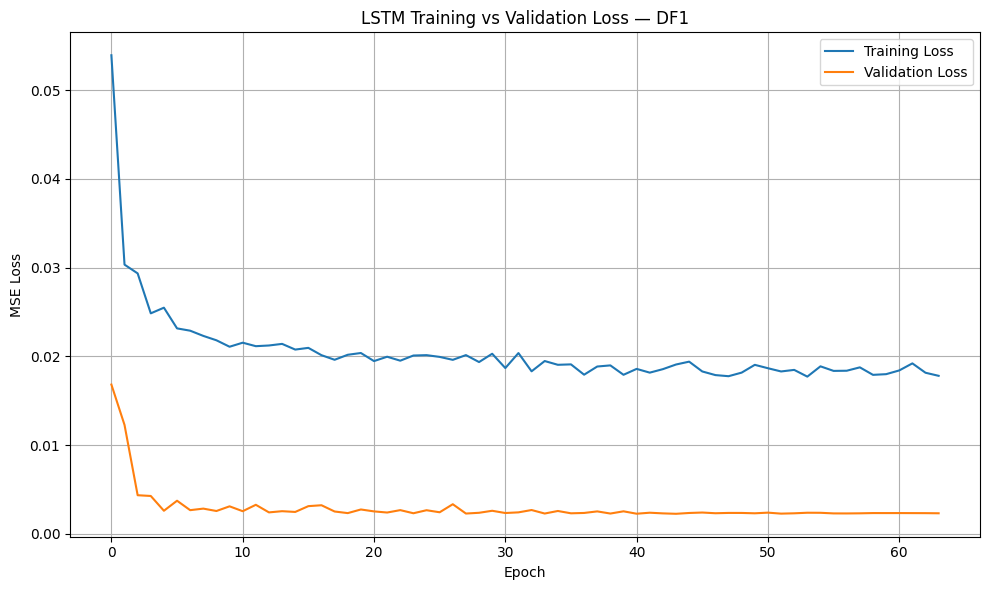

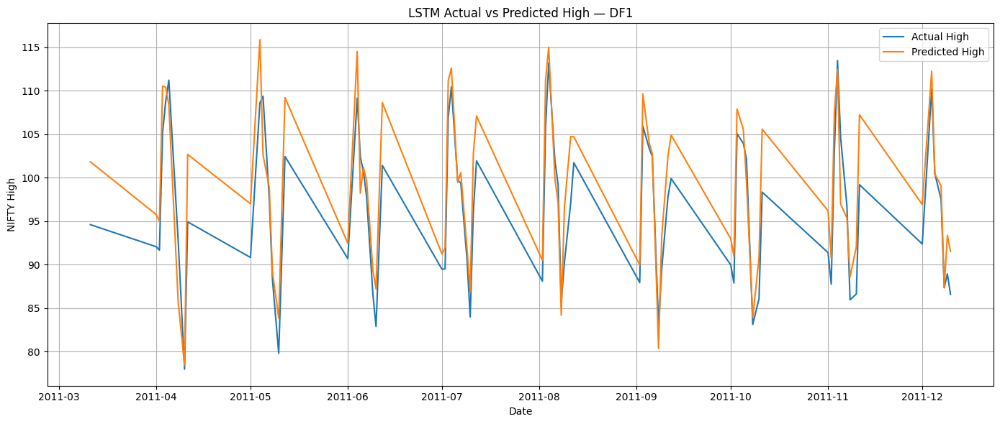

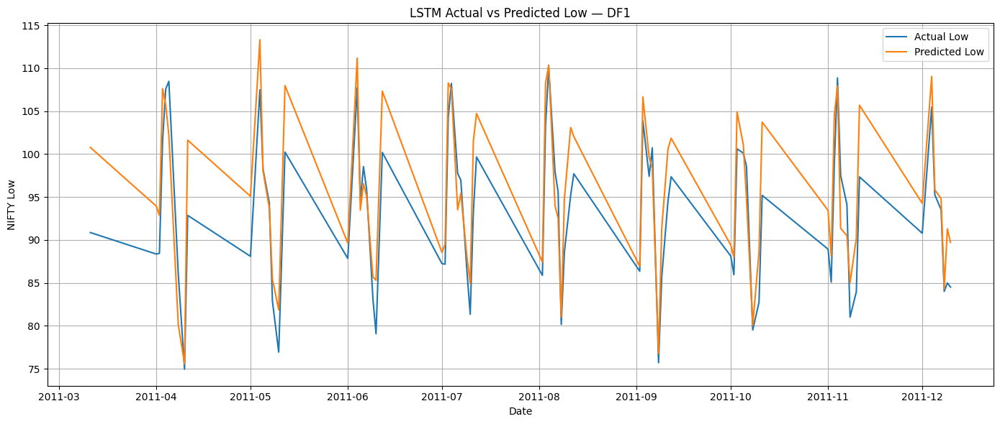

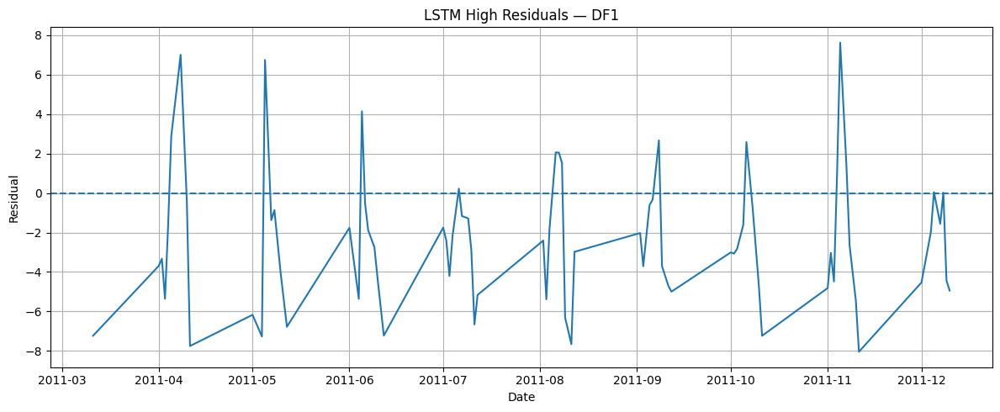

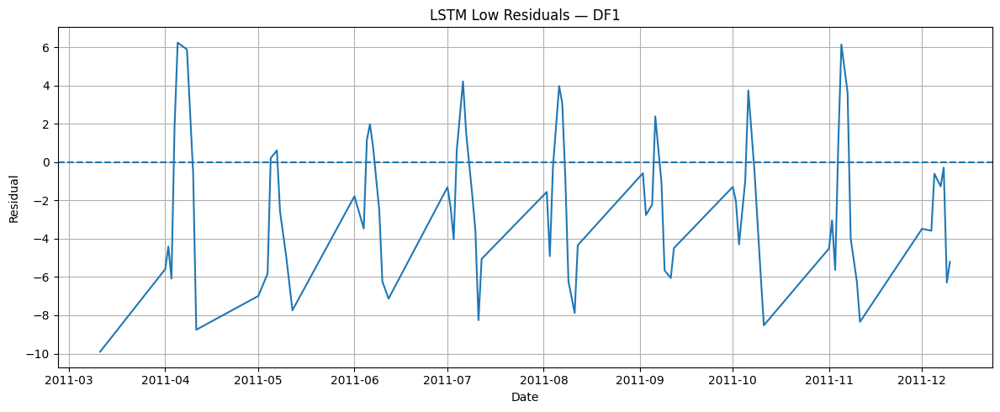

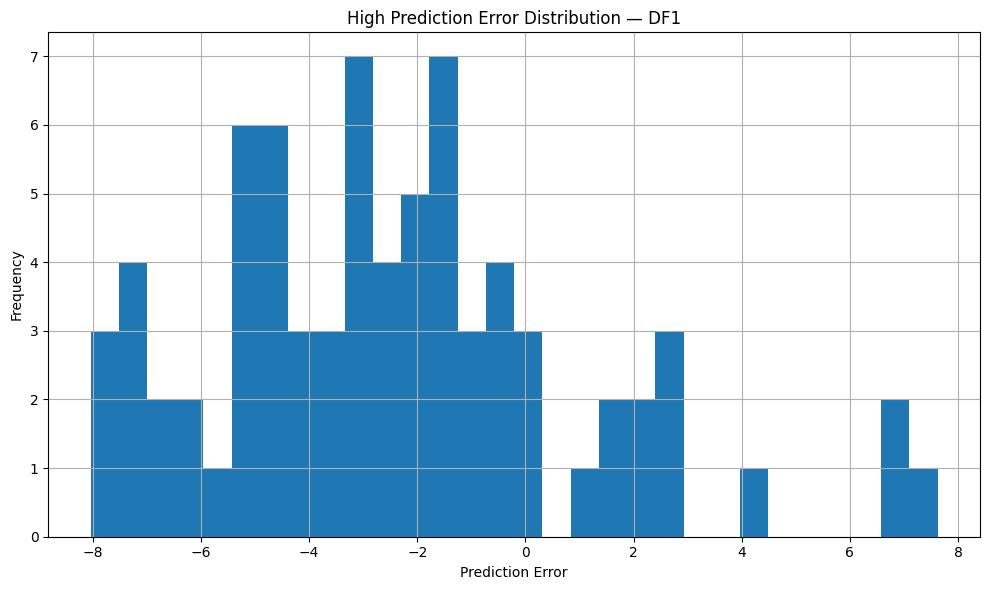

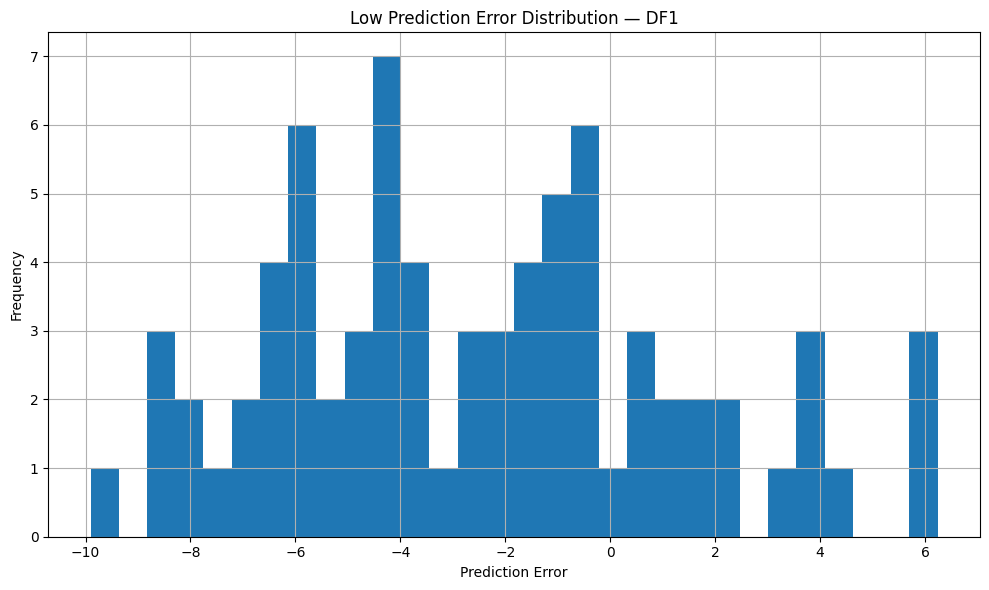


DF1 completed.


RUNNING DF2
2012 - 2019
Regime observations: 794
Train: 555
Validation: 119
Test: 119
X_train: (530, 25, 4)
X_val: (119, 25, 4)
X_test: (119, 25, 4)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_10                │ (None, 25, 128)        │        35,328 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_11                │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - loss: 0.0629 - val_loss: 0.0399 - learning_rate: 0.0010
Epoch 2/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0845 - val_loss: 0.0385 - learning_rate: 0.0010
Epoch 3/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0263 - val_loss: 0.0117 - learning_rate: 0.0010
Epoch 4/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0310 - val_loss: 0.0099 - learning_rate: 0.0010
Epoch 5/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0201 - val_loss: 0.0083 - learning_rate: 0.0010
Epoch 6/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0197 - val_loss: 0.0078 - learning_rate: 0.0010
Epoch 7/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0188 - val_loss: 0.0079 - learning_rate: 0.0010
Epoch 8/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0184 - val_loss: 0.0078 - learning_rate: 0.0010
Epoch 9/200
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0182 - val_loss: 0.0078 - learning_rate: 0.0010
Epoch 10/2

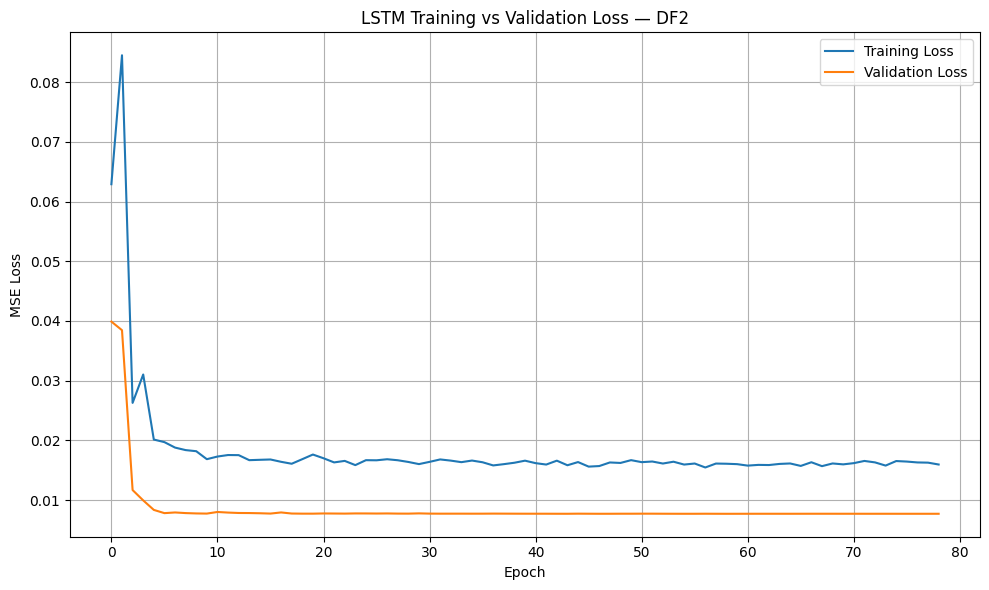

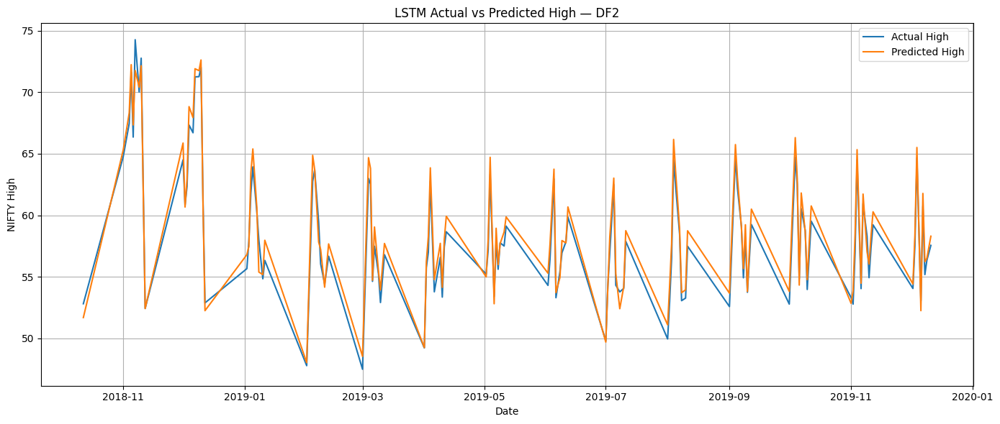

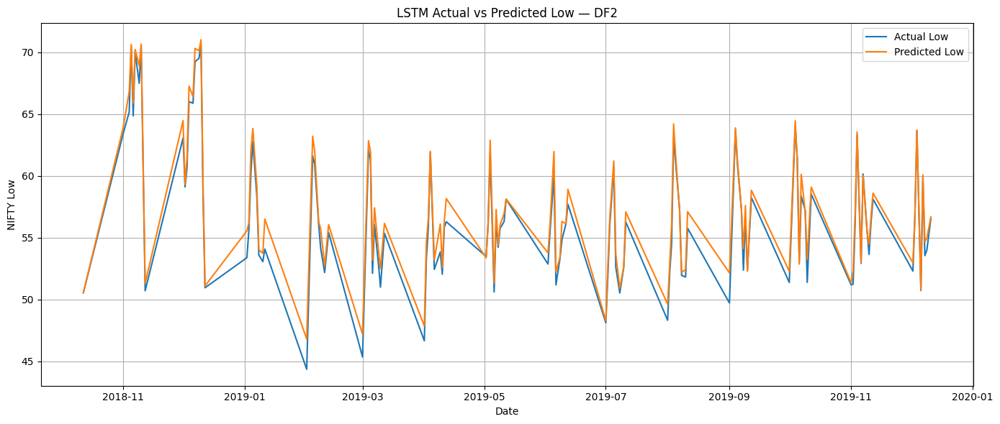

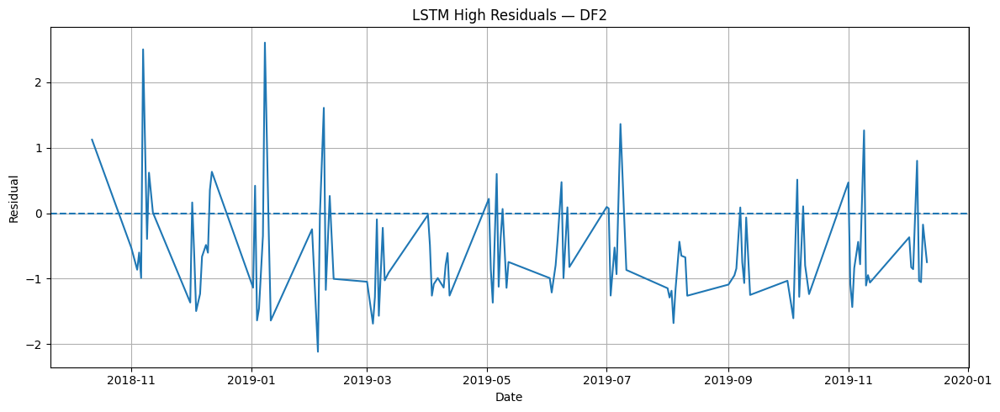

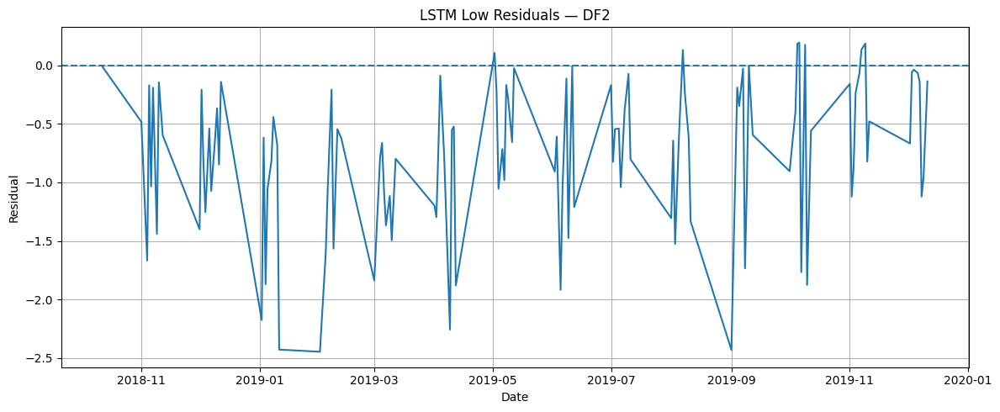

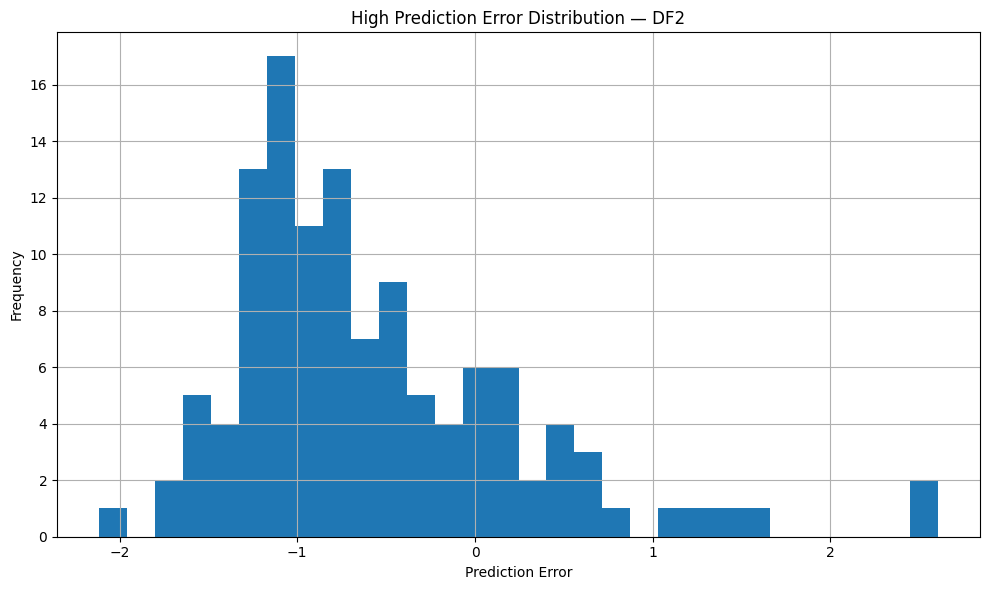

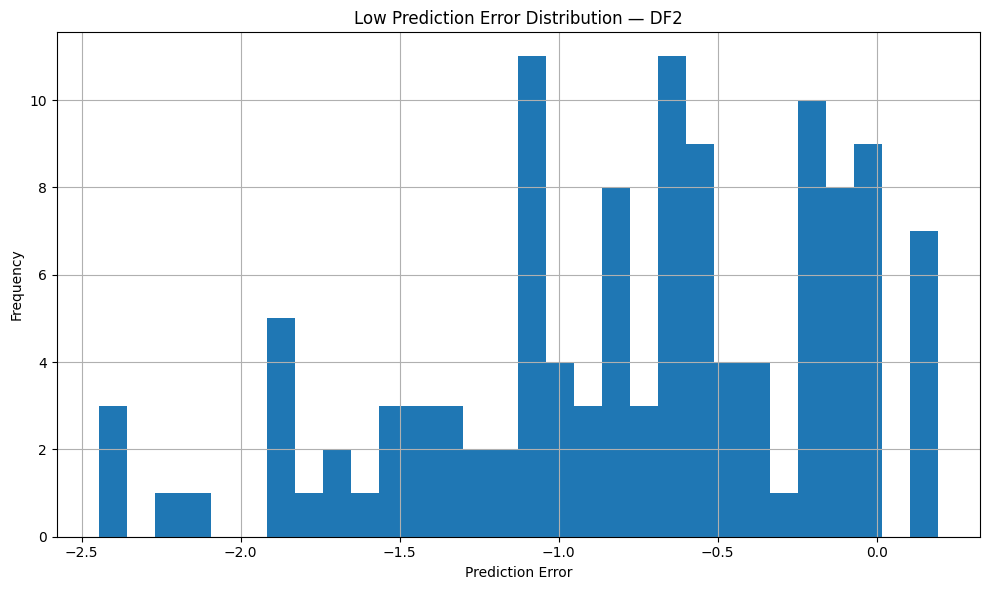


DF2 completed.


RUNNING DF3
2020 - 2022
Regime observations: 298
Train: 207
Validation: 45
Test: 45
X_train: (182, 25, 4)
X_val: (45, 25, 4)
X_test: (45, 25, 4)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_12                │ (None, 25, 128)        │        35,328 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_44 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_13                │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_45 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 216ms/step - loss: 0.1202 - val_loss: 0.0973 - learning_rate: 0.0010
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0756 - val_loss: 0.0842 - learning_rate: 0.0010
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0393 - val_loss: 0.0221 - learning_rate: 0.0010
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0476 - val_loss: 0.0290 - learning_rate: 0.0010
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0440 - val_loss: 0.0465 - learning_rate: 0.0010
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0389 - val_loss: 0.0396 - learning_rate: 0.0010
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0343 - val_loss: 0.0238 - learning_rate: 0.0010
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0334 - val_loss: 0.0209 - learning_rate: 0.0010
Epoch 9/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0331 - val_loss: 0.0226 - learning_rate: 0.0010
Epoch 10/200
6/6 ━━━━━━━━━━

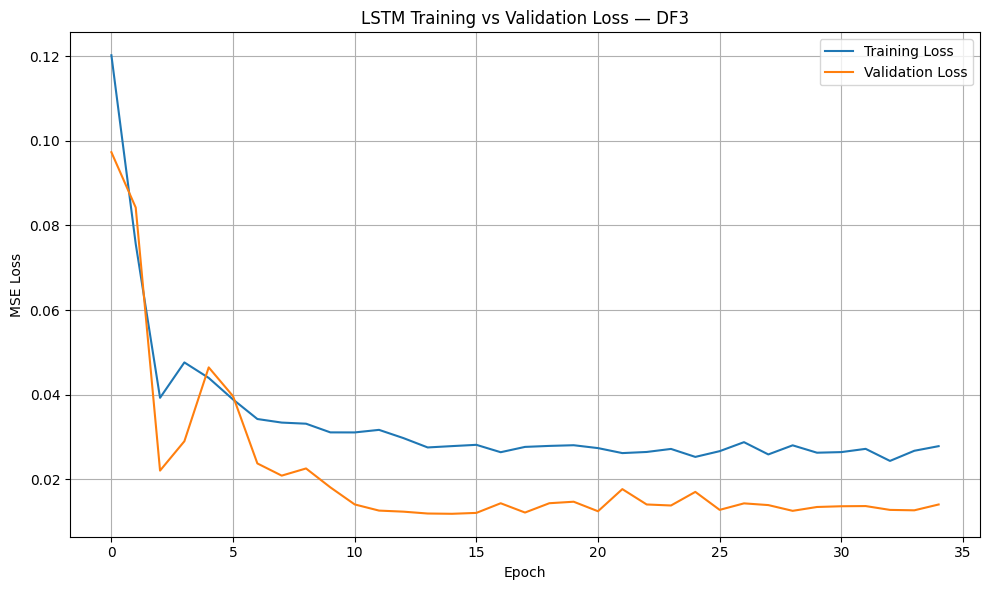

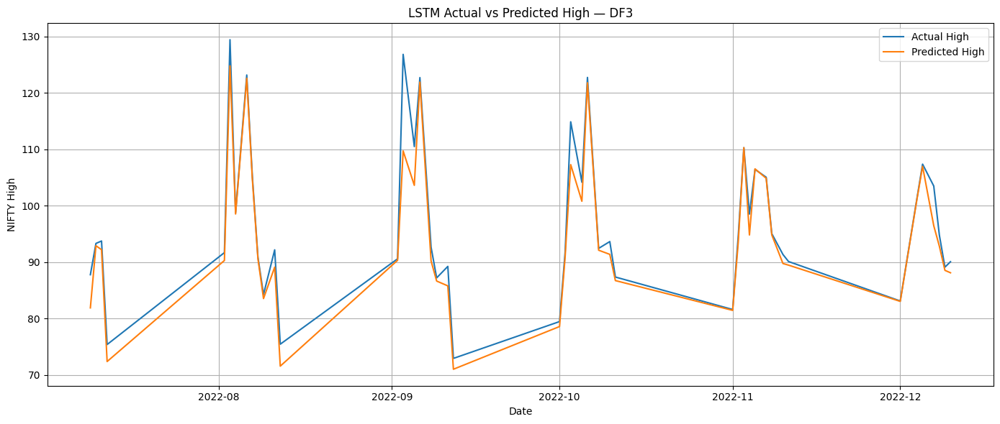

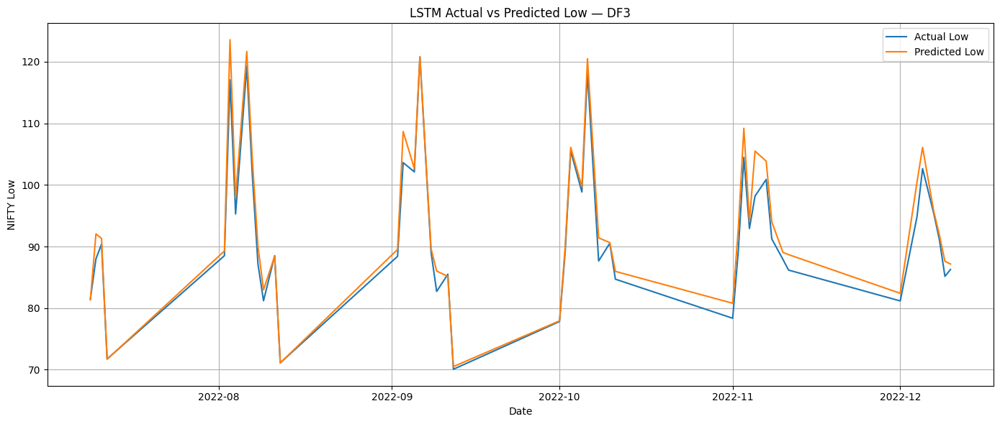

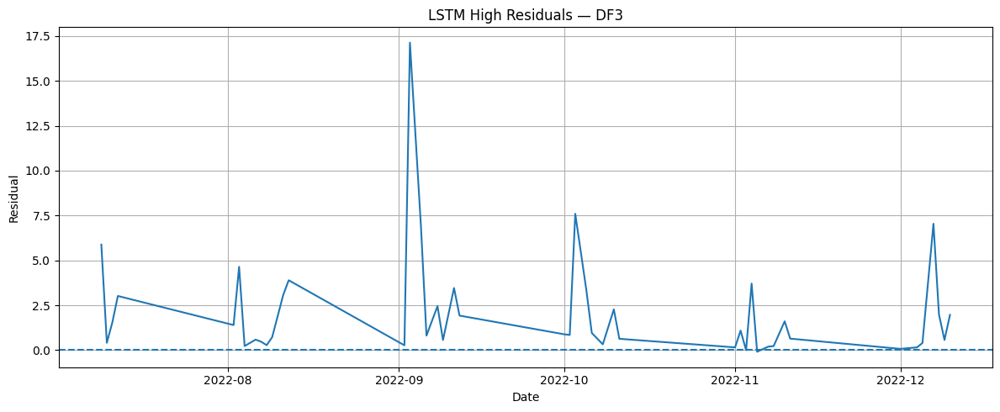

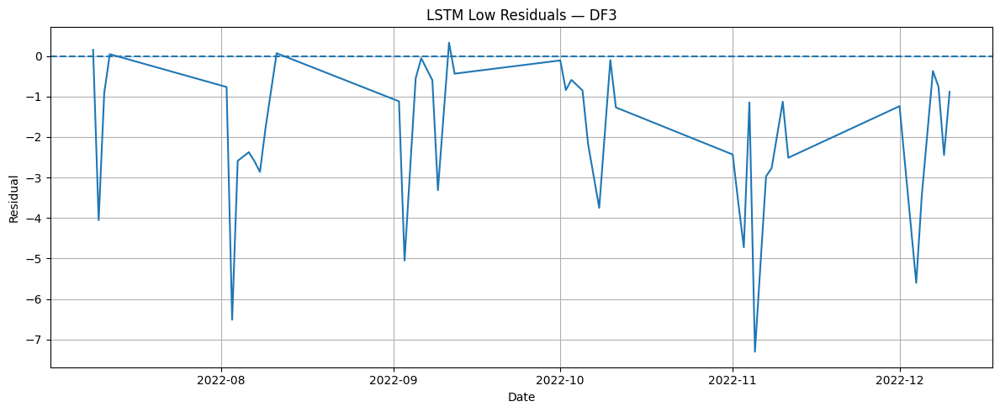

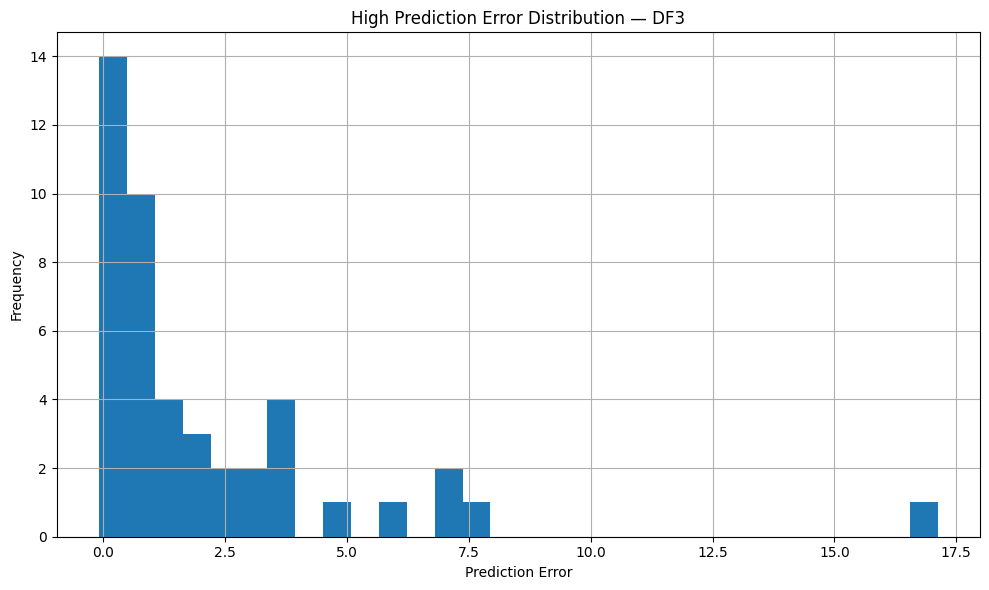

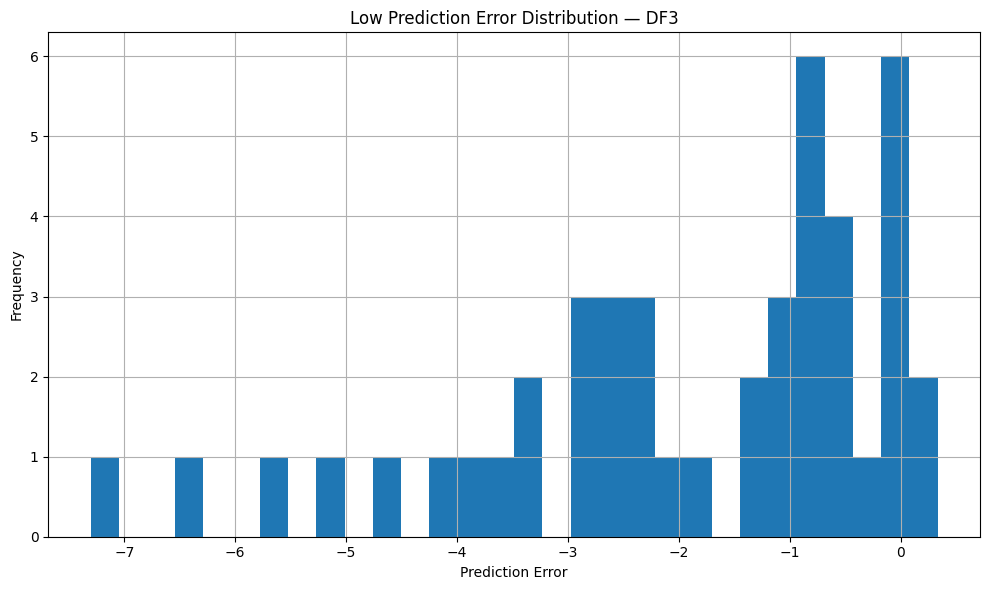


DF3 completed.


RUNNING DF4
2023 - 2025
Regime observations: 288
Train: 200
Validation: 43
Test: 44
X_train: (175, 25, 4)
X_val: (43, 25, 4)
X_test: (44, 25, 4)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_14                │ (None, 25, 128)        │        35,328 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_46 (Dropout)            │ (None, 25, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_15                │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_47 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,618 (303.20 KB)

 Trainable params: 77,618 (303.20 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 208ms/step - loss: 0.1568 - val_loss: 0.1761 - learning_rate: 0.0010
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0786 - val_loss: 0.1978 - learning_rate: 0.0010
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0560 - val_loss: 0.2105 - learning_rate: 0.0010
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0584 - val_loss: 0.1937 - learning_rate: 0.0010
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0540 - val_loss: 0.1824 - learning_rate: 0.0010
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0549 - val_loss: 0.1858 - learning_rate: 0.0010
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0526 - val_loss: 0.1813 - learning_rate: 0.0010
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.0505 - val_loss: 0.1735 - learning_rate: 0.0010
Epoch 9/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0506 - val_loss: 0.1723 - learning_rate: 0.0010
Epoch 10/200
6/6 ━━━━━━━━━━

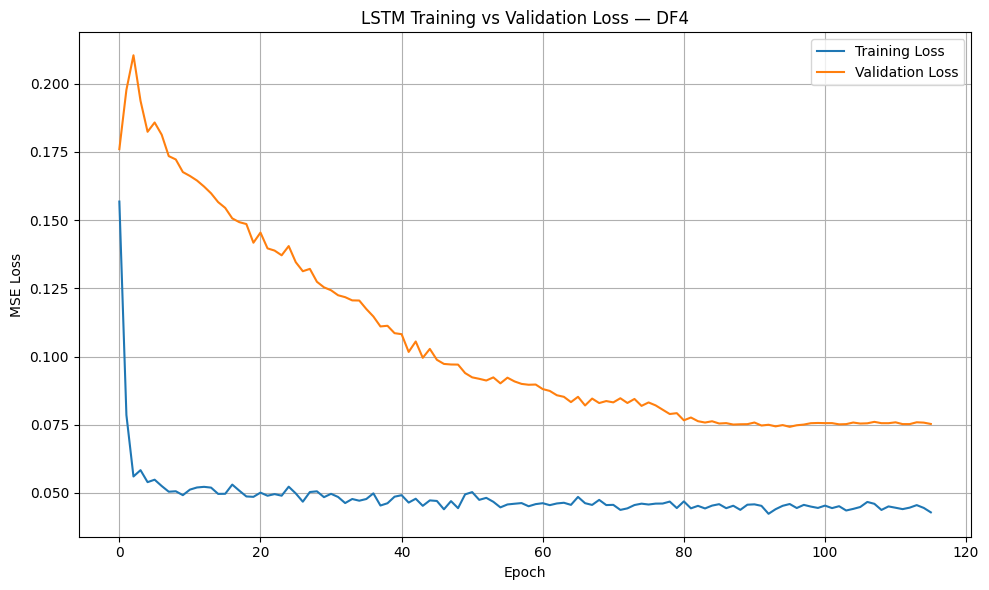

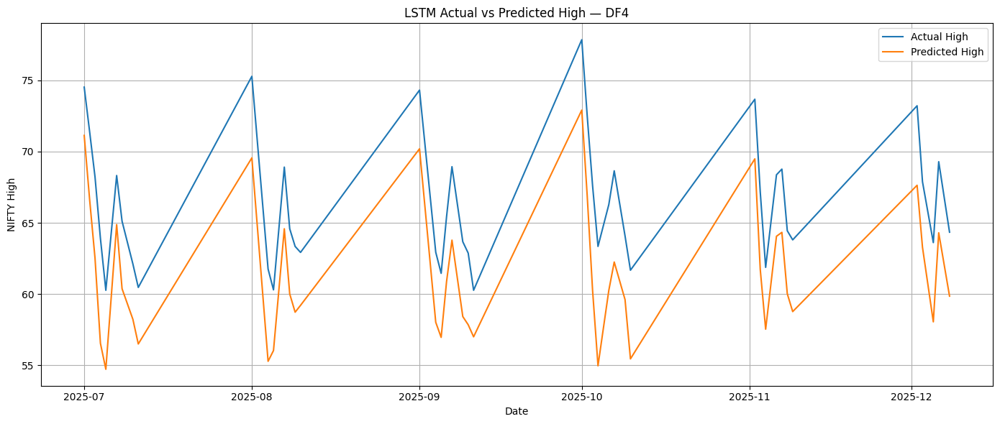

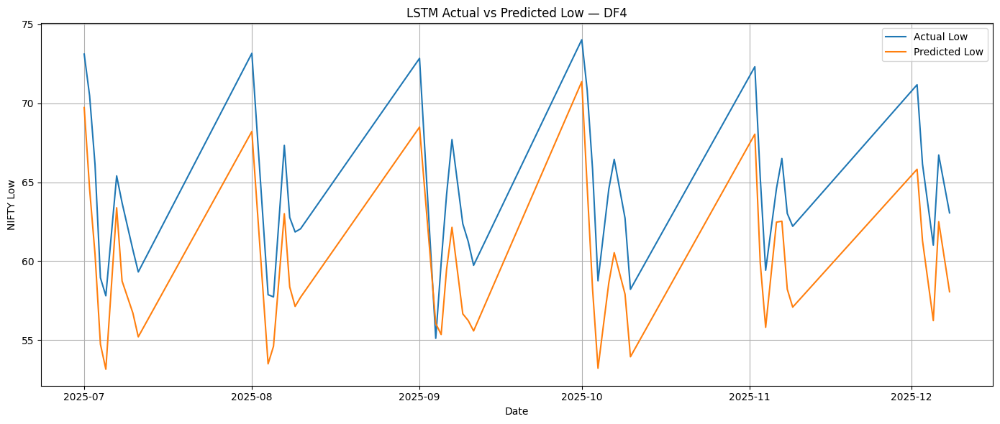

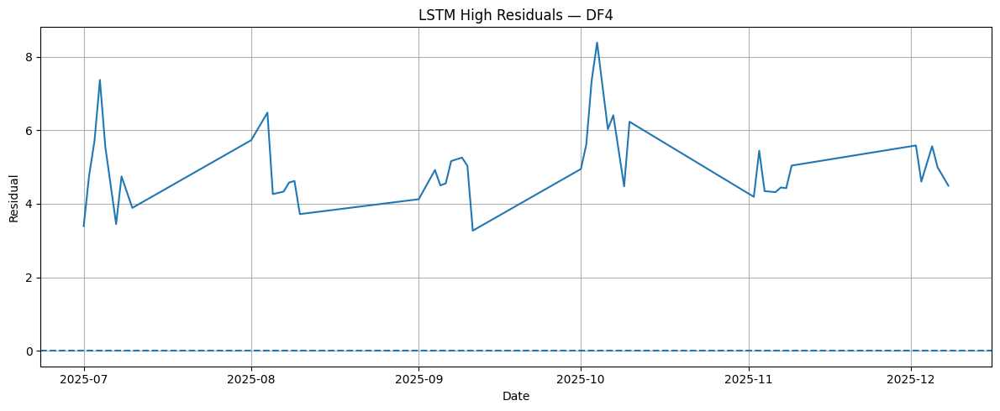

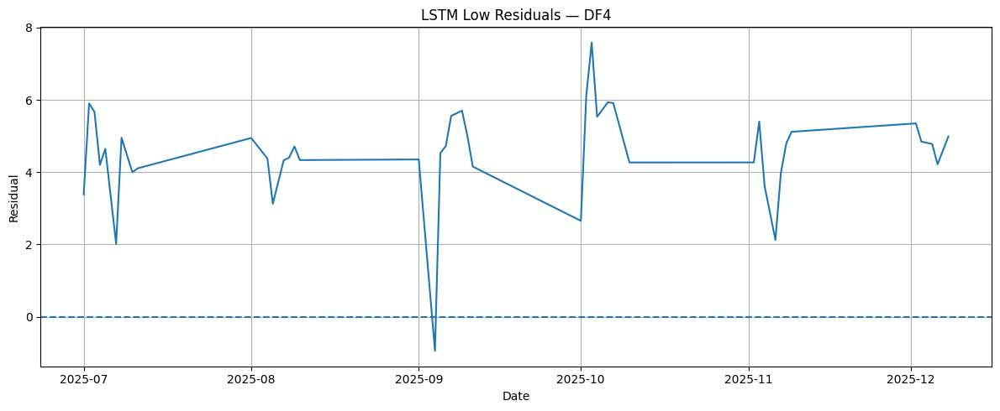

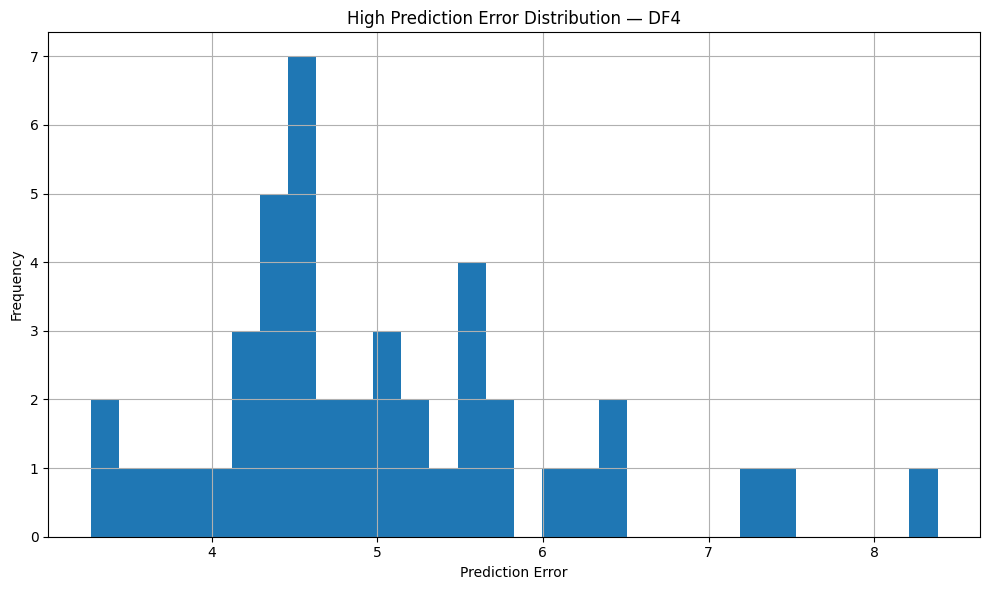

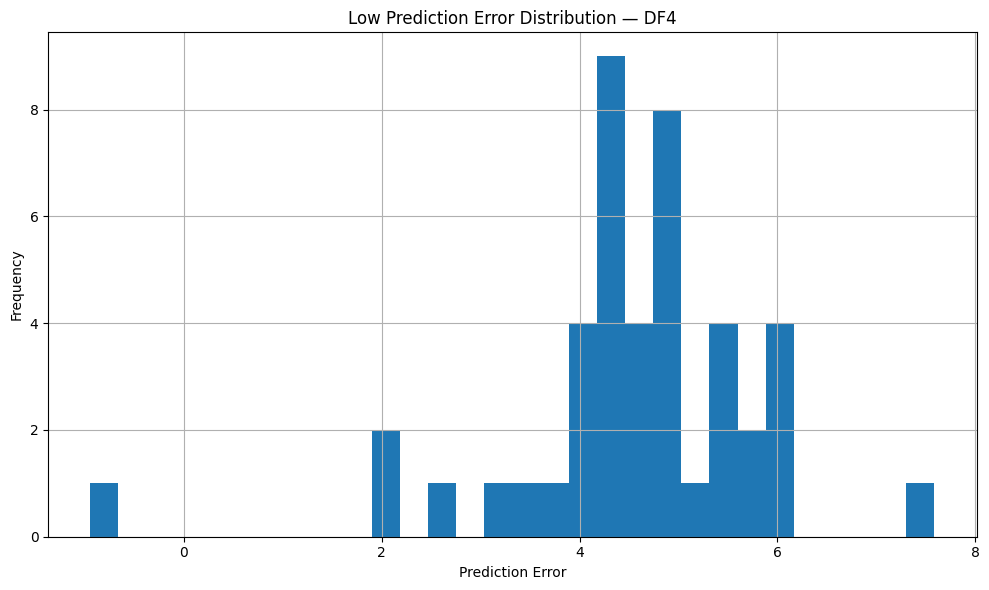


DF4 completed.


FINAL REGIME-WISE LSTM RESULTS
Regime  High_MAE  High_RMSE   High_R2  High_MAPE  Low_MAE  Low_RMSE   Low_R2  Low_MAPE  Train_Observations  Validation_Observations  Test_Observations
   DF1  3.535893   4.181438  0.768099   3.676067 3.798177  4.537913 0.732326  4.099583                 323                       75                 75
   DF2  0.858282   0.996022  0.965696   1.461081 0.782242  0.991464 0.967541  1.411290                 530                      119                119
   DF3  2.139994   3.686658  0.925984   2.125937 1.982614  2.683377 0.949116  2.093567                 182                       45                 45
   DF4  5.005091   5.116129 -0.270161   7.578329 4.553822  4.699481 0.046080  7.102317                 175                       43                 44

Results saved to:
LSTM_Regime_Results


In [7]:
# ============================================================
# NIFTY 50 — REGIME-WISE LSTM
# DF1: 2007-2010
# DF2: 2011-2019
# DF3: 2020-2021
# DF4: 2022-Latest
#
# Each regime is trained and evaluated independently.
# Target:
#   Next-Day High / Current-Day Close
#   Next-Day Low  / Current-Day Close
#
# Split:
#   70% Train
#   15% Validation
#   15% Test
#
# Lookback:
#   25 trading days
# ============================================================

import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout


# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except:
    pass



LOOKBACK = 25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 200
BATCH_SIZE = 32

OUTPUT_DIR = "LSTM_Regime_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Seed:", SEED)


# ============================================================
# 2. LOAD DATA
# ============================================================


print("Original shape:", df.shape)

# ------------------------------------------------------------
# Find date column
# ------------------------------------------------------------

possible_date_columns = [
    "Date",
    "date",
    "DATE",
    "Datetime",
    "datetime"
]

date_column = None

for col in possible_date_columns:
    if col in df.columns:
        date_column = col
        break

if date_column is None:
    raise ValueError(
        "Could not find Date column. "
        "Available columns are:\n"
        + str(df.columns.tolist())
    )

df[date_column] = pd.to_datetime(df[date_column], errors="coerce")

df = df.dropna(subset=[date_column])

df = df.sort_values(date_column).reset_index(drop=True)


# ============================================================
# 3. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Open",
    "High",
    "Low",
    "Close"
]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )


# ============================================================
# 4. CLEAN NUMERIC DATA
# ============================================================

for col in required_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=required_columns
).reset_index(drop=True)


# ============================================================
# 5. DEFINE REGIMES
# ============================================================

df["Year"] = df[date_column].dt.year

regimes = {

    "DF1": {
        "start": 2007,
        "end": 2011
    },

    "DF2": {
        "start": 2012,
        "end": 2019
    },

    "DF3": {
        "start": 2020,
        "end": 2022
    },

    "DF4": {
        "start": 2023,
        "end": df["Year"].max()
    }
}


# ============================================================
# 6. MODEL FUNCTION
# ============================================================

def build_lstm():

    
    model = Sequential([
    Bidirectional(
        LSTM(64, return_sequences=True),
        input_shape=(LOOKBACK, 4)
    ),
    Dropout(0.20),

    Bidirectional(
        LSTM(32)
    ),
    Dropout(0.20),

    Dense(16, activation="relu"),
    Dense(2)
])    

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model


# ============================================================
# 7. METRICS FUNCTION
# ============================================================

def calculate_metrics(
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    # Avoid division by zero
    denominator = np.where(
        np.abs(actual) < 1e-8,
        1e-8,
        np.abs(actual)
    )

    mape = np.mean(
        np.abs(
            (actual - predicted)
            / denominator
        )
    ) * 100

    return mae, rmse, r2, mape


# ============================================================
# 8. STORE ALL RESULTS
# ============================================================

all_results = []


# ============================================================
# 9. RUN EACH REGIME SEPARATELY
# ============================================================

for regime_name, period in regimes.items():

    print("\n")
    print("=" * 70)
    print(f"RUNNING {regime_name}")
    print(
        f"{period['start']} - {period['end']}"
    )
    print("=" * 70)


    # --------------------------------------------------------
    # Extract regime
    # --------------------------------------------------------

    regime_df = df[
        (df["Year"] >= period["start"]) &
        (df["Year"] <= period["end"])
    ].copy()

    regime_df = regime_df.reset_index(drop=True)

    print(
        "Regime observations:",
        len(regime_df)
    )


    # --------------------------------------------------------
    # Check enough data
    # --------------------------------------------------------

    if len(regime_df) <= LOOKBACK + 20:

        print(
            f"Skipping {regime_name}: "
            f"insufficient observations."
        )

        continue


    # --------------------------------------------------------
    # FEATURES
    #
    # We use OHLC from the previous 25 days.
    # --------------------------------------------------------

    features = [
        "Open",
        "High",
        "Low",
        "Close"
    ]

    X_raw = regime_df[
        features
    ].values


    # --------------------------------------------------------
    # TARGET
    #
    # Next-day High / current Close
    # Next-day Low  / current Close
    #
    # y[i] corresponds to day i+1.
    # --------------------------------------------------------

    high_target = (
        regime_df["High"].shift(-1)
        / regime_df["Close"]
    )

    low_target = (
        regime_df["Low"].shift(-1)
        / regime_df["Close"]
    )

    y_raw = np.column_stack([
        high_target.values,
        low_target.values
    ])


    # --------------------------------------------------------
    # Remove final row because it has no next-day target
    # --------------------------------------------------------

    valid_mask = ~np.isnan(y_raw).any(axis=1)

    X_raw = X_raw[valid_mask]
    y_raw = y_raw[valid_mask]

    close_current = regime_df[
        "Close"
    ].values[valid_mask]

    dates = regime_df[
        date_column
    ].values[valid_mask]


    # ========================================================
    # 10. CHRONOLOGICAL SPLIT
    # ========================================================

    n = len(X_raw)

    train_end = int(
        n * TRAIN_RATIO
    )

    val_end = int(
        n * (TRAIN_RATIO + VAL_RATIO)
    )

    print(
        "Train:",
        train_end
    )

    print(
        "Validation:",
        val_end - train_end
    )

    print(
        "Test:",
        n - val_end
    )


    # ========================================================
    # 11. SCALE — TRAIN ONLY
    # ========================================================

    scaler_X = MinMaxScaler()

    scaler_y = MinMaxScaler()


    scaler_X.fit(
        X_raw[:train_end]
    )

    scaler_y.fit(
        y_raw[:train_end]
    )


    X_scaled = scaler_X.transform(
        X_raw
    )

    y_scaled = scaler_y.transform(
        y_raw
    )


    # ========================================================
    # 12. CREATE SEQUENCES
    # ========================================================

    X_sequences = []
    y_sequences = []
    sequence_indices = []

    for i in range(
        LOOKBACK,
        len(X_scaled)
    ):

        X_sequences.append(
            X_scaled[
                i - LOOKBACK:i
            ]
        )

        y_sequences.append(
            y_scaled[i]
        )

        sequence_indices.append(i)


    X_sequences = np.array(
        X_sequences
    )

    y_sequences = np.array(
        y_sequences
    )

    sequence_indices = np.array(
        sequence_indices
    )


    # ========================================================
    # 13. SPLIT SEQUENCES
    # ========================================================

    train_mask = (
        sequence_indices < train_end
    )

    val_mask = (
        (sequence_indices >= train_end) &
        (sequence_indices < val_end)
    )

    test_mask = (
        sequence_indices >= val_end
    )


    X_train = X_sequences[
        train_mask
    ]

    y_train = y_sequences[
        train_mask
    ]

    X_val = X_sequences[
        val_mask
    ]

    y_val = y_sequences[
        val_mask
    ]

    X_test = X_sequences[
        test_mask
    ]

    y_test = y_sequences[
        test_mask
    ]


    print(
        "X_train:",
        X_train.shape
    )

    print(
        "X_val:",
        X_val.shape
    )

    print(
        "X_test:",
        X_test.shape
    )


    # ========================================================
    # 14. BUILD MODEL
    # ========================================================

    model = build_lstm()

    model.summary()


    # ========================================================
    # 15. CALLBACKS
    # ========================================================

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=20,

        restore_best_weights=True,

        verbose=1
    )


    reduce_lr = ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=8,

        min_lr=1e-6,

        verbose=1
    )


    # ========================================================
    # 16. TRAIN
    # ========================================================

    history = model.fit(

        X_train,

        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        shuffle=False,

        callbacks=[
            early_stopping,
            reduce_lr
        ],

        verbose=1
    )


    # ========================================================
    # 17. PREDICT TEST
    # ========================================================

    y_pred_scaled = model.predict(
        X_test,
        verbose=0
    )


    # ========================================================
    # 18. INVERSE TRANSFORM
    # ========================================================

    y_pred_ratio = scaler_y.inverse_transform(
        y_pred_scaled
    )

    y_test_ratio = scaler_y.inverse_transform(
        y_test
    )


    # ========================================================
    # 19. GET TEST CLOSE VALUES
    # ========================================================

    test_indices = sequence_indices[
        test_mask
    ]

    test_close = close_current[
        test_indices
    ]

    test_dates = dates[
        test_indices
    ]


    # ========================================================
    # 20. RECONSTRUCT ABSOLUTE HIGH / LOW
    # ========================================================

    predicted_high = (
        y_pred_ratio[:, 0]
        * test_close
    )

    predicted_low = (
        y_pred_ratio[:, 1]
        * test_close
    )


    actual_high = regime_df[
        "High"
    ].values[test_indices]

    actual_low = regime_df[
        "Low"
    ].values[test_indices]


    # ========================================================
    # 21. METRICS
    # ========================================================

    high_mae, high_rmse, high_r2, high_mape = \
        calculate_metrics(
            actual_high,
            predicted_high
        )


    low_mae, low_rmse, low_r2, low_mape = \
        calculate_metrics(
            actual_low,
            predicted_low
        )


    print("\n")
    print("=" * 60)
    print(f"{regime_name} RESULTS")
    print("=" * 60)

    print("\nHIGH")
    print(
        f"MAE  : {high_mae:.4f}"
    )
    print(
        f"RMSE : {high_rmse:.4f}"
    )
    print(
        f"R²   : {high_r2:.4f}"
    )
    print(
        f"MAPE : {high_mape:.4f}%"
    )

    print("\nLOW")
    print(
        f"MAE  : {low_mae:.4f}"
    )
    print(
        f"RMSE : {low_rmse:.4f}"
    )
    print(
        f"R²   : {low_r2:.4f}"
    )
    print(
        f"MAPE : {low_mape:.4f}%"
    )


    # ========================================================
    # 22. SAVE METRICS
    # ========================================================

    all_results.append({

        "Regime": regime_name,

        "High_MAE": high_mae,
        "High_RMSE": high_rmse,
        "High_R2": high_r2,
        "High_MAPE": high_mape,

        "Low_MAE": low_mae,
        "Low_RMSE": low_rmse,
        "Low_R2": low_r2,
        "Low_MAPE": low_mape,

        "Train_Observations": len(X_train),

        "Validation_Observations": len(X_val),

        "Test_Observations": len(X_test)
    })


    # ========================================================
    # 23. SAVE PREDICTIONS
    # ========================================================

    prediction_df = pd.DataFrame({

        "Date": test_dates,

        "Actual_High":
            actual_high,

        "Predicted_High":
            predicted_high,

        "Actual_Low":
            actual_low,

        "Predicted_Low":
            predicted_low,

        "Actual_High_Ratio":
            y_test_ratio[:, 0],

        "Predicted_High_Ratio":
            y_pred_ratio[:, 0],

        "Actual_Low_Ratio":
            y_test_ratio[:, 1],

        "Predicted_Low_Ratio":
            y_pred_ratio[:, 1],

        "Close_t":
            test_close
    })


    prediction_path = os.path.join(
        OUTPUT_DIR,
        f"{regime_name}_Predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    # ========================================================
    # 24. TRAINING / VALIDATION LOSS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")

    plt.title(
        f"LSTM Training vs Validation Loss — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Loss.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 25. ACTUAL VS PREDICTED — HIGH
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_high,
        label="Actual High"
    )

    plt.plot(
        test_dates,
        predicted_high,
        label="Predicted High"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY High")

    plt.title(
        f"LSTM Actual vs Predicted High — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 26. ACTUAL VS PREDICTED — LOW
    # ========================================================

    plt.figure(
        figsize=(14, 6)
    )

    plt.plot(
        test_dates,
        actual_low,
        label="Actual Low"
    )

    plt.plot(
        test_dates,
        predicted_low,
        label="Predicted Low"
    )

    plt.xlabel("Date")

    plt.ylabel("NIFTY Low")

    plt.title(
        f"LSTM Actual vs Predicted Low — {regime_name}"
    )

    plt.legend()

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Actual_vs_Predicted.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 27. HIGH RESIDUALS
    # ========================================================

    high_residuals = (
        actual_high -
        predicted_high
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        high_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM High Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 28. LOW RESIDUALS
    # ========================================================

    low_residuals = (
        actual_low -
        predicted_low
    )

    plt.figure(
        figsize=(12, 5)
    )

    plt.plot(
        test_dates,
        low_residuals
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Date")

    plt.ylabel("Residual")

    plt.title(
        f"LSTM Low Residuals — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Residuals.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 29. ERROR DISTRIBUTIONS
    # ========================================================

    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        high_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"High Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_High_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    plt.figure(
        figsize=(10, 6)
    )

    plt.hist(
        low_residuals,
        bins=30
    )

    plt.xlabel("Prediction Error")

    plt.ylabel("Frequency")

    plt.title(
        f"Low Prediction Error Distribution — {regime_name}"
    )

    plt.grid(True)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_Low_Error_Distribution.png"
        ),
        dpi=300
    )

    plt.show()


    # ========================================================
    # 30. SAVE MODEL
    # ========================================================

    model.save(
        os.path.join(
            OUTPUT_DIR,
            f"{regime_name}_LSTM.keras"
        )
    )

    print(
        f"\n{regime_name} completed."
    )


# ============================================================
# 31. FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    all_results
)

print("\n")
print("=" * 80)
print("FINAL REGIME-WISE LSTM RESULTS")
print("=" * 80)

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# 32. SAVE FINAL RESULTS
# ============================================================

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.csv"
    ),
    index=False
)

results_df.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "LSTM_Regime_Results.xlsx"
    ),
    index=False
)


print("\nResults saved to:")
print(OUTPUT_DIR)

In [ ]:
special_chars = """!"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~"""
def create_special_encrypt_dict(k):
    encrypt_dict = {}
    for i in range(len(special_chars)):
        encrypt_dict[special_chars[i]] = special_chars[
            (i + k) % len(special_chars)
        ]
    return encrypt_dict
def create_special_decrypt_dict(k):
    decrypt_dict = {}
    for i in range(len(special_chars)):
        decrypt_dict[special_chars[i]] = special_chars[
            (i - k) % len(special_chars)
        ]
    return decrypt_dict
def caesar_encrypt(text, k=3):
    result = ""
    special_dict = create_special_encrypt_dict(k)
    for ch in text:
        if ch.isalpha():
            base = ord('A') if ch.isupper() else ord('a')
            result += chr((ord(ch) - base + k) % 26 + base)
        elif ch.isdigit():
            result += str((int(ch) + k) % 10)
        elif ch == ' ':
            continue
        elif ch in special_dict:
            result += special_dict[ch]
    return result
def caesar_decrypt(text, k=3):
    result = ""
    special_dict = create_special_decrypt_dict(k)
    for ch in text:
        if ch.isalpha():
            base = ord('A') if ch.isupper() else ord('a')
            result += chr((ord(ch) - base - k) % 26 + base)
        elif ch.isdigit():
            result += str((int(ch) - k) % 10)
        elif ch == ' ':
            continue
        elif ch in special_dict:
            result += special_dict[ch]
    return result
def mono_encrypt(text):
    clean_text = ''.join(
        ch.lower() for ch in text if ch.isalpha()
    )
    k = len(clean_text)
    shift = k % 26
    encrypted = ""
    special_dict = create_special_encrypt_dict(k)
    for ch in text:
        if ch.isalpha():
            base = ord('A') if ch.isupper() else ord('a')
            encrypted += chr(
                (ord(ch) - base + shift) % 26 + base
            )
        elif ch.isdigit():
            encrypted += str((int(ch) + k) % 10)
        elif ch == ' ':
            continue
        elif ch in special_dict:
            encrypted += special_dict[ch]
    return clean_text, k, encrypted
def mono_decrypt(text):
    clean_text = ''.join(
        ch.lower() for ch in text if ch.isalpha()
    )
    k= len(clean_text)             # k = int(input("Enter k (length of original cleaned text): "))
    shift = k % 26
    decrypted = ""
    special_dict = create_special_decrypt_dict(k)
    for ch in text:
        if ch.isalpha():
            base = ord('A') if ch.isupper() else ord('a')
            decrypted += chr(
                (ord(ch) - base - shift) % 26 + base
            )
        elif ch.isdigit():
            decrypted += str((int(ch) - k) % 10)
        elif ch == ' ':
            continue
        elif ch in special_dict:
            decrypted += special_dict[ch]
    return clean_text, k, decrypted
while True:
    print("\n1. Caesar Cipher Encryption")
    print("2. Caesar Cipher Decryption")
    print("3. Monoalphabetic Encryption")
    print("4. Monoalphabetic Decryption")
    print("5. Exit")
    choice = input("\nEnter your choice: ")
    if choice == "1":
        text = input("Enter plaintext: ")
        encrypted = caesar_encrypt(text, 3)
        print("\nOriginal Text :", text)
        print("Key (k)       : 3")
        print("Encrypted Text:", encrypted)
    elif choice == "2":
        text = input("Enter ciphertext: ")
        decrypted = caesar_decrypt(text, 3)
        print("\nCiphertext     :", text)
        print("Key (k)        : 3")
        print("Decrypted Text :", decrypted)
    elif choice == "3":
        text = input("Enter plaintext: ")
        clean_text, k, encrypted = mono_encrypt(text)
        print("\nOriginal Text :", text)
        print("Clean Text    :", clean_text)
        print("Key (k)       :", k)
        print("Encrypted Text:", encrypted)
    elif choice == "4":
        text = input("Enter ciphertext: ")
        clean_text, k, decrypted = mono_decrypt(text)
        print("\nCiphertext     :", text)
        print("Key (k)        :", k)
        print("Decrypted Text :", decrypted)
    elif choice == "5":
        print("\nProgram terminated.")
        break
    else:
        print("\nInvalid choice! Please select 1-5.")


1. Caesar Cipher Encryption
2. Caesar Cipher Decryption
3. Monoalphabetic Encryption
4. Monoalphabetic Decryption
5. Exit

Original Text : 4
Key (k)       : 3
Encrypted Text: 7

1. Caesar Cipher Encryption
2. Caesar Cipher Decryption
3. Monoalphabetic Encryption
4. Monoalphabetic Decryption
5. Exit

Original Text : 3
Clean Text    : 
Key (k)       : 0
Encrypted Text: 3

1. Caesar Cipher Encryption
2. Caesar Cipher Decryption
3. Monoalphabetic Encryption
4. Monoalphabetic Decryption
5. Exit

Original Text : Syed$Muneer^Husain*Kazmi
Key (k)       : 3
Encrypted Text: Vbhg'Pxqhhu{Kxvdlq-Ndcpl

1. Caesar Cipher Encryption
2. Caesar Cipher Decryption
3. Monoalphabetic Encryption
4. Monoalphabetic Decryption
5. Exit

Original Text : Syed$Muneer^Husain*Kazmi
Clean Text    : syedmuneerhusainkazmi
Key (k)       : 21
Encrypted Text: Ntzy]Hpizzm/Cpnvdi}Fvuhd

1. Caesar Cipher Encryption
2. Caesar Cipher Decryption
3. Monoalphabetic Encryption
4. Monoalphabetic Decryption
5. Exit


In [ ]:
# Research review: Tuning/regime variants can differ from final.1. Record exact years, validation metric, trial budget and whether validation targets or test data influenced final fitting. The independent baseline is not a rerun of this model.
